In [1]:
import pandas as pd
import numpy as np

In [2]:
# IMPORTAR BASE DE DATOS 
df = pd.read_excel(r'../data/raw/copy_dbsirima_v3.xlsx', header=1, engine='calamine')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 43 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   ID BD SINKHOLE                                  1814 non-null   object 
 1   Name                                            1414 non-null   object 
 2   ID Sinkhole                                     1395 non-null   object 
 3   Coordinate
X                                    1814 non-null   float64
 4   Coordinate
Y                                    1814 non-null   float64
 5   Projected Coordinate System                     1814 non-null   object 
 6   X_WGS84                                         1814 non-null   float64
 7   Y_WGS84                                         1814 non-null   float64
 8   Measurement uncertainty (m)                     390 non-null    object 
 9   Name of the mine                         

In [4]:
# LIMPIAR NOMBRE DE COLUMNAS
def clean_col_names(df):
    """Limpia los nombres de las columnas (minúsculas, sin espacios, sin caracteres especiales)."""
    cols = []
    for col in df.columns:
        # Reemplazar espacios y caracteres especiales por un guion bajo
        clean_name = col.lower().replace(' ', '_').replace('/', '_').replace('(', '').replace(')', '').replace('%', 'pct').replace('.', '').replace('m²', 'm2')
        # Eliminar guiones bajos duplicados
        while '__' in clean_name:
            clean_name = clean_name.replace('__', '_')
        # Limpiar el guion bajo inicial o final
        clean_name = clean_name.strip('_')
        cols.append(clean_name)
    df.columns = cols
    return df

df = clean_col_names(df.copy())

In [5]:
df.iloc[:, 19:].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 24 columns):
 #   Column                                        Non-Null Count  Dtype 
---  ------                                        --------------  ----- 
 0   uncertainty_of_date
years                     909 non-null    object
 1   origin_of_collapse                            1792 non-null   object
 2   similar_phenomena_known_nearby                1799 non-null   object
 3   start_date_of_the_mining                      1784 non-null   object
 4   end_date_of_the_mining                        1804 non-null   object
 5   accuracy_of_date                              400 non-null    object
 6   dip_of_the_exploited_layer_degree             1603 non-null   object
 7   type_of_mining_work_shaft_cavity-drift        1771 non-null   object
 8   width_diameter                                455 non-null    object
 9   working_thickness_shaft_deep                  1487 non-null   object
 10  

In [6]:
# ELIMINAR VARIABLES CON < 40% DE DATOS
# 1. Definimos la "Lista Negra" de variables

cols_to_drop = [
    # Escasez extrema
    'impacted_surface_m2', 
    'width_m', 
    'measurement_uncertainty_m',
    "uncertainty_of_date_years",
    "accuracy_of_date",
    "width_diameter",
    "void_density",
    "uncertainity_m",
    "ground_support",
    "roof_fracture_condition",
    "damage_observed",
    "observations",

    # Redundancia Espacial (Nos quedamos con WGS84)
    'coordinate_x', 
    'coordinate_y', 
    'projected_coordinate_system'
]

# Verificamos que existan antes de borrar para evitar errores
cols_to_drop_final = [c for c in cols_to_drop if c in df.columns]

# 2. Eliminamos
df_clean = df.drop(columns=cols_to_drop_final)


In [7]:
df_clean.columns.tolist()

['id_bd_sinkhole',
 'name',
 'id_sinkhole',
 'coordinate\nx',
 'coordinate\ny',
 'x_wgs84',
 'y_wgs84',
 'name_of_the_mine',
 'country',
 'municipality',
 'number_of_sinkholes',
 'length_diameter_m',
 'depth_of_the_sinkhole_m',
 'in-situ_measurement_or_estimation',
 'date_of_appearance_of_the_sinkhole',
 'uncertainty_of_date\nyears',
 'origin_of_collapse',
 'similar_phenomena_known_nearby',
 'start_date_of_the_mining',
 'end_date_of_the_mining',
 'dip_of_the_exploited_layer_degree',
 'type_of_mining_work_shaft_cavity-drift',
 'working_thickness_shaft_deep',
 'depth_of_the_drift_relative_to_the_surface_m',
 'accessibility',
 'geology_of_the_overburden',
 'material_overbuden_resistance',
 'water_conditions_in_the_minig_work',
 'presence_of_an_aquifer_in_the_overburden',
 'presence_of_buildings_or_infrastructure',
 'bibliographic_references']

In [8]:
# ESCOJER UN DATASET DE LA BASE DE DATOS FILTRADA
cols = ["id_bd_sinkhole",
        "x_wgs84",
        "y_wgs84",
        "number_of_sinkholes",
        "length_diameter_m",
        "depth_of_the_sinkhole_m",
        "in-situ_measurement_or_estimation",
        "date_of_appearance_of_the_sinkhole",
        "origin_of_collapse",
        "start_date_of_the_mining",
        "end_date_of_the_mining",
        "dip_of_the_exploited_layer_degree",
        "working_thickness_shaft_deep",
        "depth_of_the_drift_relative_to_the_surface_m",
        "material_overbuden_resistance",
        "geology_of_the_overburden",
        "presence_of_buildings_or_infrastructure"
        ]

#Creamos un df nuevo
df_risk = df_clean[cols].copy()


In [9]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 17 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   x_wgs84                                       1814 non-null   float64
 2   y_wgs84                                       1814 non-null   float64
 3   number_of_sinkholes                           1807 non-null   object 
 4   length_diameter_m                             1672 non-null   object 
 5   depth_of_the_sinkhole_m                       1590 non-null   object 
 6   in-situ_measurement_or_estimation             1623 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object 
 8   origin_of_collapse                            1792 non-null   object 
 9   start_date_of_the_mining                      1784 non-null   o

## LMPIEZA DE VARIABLES CONDICIONANTES

### 1. MATERIAL OVERBURDEN RESISTANCE

In [10]:
df_risk.material_overbuden_resistance.unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [11]:
# IMPUTACION GEOLOGICA
# Imputacion de variable material_overburden_resistance usando geology_of_the_overburden

# 1. Limpieza preliminar de texto para evitar errores de mayúsculas/espacios
df_risk['geo_clean'] = df_risk['geology_of_the_overburden'].astype(str).str.lower().str.strip()
df_risk['res_clean'] = df_risk['material_overbuden_resistance'].astype(str).str.lower().str.strip()

# --- PASO A: Convertir la columna original de Resistencia a Números ---
existing_res_map = {
    'weakly resistant': 1,
    'powdery': 1,
    'mildly resistant': 2,
    'oderate to high resistance due to compacted layers, but water inflows were significant in early year': 2,
    'highly resistant': 3,
    'resistant': 3,
    'nan': np.nan,
    'unknown': np.nan
}

df_risk['resistance_numeric'] = df_risk['res_clean'].map(existing_res_map)


In [12]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 20 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   x_wgs84                                       1814 non-null   float64
 2   y_wgs84                                       1814 non-null   float64
 3   number_of_sinkholes                           1807 non-null   object 
 4   length_diameter_m                             1672 non-null   object 
 5   depth_of_the_sinkhole_m                       1590 non-null   object 
 6   in-situ_measurement_or_estimation             1623 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object 
 8   origin_of_collapse                            1792 non-null   object 
 9   start_date_of_the_mining                      1784 non-null   o

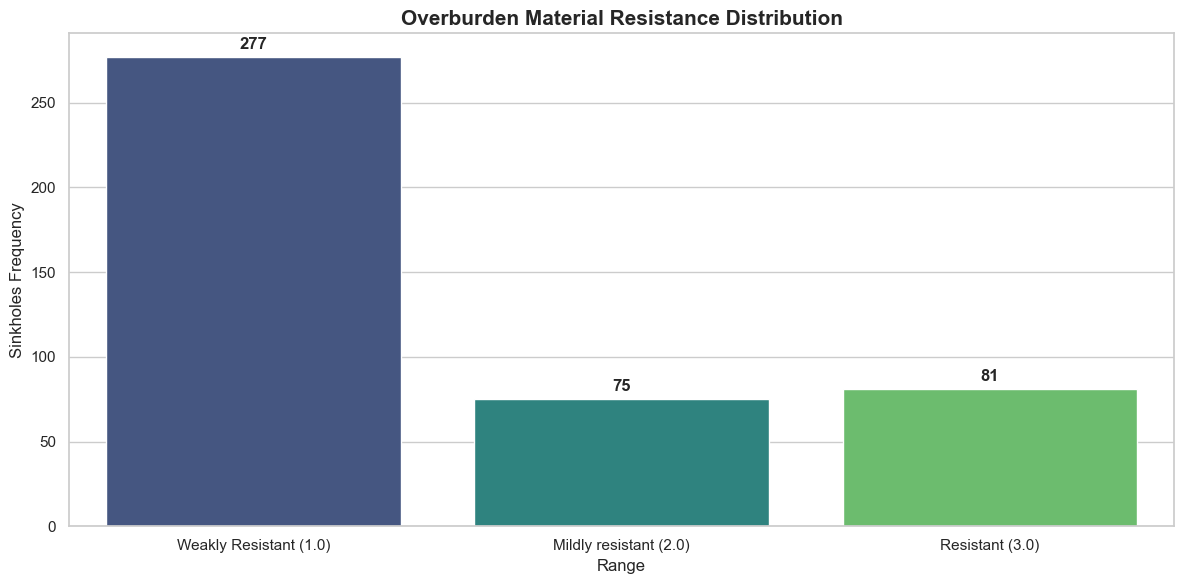


--- RESUMEN DE RESISTENCIA ---
   Resistencia  Frecuencia
0          1.0         277
1          2.0          75
2          3.0          81


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar los datos para el gráfico
# Contamos las frecuencias de cada clase de resistencia (1.0, 2.0, 3.0)
df_res_plot = df_risk['resistance_numeric'].value_counts().sort_index().reset_index()
df_res_plot.columns = ['Resistencia', 'Frecuencia']

# Mapeamos a etiquetas descriptivas para una mejor interpretación geológica
labels_map = {
    1.0: 'Weakly Resistant (1.0)',
    2.0: 'Mildly resistant (2.0)',
    3.0: 'Resistant (3.0)'
}
df_res_plot['Descripción'] = df_res_plot['Resistencia'].map(labels_map)

# 2. Crear la visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Usamos 'Descripción' como hue para evitar el Future Warning
ax = sns.barplot(
    x='Descripción', 
    y='Frecuencia', 
    data=df_res_plot, 
    hue='Descripción', 
    palette='viridis', 
    legend=False
)

# Añadir etiquetas de conteo sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), 
                textcoords='offset points', fontweight='bold')

plt.title('Overburden Material Resistance Distribution', fontsize=15, fontweight='bold')
plt.ylabel('Sinkholes Frequency', fontsize=12)
plt.xlabel('Range', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mostrar tabla de resumen
print("\n--- RESUMEN DE RESISTENCIA ---")
print(df_res_plot[['Resistencia', 'Frecuencia']])

In [14]:
df_risk["material_overbuden_resistance"].unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [15]:
# --- PASO B: Verificar la relacion entre geology_of_the_overburden y material_overburden_resistance ---

# 1. Preparamos un DataFrame temporal solo para el análisis
df_analisis = df_risk.copy()

# 2. Estandarizamos la Resistencia para agrupar el "ruido"
# Usamos el mapeo que ya verificamos antes para tener 3 grupos claros
mapa_estandar = {
    'weakly resistant': '1_BAJA',
    'powdery': '1_BAJA',
    
    'mildly resistant': '2_MEDIA',
    'moderately resistant': '2_MEDIA',
    'medium': '2_MEDIA',
    'oderate to high resistance due to compacted layers, but water inflows were significant in early years': '2_MEDIA',
    
    'resistant': '3_ALTA',
    'highly resistant': '3_ALTA'
}

# Crear nivel de resistencia cualitativa de los materiales overburden
df_analisis['nivel_resistencia'] = df_analisis['material_overbuden_resistance'].str.lower().str.strip().map(mapa_estandar)

# 3. Seleccionamos solo las filas que tienen nivel de resistencia junto con litologia para la imputacion
grupos = df_analisis.dropna(subset=['nivel_resistencia', 'geology_of_the_overburden'])

print(f"Analizando {len(grupos)} coincidencias encontradas...\n")

#Iteramos para cada nivel de resistencia y contabilizamos la frecuencia de cada nivel 
for nivel in sorted(grupos['nivel_resistencia'].unique()):
    print(f"=== ROCAS CLASIFICADAS COMO: {nivel} ===")
    # Mostramos las 15 descripciones geológicas más frecuentes en cada grupo
    top_geo = grupos[grupos['nivel_resistencia'] == nivel]['geology_of_the_overburden'].value_counts().head(15)
    print(top_geo)
    print("-" * 100 + "\n")


print(f"=== TOTAL DE ROCAS CLASIFICADAS POR: {grupos['nivel_resistencia'].value_counts().sort_index()}")

Analizando 434 coincidencias encontradas...

=== ROCAS CLASIFICADAS COMO: 1_BAJA ===
geology_of_the_overburden
Carboniferous sandstone and shale                                                                            60
Middle Stephanian - Puddingstone, clayey-silty sandstone                                                     53
Permian sandstone. Triassic clays and sandstone                                                              46
Molasse and sands                                                                                            36
Permian sandstone and shale                                                                                  32
Coalfields (conglomerates, sandstones, shales) locally topped with clayey sand of Eocene Age and alluvium    23
Labradorite then Carboniferous sandstone and shale                                                           11
Carboniferous levels with predominantly conglomeratic, sandstone or schistose facies                     

In [16]:
# ANALISIS DE PALABRAS CLAVE (ANALISIS DE FRECUENCIA)
# Vamos a ver qué palabras dominan matemáticamente en cada grupo
print("=== PALABRAS CLAVE DOMINANTES (Análisis de Frecuencia) ===")
keywords = ['sandstone', 
            'shale', 
            'clay', 
            'carboniferous', 
            'limestone', 
            'sand', 
            'coal', 
            'conglomerates'
            ]

result = []
for word in keywords:
    row = {'Keyword': word}
    for nivel in ['1_BAJA', '2_MEDIA', '3_ALTA']:
        # Filtramos el grupo
        subset = grupos[grupos['nivel_resistencia'] == nivel]
        # Contamos cuántas veces aparece la palabra en ese grupo
        count = subset['geology_of_the_overburden'].str.lower().str.contains(word).sum()
        row[nivel] = count
    result.append(row)

df_keywords = pd.DataFrame(result)
print(df_keywords)

#Conclusion: Realizar un analisis con palabras resulta un poco cimplicado porque muchas palabras se repiten en los 3 niveles de resistencia.
# Solo se puede notar que las descripciones que tengas limestone son puramente clasificadas como 3_ALTA

=== PALABRAS CLAVE DOMINANTES (Análisis de Frecuencia) ===
         Keyword  1_BAJA  2_MEDIA  3_ALTA
0      sandstone     241       76      63
1          shale     129       76      27
2           clay     122        1      25
3  carboniferous      84        0      31
4      limestone       0        0      17
5           sand     277       76      63
6           coal      23       59      11
7  conglomerates      23       75      11


In [17]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 20 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   x_wgs84                                       1814 non-null   float64
 2   y_wgs84                                       1814 non-null   float64
 3   number_of_sinkholes                           1807 non-null   object 
 4   length_diameter_m                             1672 non-null   object 
 5   depth_of_the_sinkhole_m                       1590 non-null   object 
 6   in-situ_measurement_or_estimation             1623 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object 
 8   origin_of_collapse                            1792 non-null   object 
 9   start_date_of_the_mining                      1784 non-null   o

In [18]:
df_risk["material_overbuden_resistance"].unique()

array(['weakly resistant', nan, 'powdery', 'resistant',
       'mildly resistant', 'highly resistant',
       'oderate to high resistance due to compacted layers, but water inflows were significant in early years',
       'unknown'], dtype=object)

In [19]:
# MODELO DE CLASIFICACION NO SUPERVISADA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

# --- 1. PREPARACIÓN DE DATOS ---
#Creamos una copia del df_risk con geology_of_the_overburden y material_overburden_resistance
df_ml = df_risk[["id_bd_sinkhole","geology_of_the_overburden", "material_overbuden_resistance", "resistance_numeric"]].copy()

#ELiminamos las descripciones litologicas con "unknown"
df_ml = df_ml[~df_ml["geology_of_the_overburden"].str.contains('unknow', case=False, na=False)]
df_ml = df_ml.reset_index(drop=True)

# Limpieza básica del texto
df_ml['text_for_ml'] = df_ml['geology_of_the_overburden'].astype(str).str.lower().str.strip()

# Mapeamos la resistencia conocida a números para poder calcular promedios después
res_map = {
    'weakly resistant': 1,
    'powdery': 1,
    'mildly resistant': 2,
    'oderate to high resistance due to compacted layers, but water inflows were significant in early year': 2,
    'resistant': 3,
    'highly resistant': 3,
    'nan': np.nan,
    'unknown': np.nan
}

df_ml['target_res'] = df_ml['material_overbuden_resistance'].map(res_map)

# --- 2. VECTORIZACIÓN (NLP) ---
# Convertimos texto a matriz numérica.
# min_df=5: Ignora palabras que aparezcan en menos de 5 filas (quita ruido/typos)
vectorizer = TfidfVectorizer(stop_words='english', min_df=4)
X_text = vectorizer.fit_transform(df_ml['text_for_ml'])

print(f"Matriz generada: {X_text.shape} (Filas x Palabras únicas)")

# --- 3. MODELADO (K-MEANS) ---
# Probamos con 4 clusters para capturar matices (ej. Arenisca pura vs Arenisca arcillosa)
n_clusters=4
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
df_ml['cluster'] = kmeans.fit_predict(X_text)

# --- 4. ANÁLISIS DE LOS CLUSTERS ---
print(f"\n--- ANÁLISIS DE LOS {n_clusters} GRUPOS (CLUSTERS) GENERADOS ---")
print("="*70)

# Para cada cluster, calculamos la resistencia promedio de los datos que SI tienen etiqueta
cluster_profile = df_ml.groupby('cluster')['target_res'].agg(['mean', 'count', lambda x: x.isnull().sum()])
cluster_profile.columns = ['Average_Resistance', 'Known_Data', 'Missing_Data']

# Agregamos las palabras clave principales de cada cluster para entender qué son
def get_top_keywords(data, cluster_id, vectorizer, n_terms=100):
    # Obtenemos las filas del cluster
    idx = data.index[data['cluster'] == cluster_id].tolist()
    # Calculamos el promedio de sus vectores TF-IDF
    mean_tfidf = X_text[idx].mean(axis=0).A1
    # Buscamos las palabras con mayor puntaje
    terms = vectorizer.get_feature_names_out()
    sorted_indices = mean_tfidf.argsort()[::-1]
    return ", ".join([terms[i] for i in sorted_indices[:n_terms]])

cluster_profile['Keywords'] = [get_top_keywords(df_ml, i, vectorizer) for i in range(n_clusters)]
cluster_profile

Matriz generada: (1421, 53) (Filas x Palabras únicas)

--- ANÁLISIS DE LOS 4 GRUPOS (CLUSTERS) GENERADOS ---


c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)


,Average_Resistance,Known_Data,Missing_Data,Keywords
cluster,,,,
0,1.000000,60,897,"shale, carboniferous, quaternary, sands, clays..."
1,1.869565,92,40,"shales, sandstones, coalfields, conglomerates,..."
2,1.000000,53,0,"stephanian, silty, puddingstone, middle, claye..."
3,1.688596,228,51,"permian, sandstone, triassic, molasse, shale, ..."


In [20]:
# --- 5. IMPUTACIÓN DE VALORES FALTANTES ---

# 1. Definimos las reglas de imputacion
# Tomamos el promedio calculado, lo redondeamos al entero más cercano y lo pasamos a diccionario
reglas_imputacion = cluster_profile['Average_Resistance'].round().astype(int).to_dict()

print("--- REGLAS DE IMPUTACIÓN GENERADAS (PROMEDIO REDONDEADO) ---")
for cluster_id, valor in reglas_imputacion.items():
    print(f"Cluster {cluster_id} -> Se imputará con Nivel {valor}")

# 2. Imputamos los valores faltantes
# Tomamos la columna original y llenamos los NaN mapeando el cluster a nuestra regla calculada.
df_ml['overburden_resistance_numeric'] = df_ml['resistance_numeric'].fillna(
    df_ml['cluster'].map(reglas_imputacion)
)

# 3. Verificamos cuántos datos hemos recuperado
nulos_antes = df_ml['resistance_numeric'].isnull().sum()
nulos_ahora = df_ml['overburden_resistance_numeric'].isnull().sum()
recuperados = nulos_antes - nulos_ahora

print(f"\n--- RESULTADO DE LA IMPUTACIÓN ---")
print(f"Datos faltantes originales: {nulos_antes}")
print(f"Datos faltantes actuales:   {nulos_ahora}")
print(f"¡Se han recuperado {recuperados} registros!\n")

# 4. Mapeamos a los niveles de texto finales (1_BAJA, 2_MEDIA, 3_ALTA)
mapa_niveles = {
    1: '1_BAJA',
    2: '2_MEDIA',
    3: '3_ALTA',
}

df_ml['resistencia_imputada'] = df_ml['overburden_resistance_numeric'].map(mapa_niveles)

# 5. Resumen Final
print("=== DISTRIBUCIÓN FINAL DE RESISTENCIAS (POST-IMPUTACIÓN) ===")
print(df_ml['resistencia_imputada'].value_counts().sort_index())


--- REGLAS DE IMPUTACIÓN GENERADAS (PROMEDIO REDONDEADO) ---
Cluster 0 -> Se imputará con Nivel 1
Cluster 1 -> Se imputará con Nivel 2
Cluster 2 -> Se imputará con Nivel 1
Cluster 3 -> Se imputará con Nivel 2

--- RESULTADO DE LA IMPUTACIÓN ---
Datos faltantes originales: 988
Datos faltantes actuales:   0
¡Se han recuperado 988 registros!

=== DISTRIBUCIÓN FINAL DE RESISTENCIAS (POST-IMPUTACIÓN) ===
resistencia_imputada
1_BAJA     1174
2_MEDIA     166
3_ALTA       81
Name: count, dtype: int64


In [21]:
df_ml.overburden_resistance_numeric.unique()

array([1., 2., 3.])

In [22]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1421 non-null   object 
 1   geology_of_the_overburden      1421 non-null   object 
 2   material_overbuden_resistance  437 non-null    object 
 3   resistance_numeric             433 non-null    float64
 4   text_for_ml                    1421 non-null   object 
 5   target_res                     433 non-null    float64
 6   cluster                        1421 non-null   int32  
 7   overburden_resistance_numeric  1421 non-null   float64
 8   resistencia_imputada           1421 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 94.5+ KB


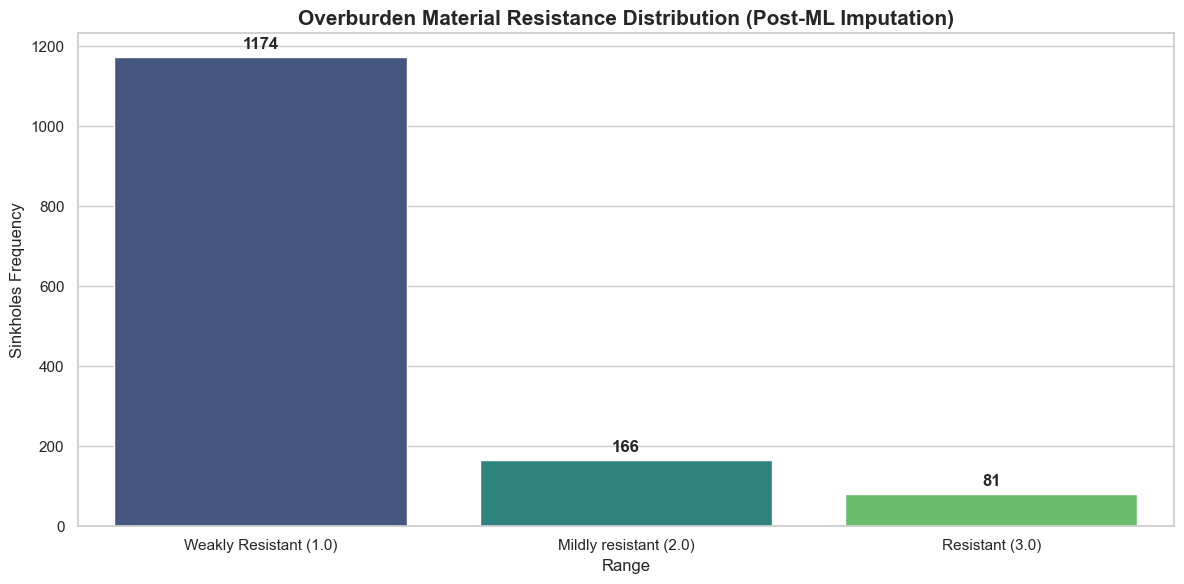


--- RESUMEN DE RESISTENCIA ---
   Resistencia  Frecuencia
0          1.0        1174
1          2.0         166
2          3.0          81


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Preparar los datos para el gráfico
# Contamos las frecuencias de cada clase de resistencia (1.0, 2.0, 3.0)
df_res_plot = df_ml['overburden_resistance_numeric'].value_counts().sort_index().reset_index()
df_res_plot.columns = ['Resistencia', 'Frecuencia']

# Mapeamos a etiquetas descriptivas para una mejor interpretación geológica
labels_map = {
    1.0: 'Weakly Resistant (1.0)',
    2.0: 'Mildly resistant (2.0)',
    3.0: 'Resistant (3.0)'
}
df_res_plot['Descripción'] = df_res_plot['Resistencia'].map(labels_map)

# 2. Crear la visualización
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))

# Usamos 'Descripción' como hue para evitar el Future Warning
ax = sns.barplot(
    x='Descripción', 
    y='Frecuencia', 
    data=df_res_plot, 
    hue='Descripción', 
    palette='viridis', 
    legend=False
)

# Añadir etiquetas de conteo sobre las barras
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), 
                textcoords='offset points', fontweight='bold')

plt.title('Overburden Material Resistance Distribution (Post-ML Imputation)', fontsize=15, fontweight='bold')
plt.ylabel('Sinkholes Frequency', fontsize=12)
plt.xlabel('Range', fontsize=12)
plt.tight_layout()
plt.show()

# 3. Mostrar tabla de resumen
print("\n--- RESUMEN DE RESISTENCIA ---")
print(df_res_plot[['Resistencia', 'Frecuencia']])

### 2. DEPTH OF THE DRIFT RELATIVE TO THE SURFACE

In [24]:
# CONTINUAR CON EN ANALISIS DEL RESTO DE VARIABLES QUE VAN A FORMAR PARTE DEL MODELO DE SUSCEPTIBILIDAD
# DE ACUERDO A LA PROFUNDIDAD DE LA MINA
# INCLUIR LA DENSIDAD DE SINKHOLES (hay zonas que tienen enjambres de sinkholes - verificar si hay cambios con respecto a la profundidad en los enjambres) 
# -> CREAMOS UNA VARIABLE DENSIDAD O USAR UN MODELO DE ML PARA ASIGNAR UN ID CLUSTER A CADA GRUPO

In [25]:
df_risk["depth_of_the_drift_relative_to_the_surface_m"].unique()

array([12.5, '25-50', '<40', '>50', 25, 's.o.', 15, '<10', 20, 'unknown',
       '<50', 100, '> 50', 10, 40, 37, 5, 'so', nan, 1, 37.5, 0, 3, 2.5,
       11, '<5', '<25', '< 30', '30-50', '30-51', '< 5 m', '<10 m',
       '< 15 m', ' 20 m', '< 10 m', '10 m', '< 40m', '16 m', '<30 m',
       '15 to 30', '<15', '30-40', '20 - 50', '0-20', '<20', '<18',
       '15-20', '<33', 'up to 760 m ', '50 - 200 m',
       'early drifts shallow up to 50 m, deeper reached 300-350 m ', 90,
       93, 42, 97, 46, 30, 35, 45, 163, 50, 21, 22, 55, 60, 70, 57, 135,
       125, 95, 240, 220, 210, 85, 75, 65, 80, 145, 105, 16, 115, 120,
       130, 205, 150, 165, 160, 170, 190, 180, 175, 116, 187, 185, 252,
       47, 41, 38, 33, 44, 36, 32, 28, 24, 39, 92, 67, 128, 9, 76, 14, 17,
       23, 54, 68, 6, 26, 8, 12, 18, 82, 13, 52, 110, 7, 53, 14.5, 2, 225,
       58, 34, 19, 330, 43, 48, 'Open pit mine'], dtype=object)

In [26]:
import re
import numpy as np

def parse_depth(text):
    text = str(text).lower().strip()
    
    # 1. Manejo de nulos y desconocidos
    if text in ['nan', 'unknown', 's.o.', 'so', '?']:
        return np.nan
    if 'open pit' in text:
        return 0.0

    # 2. Manejo de Rangos (ej. '25-50' o '25 to 50')
    range_match = re.findall(r'(\d+\.?\d*)\s*(?:-|to)\s*(\d+\.?\d*)', text)
    if range_match:
        val1, val2 = map(float, range_match[0])
        return (val1 + val2) / 2

    # 3. Manejo de Operadores (ej. '<40', '>50', 'up to 50')
    # Extraemos el primer número que aparezca
    numbers = re.findall(r'(\d+\.?\d*)', text)
    if numbers:
        return float(numbers[0])

    return np.nan

# Aplicar la limpieza
df_risk['depth_drift_clean'] = df_risk['depth_of_the_drift_relative_to_the_surface_m'].apply(parse_depth)

In [27]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 21 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   x_wgs84                                       1814 non-null   float64
 2   y_wgs84                                       1814 non-null   float64
 3   number_of_sinkholes                           1807 non-null   object 
 4   length_diameter_m                             1672 non-null   object 
 5   depth_of_the_sinkhole_m                       1590 non-null   object 
 6   in-situ_measurement_or_estimation             1623 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object 
 8   origin_of_collapse                            1792 non-null   object 
 9   start_date_of_the_mining                      1784 non-null   o

In [28]:
df_clean.y_wgs84.unique()

array([45.61984919, 45.62193191, 45.62163028, ..., 50.284181  ,
       50.29608463, 50.283481  ], shape=(1768,))

### VISUALIZACION DE DENSIDAD DE SINKHOLES

In [29]:
import folium
from folium.plugins import HeatMap, MarkerCluster

# 1. Crear el mapa base centrado en el promedio de tus coordenadas
# Asegúrate de que las columnas se llamen 'latitude' y 'longitude' o cámbialas aquí
mapa_sinkholes = folium.Map(
    location=[df_risk['y_wgs84'].mean(), df_risk['x_wgs84'].mean()], 
    zoom_start=12,
    tiles='CartoDB positron'
)

# 2. Opción A: Marcadores Agrupados (MarkerCluster)
# Esto agrupa los puntos automáticamente (verás círculos con números como "73", "49", etc.)
marker_cluster = MarkerCluster(name="Agrupación de Sinkholes").add_to(mapa_sinkholes)

for idx, row in df_risk.iterrows():
    if not np.isnan(row['y_wgs84']) and not np.isnan(row['x_wgs84']):
        folium.CircleMarker(
            location=[row['y_wgs84'], row['x_wgs84']],
            radius=3,
            color='red',
            fill=True,
            fill_color='red',
            # Añadimos información al hacer click (tu variable limpia de profundidad)
            popup=f"ID: {row['id_bd_sinkhole']} <br> Profundidad: {row['depth_drift_clean']}m <br> Espesor: {row['working_thickness_shaft_deep']}"
        ).add_to(marker_cluster)

# 3. Opción B: Mapa de Calor (HeatMap)
# Esto cumple con la parte de "análisis probabilístico" mostrando zonas de mayor ocurrencia
heat_data = [[row['y_wgs84'], row['x_wgs84']] for idx, row in df_risk.iterrows() if not np.isnan(row['y_wgs84'])]
HeatMap(heat_data, name="Mapa de Calor (Densidad)", radius=15, blur=10).add_to(mapa_sinkholes)

# Añadir control de capas para encender/apagar el mapa de calor
folium.LayerControl().add_to(mapa_sinkholes)

# Guardar y mostrar
mapa_sinkholes.save('mapa_sinkholes_lille.html')

### 3. PROFUNDIDAD DE GALERIA

In [30]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 21 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   x_wgs84                                       1814 non-null   float64
 2   y_wgs84                                       1814 non-null   float64
 3   number_of_sinkholes                           1807 non-null   object 
 4   length_diameter_m                             1672 non-null   object 
 5   depth_of_the_sinkhole_m                       1590 non-null   object 
 6   in-situ_measurement_or_estimation             1623 non-null   object 
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object 
 8   origin_of_collapse                            1792 non-null   object 
 9   start_date_of_the_mining                      1784 non-null   o

In [31]:
# ANALISIS DE OCURRENCIA CON LA PRODUNDIDAD DE GALERIA
# Hay que tomar en cuenta que NO estamos tomando en cuenta el sesgo estadistico potencial debido a dos aspectos importantes:
# 1. Sesgo observacional (venta de observacion - completitud del catalogo). Es mas probable que un sinkhole somero (30m) sea detectado que uno de 200 m + eventos en minas antiguas (<30m) no tienen registros oficiales + 
# en mineas profundas es menos probable que se evidencie en superficie (factor de esponjamiento)
# 2. Sesgo por tecnicas de explotacion. La mineria somera es historicamente la mas facil de explotar historicamente y probablemente se usaban metodos menos tecnificados? 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Definimos los rangos (bins) basados en criterios geotécnicos comunes
# 0-15m: Muy somero (Crítico)
# 15-30m: Somero (Alto)
# 30-60m: Media profundidad (Moderado)
# >60m: Profundo (Bajo)
bins = [0, 15, 30, 60, 1000]
labels = ['Very Shallow (0-15m)', 'Shallow (15-30m)', 'Intermediate (30-60m)', 'Deep (>60m)']

# 2. Categorizamos los datos limpios de profundidad
df_risk['depth_range'] = pd.cut(df_risk['depth_drift_clean'], bins=bins, labels=labels)

# 3. Cálculo de la Probabilidad de Frecuencia (P_f)
# Calculamos cuántos sinkholes hay en cada rango y lo normalizamos de 0 a 1
frecuencia_counts = df_risk['depth_range'].value_counts().sort_index()

# Creamos un DataFrame de referencia para los pesos
tabla_pesos_profundidad = frecuencia_counts.reset_index()
tabla_pesos_profundidad.columns = ['Rango_Profundidad', 'Frecuencia']

# Normalizamos el peso para que el rango más peligroso sea 1.0 (Puntaje de Susceptibilidad)
max_freq = tabla_pesos_profundidad['Frecuencia'].max()
tabla_pesos_profundidad['Susceptibility_Score'] = (tabla_pesos_profundidad['Frecuencia'] / max_freq).round(2)

print("--- Tabla de Susceptibilidad por Profundidad ---")
print(tabla_pesos_profundidad)

--- Tabla de Susceptibilidad por Profundidad ---
       Rango_Profundidad  Frecuencia  Susceptibility_Score
0   Very Shallow (0-15m)         224                  0.37
1       Shallow (15-30m)         254                  0.42
2  Intermediate (30-60m)         602                  1.00
3            Deep (>60m)         164                  0.27


In [32]:
df_risk.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 22 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   id_bd_sinkhole                                1814 non-null   object  
 1   x_wgs84                                       1814 non-null   float64 
 2   y_wgs84                                       1814 non-null   float64 
 3   number_of_sinkholes                           1807 non-null   object  
 4   length_diameter_m                             1672 non-null   object  
 5   depth_of_the_sinkhole_m                       1590 non-null   object  
 6   in-situ_measurement_or_estimation             1623 non-null   object  
 7   date_of_appearance_of_the_sinkhole            1813 non-null   object  
 8   origin_of_collapse                            1792 non-null   object  
 9   start_date_of_the_mining                      1784 n

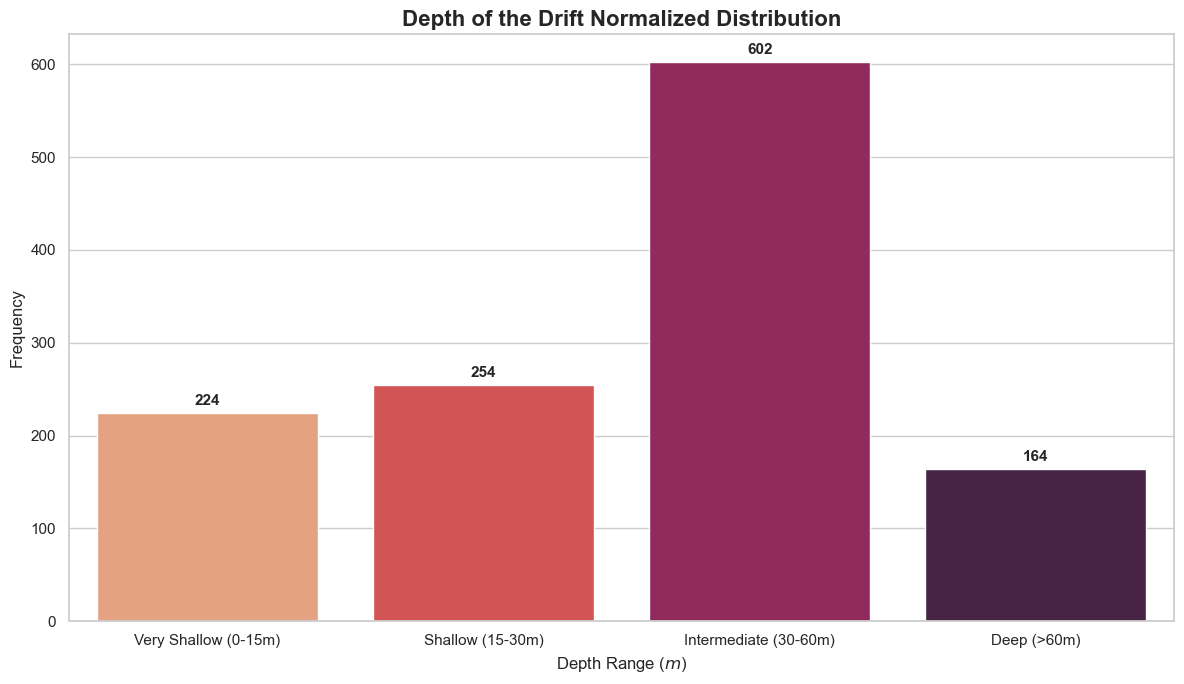

In [33]:
# Graficar la frecuencia de profundidades

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df_plot = pd.DataFrame(tabla_pesos_profundidad)

# Set the style
sns.set_theme(style="whitegrid")

# Create the figure
plt.figure(figsize=(12, 7))

# Plotting Normalized Frequency (Peso Probabilistico)
# Using a color palette that emphasizes depth/severity

ax = sns.barplot(
    x='Rango_Profundidad', 
    y='Frecuencia', 
    data=df_plot,
    hue = "Rango_Profundidad",
    palette= "rocket_r",
    legend = False)

# Add title and labels
plt.title('Depth of the Drift Normalized Distribution', fontsize=16, fontweight='bold')
plt.xlabel('Depth Range ($m$)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Add values on top of bars
for p in ax.patches:
    ax.annotate(format(p.get_height(), '.0f'), 
                   (p.get_x() + p.get_width() / 2., p.get_height()), 
                   ha = 'center', va = 'center', 
                   xytext = (0, 9), 
                   textcoords = 'offset points',
                   fontsize=11, fontweight='bold')

#plt.ylim(0, 0.55)
plt.tight_layout()
plt.show()

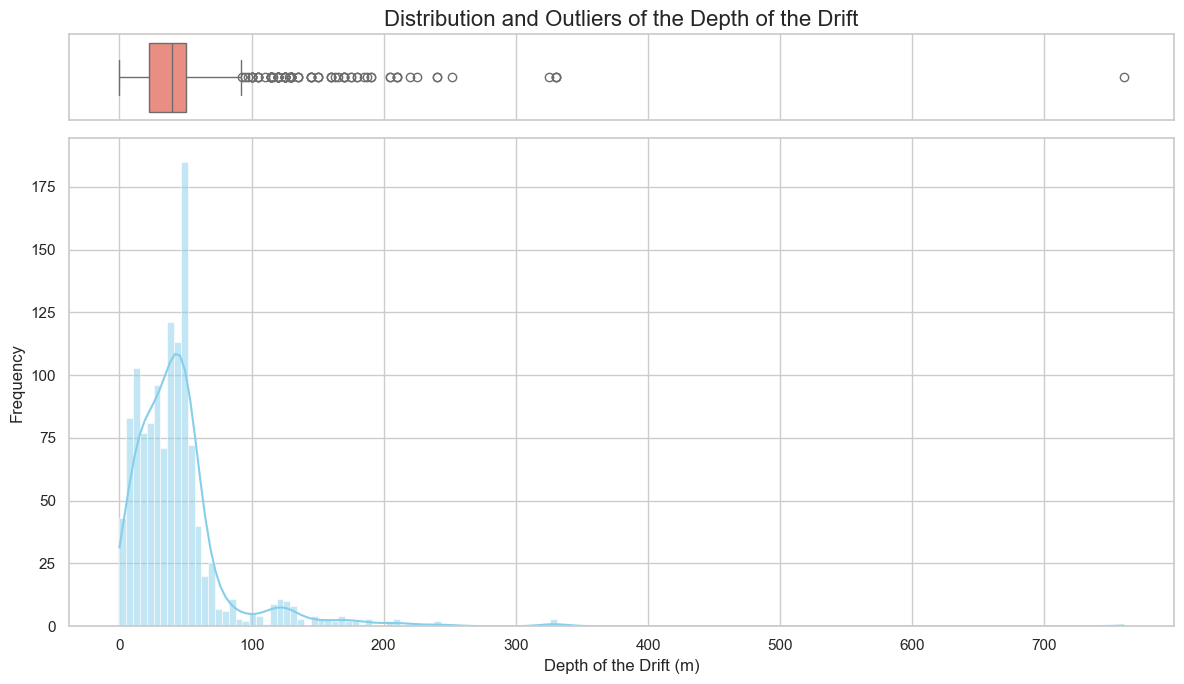

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de estilo profesional
sns.set_theme(style="whitegrid")

# Crear una figura con dos subplots: Histograma y Boxplot
# El boxplot ayuda a identificar visualmente los valores atípicos como el 760
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# 1. Boxplot (Diagrama de caja)
sns.boxplot(data=df_risk, x="depth_drift_clean", ax=ax_box, color="salmon")
ax_box.set(xlabel='') # Eliminar etiqueta del eje X para el boxplot
ax_box.set_title('Distribution and Outliers of the Depth of the Drift', fontsize=16)

# 2. Histograma con curva de densidad (KDE)
sns.histplot(data=df_risk, x="depth_drift_clean", kde=True, ax=ax_hist, color="skyblue")
ax_hist.set_xlabel('Depth of the Drift (m)', fontsize=12)
ax_hist.set_ylabel('Frequency', fontsize=12)

# Ajustar diseño
plt.tight_layout()

### 2. ANALISIS DE WORKING THICKNESS

In [35]:
df_risk["working_thickness_shaft_deep"].unique()

array(['2 to 3 m', nan, '2 - 2,5', 2.5, 43, 2, '1,8 to 3,5', '< 2 m', 1,
       3, 20, '1,7', 100, 50, 45, 40, 36, '<1,5', 19, 47, 81, 15, 48, 95,
       85, 157, 1.7, '1 to 2', 94, 170, 'up to 730 m ', 'up to 339 m',
       'shaft depth: 162 m and tunnel length: 5 km', '234 m (in 1922)',
       'working seams: 1-3 m, shaft depth up tp 344 m ', 'unknown',
       'deepest reached -810 m above sea level', 'max. 606 m', 4, 3.9,
       5.5, 4.2, 4.7, 2.6, 2.65, 2.2, 2.3, 2.8, 4.9, 1.5, 1.8, 5, 3.8,
       2.9, 4.6, 6, 2.25, 2.7, 5.8, 1.4, 80, 4.8, 4.1, 37, 10, 1.6, 3.6,
       3.3, 23, 44, 3.1, 3.5, 8, 1.9, 1.85, 2.4, 3.2, 2.1, 3.4, 1.75, 38,
       1.3, 1.65, 3.15, 28.7, 1.2, 19.5, 0.8, '1,6-2,0', '1,7-2,0', 16,
       7.2], dtype=object)

In [36]:
import re
import numpy as np

#1. LIMPIEZA INICIAL

def clean_working_thickness(val):
    # Convertir a minúsculas y quitar espacios
    val = str(val).lower().strip()
    
    # 1. Manejo de nulos y desconocidos
    if val in ['nan', 'unknown', 's.o.', 'so', '?', 'none']:
        return np.nan

    # 2. Manejo de Rangos (ej. '1.5-2.0', '1.5 to 2', '1,5 - 2')
    # Reemplazamos coma por punto para estandarizar decimales
    val = val.replace(',', '.')
    range_match = re.findall(r'(\d+\.?\d*)\s*(?:-|to)\s*(\d+\.?\d*)', val)
    if range_match:
        v1, v2 = map(float, range_match[0])
        return (v1 + v2) / 2

    # 3. Manejo de prefijos y sufijos (ej. '< 2m', '> 1.5', '2 mts')
    # Buscamos todos los números con decimales
    numbers = re.findall(r'(\d+\.?\d*)', val)
    if numbers:
        # Si hay varios números y no era un rango, tomamos el primero
        # (Suele ser el valor principal en descripciones tipo '2m deep')
        return float(numbers[0])

    return np.nan

# Aplicar la limpieza al DataFrame
df_risk['working_thickness_numeric'] = df_risk['working_thickness_shaft_deep'].apply(clean_working_thickness)

# Estadísticas descriptivas básicas para detectar errores (Outliers)
print("\n--- Statistical Description ---")
print(df_risk['working_thickness_numeric'].describe())


--- Statistical Description ---
count    1120.000000
mean       23.709911
std       120.943143
min         0.800000
25%         2.000000
50%         3.000000
75%         4.000000
max       810.000000
Name: working_thickness_numeric, dtype: float64


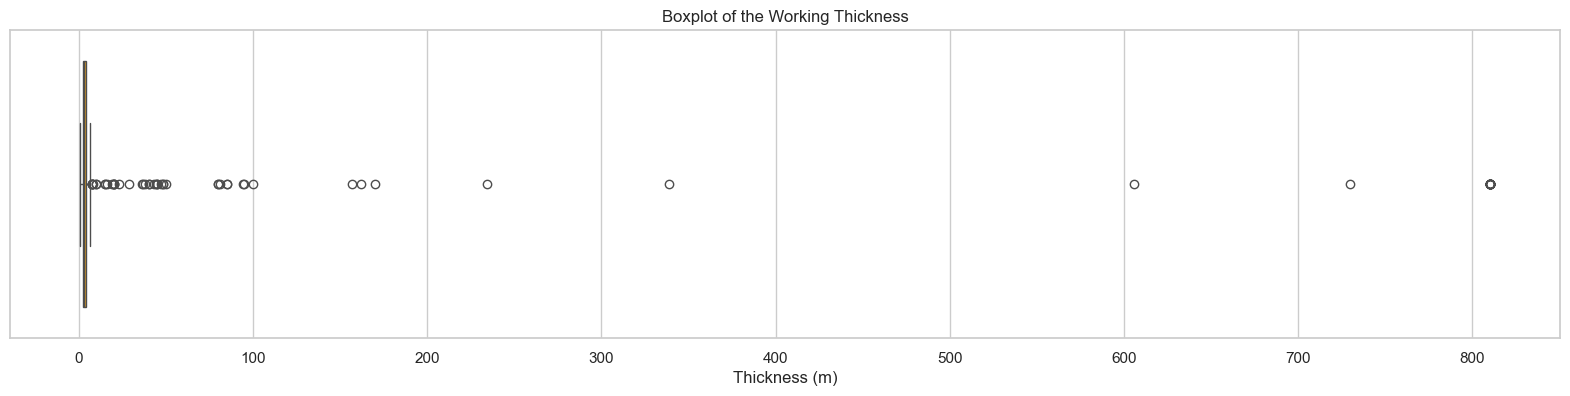

In [37]:
# 2. VISUALIZAR DISTRIBUCION
# VERIFICAR QUE HAY VALORES QUE SON PROFUNDIDADES Y NO THICKNESS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Visualización de Outliers (Boxplot)
plt.figure(figsize=(20, 4))
sns.boxplot(x=df_risk['working_thickness_numeric'].dropna(), color='orange')
plt.title('Boxplot of the Working Thickness')
plt.xlabel('Thickness (m)')
plt.show()


In [38]:
# 3. VALORES SOSPECHOSOS

# Listado de Valores Sospechosos (> 5m)
# El límite de 5m es un buen punto de corte para vetas de carbón europeas (working_thickness)
threshold = 5.0
suspect_values = df_risk[df_risk['working_thickness_numeric'] >= threshold]

print(f"\n--- Análisis de Valores Mayores a {threshold} m ---")
print(f"Cantidad de valores sospechosos: {len(suspect_values)}")
cols_to_show = ['depth_drift_clean', 'working_thickness_numeric']
# Mostramos también la profundidad para ver si hay correlación
print(suspect_values[cols_to_show].sort_values(by='working_thickness_numeric', ascending=False))


--- Análisis de Valores Mayores a 5.0 m ---
Cantidad de valores sospechosos: 94
      depth_drift_clean  working_thickness_numeric
557                 NaN                      810.0
558                 NaN                      810.0
720                 NaN                      810.0
721                 NaN                      810.0
734                 NaN                      810.0
...                 ...                        ...
1354              115.0                        5.0
1413              125.0                        5.0
1422              187.0                        5.0
1415              145.0                        5.0
1503                5.0                        5.0

[94 rows x 2 columns]


Podemos ver que hay valores muy altos de working_thickness_numeric que son anomalos. Ya que un espesor de capa de carbon de 162m es imposible. Por otro lado podemos ver que existen capas de 5m a profundidades de >100 m. Mientras que existen observaciones donde la profundidad es igual al espesor de capa (Tiene sentido esto? - Son explotaciones a cielo abierto? - Esta mal llenada la informacion). Yo me inclino a que no se entendio bien como habia que llenar la informacion y hubo un mal llenado de la informacion.

In [39]:
# 4. LIMPIEZA DE VALORES CON PROFUNDIDA Y ESPESOR IGUAL O APROXIMADAMENTE IGUAL
 
# 1. Definimos la lógica de error
# Si el espesor es "sospechosamente grande" (> 5m) Y se parece a la profundidad
# (Usamos una tolerancia de 2m para la imputacion)
def is_data_error(row):
    th = row['working_thickness_numeric']
    dp = row['depth_drift_clean']
    
    if pd.isna(th) or pd.isna(dp):
        return False
        
    # Tu criterio: Valores grandes donde Thickness ≈ Depth
    if th >= 5 and abs(th - dp) < 2.0: 
        return True
        
    return False

# Creamos una copia del df original para evaluar diferencias
df_risk_prof_espesor = df_risk.copy()

# 2. Identificamos los errores
errores_mask = df_risk_prof_espesor.apply(is_data_error, axis=1)
print(f"Detectados {errores_mask.sum()} registros donde Espesor ≈ Profundidad.")

# Visualizamos algunos antes de borrarlos para estar seguros
if errores_mask.sum() > 0:
    print(df_risk_prof_espesor.loc[errores_mask, ["id_bd_sinkhole",'working_thickness_numeric', 'depth_drift_clean']].head())

# 3. CORRECCIÓN: Convertimos esos espesores erróneos a NaN
df_risk_prof_espesor.loc[errores_mask, 'working_thickness_numeric'] = np.nan


Detectados 22 registros donde Espesor ≈ Profundidad.
     id_bd_sinkhole  working_thickness_numeric  depth_drift_clean
346      FR-SIN-347                       36.0               35.0
1427   POL-SIN- 519                       80.0               80.0
1428   POL-SIN- 520                       80.0               80.0
1465   POL-SIN- 557                       37.0               37.0
1466   POL-SIN- 558                       10.0                9.0


In [40]:
df_risk_prof_espesor[df_risk_prof_espesor["id_bd_sinkhole"] == "FR-SIN-347"]

,id_bd_sinkhole,x_wgs84,y_wgs84,number_of_sinkholes,length_diameter_m,depth_of_the_sinkhole_m,in-situ_measurement_or_estimation,date_of_appearance_of_the_sinkhole,origin_of_collapse,start_date_of_the_mining,...,depth_of_the_drift_relative_to_the_surface_m,material_overbuden_resistance,geology_of_the_overburden,presence_of_buildings_or_infrastructure,geo_clean,res_clean,resistance_numeric,depth_drift_clean,depth_range,working_thickness_numeric
346,FR-SIN-347,6.48721,47.596997,1,2.5,1.5,In-situ measurement,Unknown,Collapse of the shaft filling material,1827,...,20 - 50,resistant,Iridescent clay marls and dolomite of Middle K...,no,iridescent clay marls and dolomite of middle k...,resistant,3.0,35.0,Intermediate (30-60m),NaN


In [41]:
# 5. IMPUTACION DE VALORES NULOS EN depth_drift_clean CON VALORES ALTOS DE working_thickness

# 1. Definimos la máscara para los valores con profundidades anomalas
mask_transposicion = df_risk_prof_espesor['working_thickness_numeric'] >= 8.0

# 2. Imputamos en depth_drift_numeric SOLO donde sea nulo
df_risk_prof_espesor.loc[mask_transposicion, 'depth_drift_clean'] = \
    df_risk_prof_espesor.loc[mask_transposicion, 'depth_drift_clean'].fillna(df_risk_prof_espesor['working_thickness_numeric'])

# 3. Limpiamos la columna de espesor 
# Ahora que ya rescatamos el dato, lo borramos de thickness para que no ensucie el análisis posterior
df_risk_prof_espesor.loc[mask_transposicion, 'working_thickness_numeric'] = np.nan

# --- Verificación de la operación ---
print(f"Registros corregidos: {mask_transposicion.sum()}")
print(f"Valores nulos actuales en profundidad: {df_risk_prof_espesor['depth_drift_clean'].isnull().sum()}")
print(f"Máximo espesor tras la limpieza: {df_risk_prof_espesor['working_thickness_numeric'].max()} m")

Registros corregidos: 47
Valores nulos actuales en profundidad: 529
Máximo espesor tras la limpieza: 7.2 m


In [42]:
df_risk_prof_espesor.iloc[:,5:].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 18 columns):
 #   Column                                        Non-Null Count  Dtype   
---  ------                                        --------------  -----   
 0   depth_of_the_sinkhole_m                       1590 non-null   object  
 1   in-situ_measurement_or_estimation             1623 non-null   object  
 2   date_of_appearance_of_the_sinkhole            1813 non-null   object  
 3   origin_of_collapse                            1792 non-null   object  
 4   start_date_of_the_mining                      1784 non-null   object  
 5   end_date_of_the_mining                        1804 non-null   object  
 6   dip_of_the_exploited_layer_degree             1603 non-null   object  
 7   working_thickness_shaft_deep                  1487 non-null   object  
 8   depth_of_the_drift_relative_to_the_surface_m  1654 non-null   object  
 9   material_overbuden_resistance                 830 no

In [43]:
df_risk_prof_espesor.tail()

,id_bd_sinkhole,x_wgs84,y_wgs84,number_of_sinkholes,length_diameter_m,depth_of_the_sinkhole_m,in-situ_measurement_or_estimation,date_of_appearance_of_the_sinkhole,origin_of_collapse,start_date_of_the_mining,...,depth_of_the_drift_relative_to_the_surface_m,material_overbuden_resistance,geology_of_the_overburden,presence_of_buildings_or_infrastructure,geo_clean,res_clean,resistance_numeric,depth_drift_clean,depth_range,working_thickness_numeric
1809,POL-SIN- 901,19.270014,50.284405,3,12,4,In situ measurement,1997-07-08 00:00:00,Faillure of the roof room or roof gallery,1874,...,41,NaN,"Carboniferous sandstone and shale, quaternary ...",yes,"carboniferous sandstone and shale, quaternary ...",nan,NaN,41.0,Intermediate (30-60m),7.2
1810,POL-SIN- 902,19.270224,50.284391,3,2,2,In situ measurement,1997-07-08 00:00:00,Faillure of the roof room or roof gallery,1874,...,43,NaN,"Carboniferous sandstone and shale, quaternary ...",no,"carboniferous sandstone and shale, quaternary ...",nan,NaN,43.0,Intermediate (30-60m),7.2
1811,POL-SIN- 903,19.270547,50.284181,3,12,7,In situ measurement,1997-07-08 00:00:00,Faillure of the roof room or roof gallery,1874,...,48,NaN,"Carboniferous sandstone and shale, quaternary ...",no,"carboniferous sandstone and shale, quaternary ...",nan,NaN,48.0,Intermediate (30-60m),7.2
1812,POL-SIN- 904,19.263715,50.296085,1,1.5,15,In situ measurement,2013-03-12 00:00:00,Collapse of the shaft filling material,1874,...,6,NaN,"Carboniferous sandstone and shale, quaternary ...",no,"carboniferous sandstone and shale, quaternary ...",nan,NaN,6.0,Very Shallow (0-15m),NaN
1813,POL-SIN- 905,19.265115,50.283481,1,NaN,NaN,In situ measurement,NaN,Suffosion,1874,...,Open pit mine,NaN,"Carboniferous sandstone and shale, quaternary ...",no,"carboniferous sandstone and shale, quaternary ...",nan,NaN,0.0,NaN,NaN


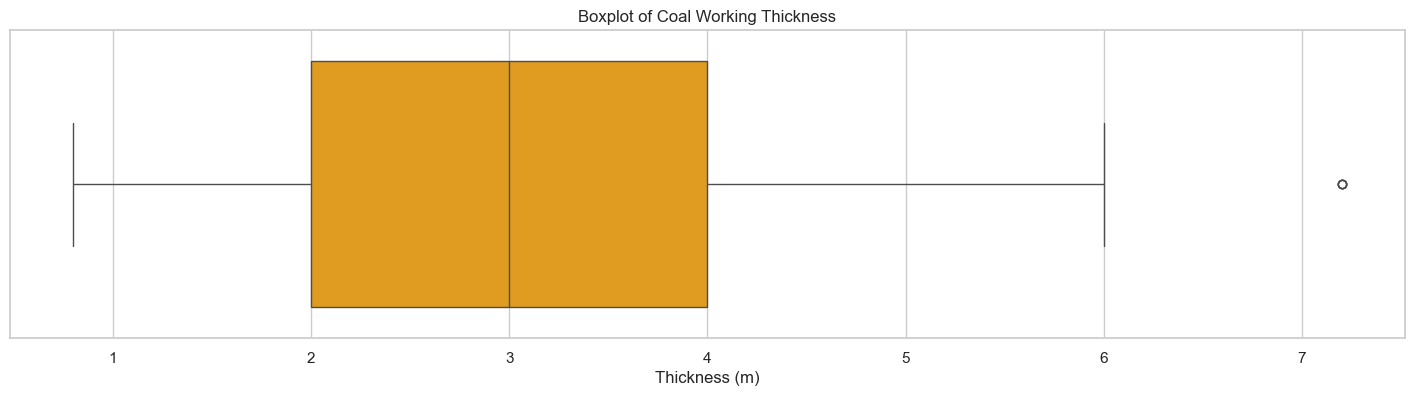

In [44]:
# 6 VISUALIZACION DE DISTRIBUCION POST IMPUTACION Y LIMPIEZA

plt.figure(figsize=(18, 4))
sns.boxplot(x=df_risk_prof_espesor['working_thickness_numeric'].dropna(), color='orange')
plt.title('Boxplot of Coal Working Thickness')
plt.xlabel('Thickness (m)')
plt.show()


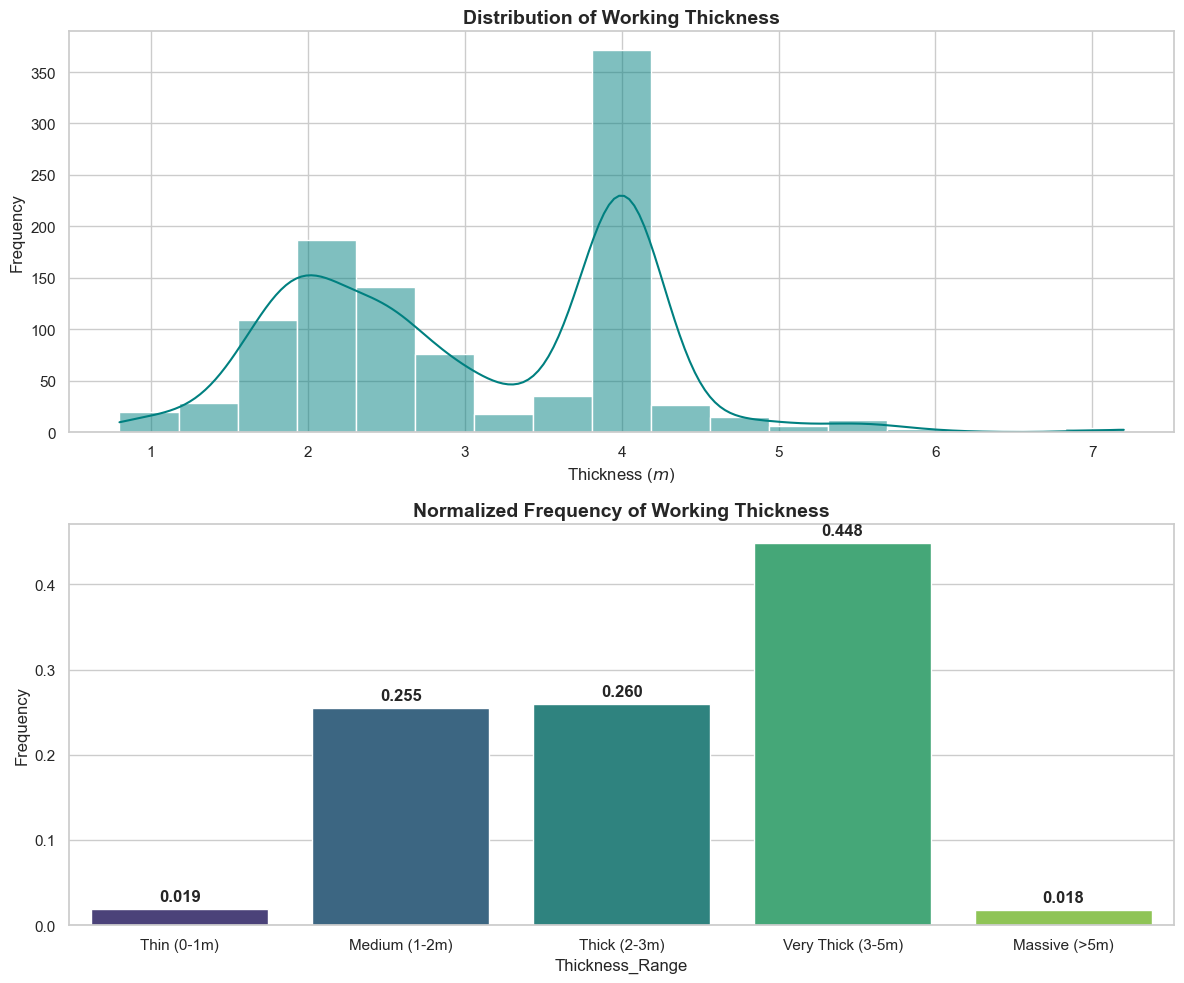


--- TABLA DE SUSCEPTIBILIDAD POR ESPESOR ---
     Thickness_Range  Frecuencia
0        Thin (0-1m)    0.019029
1      Medium (1-2m)    0.254995
2       Thick (2-3m)    0.259753
3  Very Thick (3-5m)    0.448145
4      Massive (>5m)    0.018078


In [45]:
# 7. VISUALIZACION DE DISTRIBUCION DE WORKING THICKNESS

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. Configuración de estilo
sns.set_theme(style="whitegrid")
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# --- GRÁFICO 1: DISTRIBUCIÓN CONTINUA (KDE + Histogram) ---
sns.histplot(df_risk_prof_espesor['working_thickness_numeric'].dropna(), kde=True, color='teal', ax=ax1)
ax1.set_title('Distribution of Working Thickness', fontsize=14, fontweight='bold')
ax1.set_xlabel('Thickness ($m$)')
ax1.set_ylabel('Frequency')

# --- GRÁFICO 2: PESOS PROBABILÍSTICOS POR RANGOS ---
# Recalculamos los rangos con los datos limpios
bins_thick = [0, 1, 2, 3, 5, 10] # Ajustamos el máximo a 10m tras la limpieza
labels_thick = ['Thin (0-1m)', 'Medium (1-2m)', 'Thick (2-3m)', 'Very Thick (3-5m)', 'Massive (>5m)']
df_risk_prof_espesor['thickness_range'] = pd.cut(df_risk_prof_espesor['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# Calculamos la tabla de pesos
tabla_pesos_espesor = df_risk_prof_espesor['thickness_range'].value_counts(normalize=True).sort_index().reset_index()
tabla_pesos_espesor.columns = ['Thickness_Range', 'Frecuencia']

# Graficamos
sns.barplot(
    x='Thickness_Range', 
    y='Frecuencia', 
    data=tabla_pesos_espesor, 
    hue='Thickness_Range', 
    palette="viridis", 
    ax=ax2, 
    legend=False
)

# Añadimos etiquetas de valor
for p in ax2.patches:
    ax2.annotate(format(p.get_height(), '.3f'), 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', xytext=(0, 9), textcoords='offset points', fontweight='bold')

ax2.set_title('Normalized Frequency of Working Thickness', fontsize=14, fontweight='bold')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Mostramos la tabla para tu reporte
print("\n--- TABLA DE SUSCEPTIBILIDAD POR ESPESOR ---")
print(tabla_pesos_espesor)


### **RESUMEN**
De aqui se puede complicar el estudio realizando un analisis geoespacial de los puntos de cada sinkhole (se puede crear una variable adicional llamada densidad de sinkhole). Pero en este caso vamos a realizar directamente el MODELO DE SUSCEPTIBILIDAD para analizar resultados. Este modelo se va a realizar con las 3 variables analizadas previamente: resistencia de material (overburden_resistance_numeric), profundidad de galeria (depth_of_the_dritft_relative_to_the_surface) y espesor de capa (working_thickness_numeric)

Las variables de interes para el analisis de susceptibilidad son:

- overburden_resistance_numeric
- working_thickness_numeric
- depth_drift_clean

Podemos notar que las variables de interes no tienen una completitud en cada fila. Por lo tanto, es necesario realizar una imputacion para rellenar los datos faltantes a partir de un analisis a partir del analisis geologico previo. Esto es, utilizar el analisis de cluster geologico realizado anteriormente para rellenar los datos faltantes

# IMPUTACION EN VARIABLES DEL MODELO POR DISTANCIAS ENTRE VECINOS

In [46]:
# UNION DE DATAFRAMES GENERADOS ANTERIORMENTE (df_risk_prof_espesor y df_ml)
# Incluir variable overburden_resistance_numeric al df final
df_risk_completo = df_risk_prof_espesor.merge(
    df_ml[['id_bd_sinkhole', 'overburden_resistance_numeric']], 
    on='id_bd_sinkhole', 
    how='left'
)

In [47]:
# Antes de realizar la imputacion, tomamos un subset del df_risk_completo con solo las variables de interes:

variables_interes = ["id_bd_sinkhole",
                     "x_wgs84",
                     "y_wgs84",
                        "overburden_resistance_numeric",
                        "depth_drift_clean",
                        "working_thickness_numeric"]

df_susceptibilidad = df_risk_completo[variables_interes].copy()

In [48]:
# Podemos notar que las variables para el modelo tienen "huecos" entre si. Si fuera una matriz de las 3 variables predictoras existieran valores NaN entre si. Por lo tanto la imputacion es necesaria
df_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1814 non-null   object 
 1   x_wgs84                        1814 non-null   float64
 2   y_wgs84                        1814 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1285 non-null   float64
 5   working_thickness_numeric      1051 non-null   float64
dtypes: float64(5), object(1)
memory usage: 85.2+ KB


Debido a que las capas de carbon y la geologia TIENEN UNA CORRELACION ESPACIAL, se decide realizar una imputacion espacial de los datos faltantes. (TOMAR EN CUENTA EL BUZAMIENTO PARA ESTE ANALISIS. Si es un buzamiento alto, va a ver una variacion mayor con depth_drift_clean)

Para implementar esto, utilizaremos el KNNImputer (K-Nearest Neighbors) de scikit-learn. Este algoritmo buscará los $k$ registros más cercanos geográficamente y promediará sus valores para rellenar el hueco.

In [49]:
# 1. Definimos las variables críticas para el modelo
variables_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# 2. Eliminamos filas donde TODAS las variables del modelo sean NaN
# El parámetro 'how="all"' asegura que solo borramos si no hay ningún dato útil.
df_susceptibilidad_clean = df_susceptibilidad.dropna(subset=variables_modelo, how='all').copy()

n_eliminados = len(df_susceptibilidad) - len(df_susceptibilidad_clean)
print(f"Se eliminaron {n_eliminados} registros por no tener ningún dato en las variables del modelo.")

Se eliminaron 367 registros por no tener ningún dato en las variables del modelo.


In [50]:
# Este DF tiene filas donde existe al menos un valor duro de las 3 variables de interes
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1447 non-null   object 
 1   x_wgs84                        1447 non-null   float64
 2   y_wgs84                        1447 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1285 non-null   float64
 5   working_thickness_numeric      1051 non-null   float64
dtypes: float64(5), object(1)
memory usage: 79.1+ KB


Para la transformacion a coordenadas UTM, el estándar de la Unión Europea es utilizar la proyección ETRS89-LAEA (Lambert Azimuthal Equal Area), conocida por su código EPSG:3035

In [51]:
# MEDIR LAS DISTANCIAS DE IMPUTACION
# 1. Transformar coordenadas geograficas a UTM

from pyproj import Transformer

# Creamos el transformador de WGS84 (4326) a ETRS89-LAEA (3035)
# Nota: pyproj usa (lat, lon) o (y, x) según el estándar
transformer = Transformer.from_crs("epsg:4326", "epsg:3035", always_xy=True)

# 2. Convertimos las coordenadas a metros europeos
# x_wgs84 es longitud, y_wgs84 es latitud
df_susceptibilidad_clean['x_laea'], df_susceptibilidad_clean['y_laea'] = transformer.transform(
    df_susceptibilidad_clean['x_wgs84'].values, 
    df_susceptibilidad_clean['y_wgs84'].values
)

In [52]:
df_susceptibilidad_clean.head()

,id_bd_sinkhole,x_wgs84,y_wgs84,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_laea,y_laea
0,FR-SIN-01,2.565428,45.619849,1.0,12.5,2.5,3.741432e+06,2.529762e+06
1,FR-SIN-02,2.563769,45.621932,1.0,37.5,2.5,3.741325e+06,2.530005e+06
2,FR-SIN-03,2.569623,45.621630,1.0,37.5,2.5,3.741777e+06,2.529926e+06
3,FR-SIN-04,2.570805,45.621464,1.0,12.5,2.5,3.741867e+06,2.529898e+06
4,FR-SIN-05,2.562041,45.611651,1.0,37.5,2.5,3.741082e+06,2.528882e+06


In [53]:
# 3. (OPCION 2) Realizamos la Imputacion con KNNImputer segun la distancia a sus vecinos

from sklearn.neighbors import NearestNeighbors
from sklearn.impute import KNNImputer

"""
Descripcion de los valores imputados

- True: Significa que el dato no existía originalmente y fue imputado
- False: Es un dato real que ya existia

La imputacion se realizó como el Promedio Ponderado por el Inverso de la Distancia (IDW) usando weights = 'distance'. El procedimiento es el siguiente:

1. Para cada valor faltante, el algoritmo busca segun las coordendas los 5 pountos mas cercanos que si tengan ese dato
2. Calcula la distancia fisica real entre el punto faltante y cada uno de sus 5 vecinos
3. Se le asigna un peso basado en su cercania. Es decir, si el vecino es muy cercano,se le asigna un peso muy grande, y si es lejano se le asigna un peso muy pequeño
4. El calculo final es la suma ponderada de los vecinos por sus pesos (SUMATORIA de valore_vecino_i*w_i), dividida para la suma total de los pesos (SUMATORIA w_i)
"""

# 1. Definimos las columnas que usaremos para la "distancia" y las que queremos rellenar
coords = ['x_laea', 'y_laea']
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']
# Esto nos servirá como "memoria" de lo que estaba vacío
mask_nan = df_susceptibilidad_clean[variables].isna()

# 2. Preparamos el imputador KNN
# Usamos 5 vecinos y pesamos por distancia (más cerca = más influencia)
imputer = KNNImputer(n_neighbors=5, weights='distance')

# 3. Aplicamos la imputación sobre el dataframe limpio
# Solo imputamos sobre las columnas numéricas de interés
df_imputado_vals = imputer.fit_transform(df_susceptibilidad_clean[coords + variables])

# 4. Creamos el dataframe final con los huecos ya rellenos
df_final_imputed = pd.DataFrame(df_imputado_vals, columns=coords + variables, index=df_susceptibilidad_clean.index)

# Recuperamos el ID original
df_final_imputed['id_bd_sinkhole'] = df_susceptibilidad_clean['id_bd_sinkhole']

# 5. CÁLCULO DE LA DISTANCIA DE VECINDAD (La pieza que faltaba)
# Buscamos los 5 vecinos más cercanos para cada punto en el espacio LAEA (metros)
nn = NearestNeighbors(n_neighbors=5).fit(df_susceptibilidad_clean[coords])
distancias, _ = nn.kneighbors(df_final_imputed[coords])

# Calculamos la distancia media de la vecindad y la integramos al DataFrame
df_final_imputed['distancia_promedio_al_vecino_m'] = distancias.mean(axis=1)
df_final_imputed['id_bd_sinkhole'] = df_susceptibilidad_clean['id_bd_sinkhole']

# 6. CREACIÓN DEL REPORTE DE AUDITORÍA
# Filtramos para ver solo las filas que tuvieron al menos un cambio
filas_imputadas = df_final_imputed[mask_nan.any(axis=1)].copy()

# Para cada variable, creamos una columna indicadora que diga si fue imputada o no
for var in variables:
    filas_imputadas[f'{var}_was_nan'] = mask_nan[var]

# 7. RESULTADOS
# Mostramos las primeras filas para verificar
print(f"Total de filas con algún valor imputado: {len(filas_imputadas)}")
qc_df_final = filas_imputadas[['id_bd_sinkhole'] + variables + [v + '_was_nan' for v in variables] + ['distancia_promedio_al_vecino_m']]
display(qc_df_final.sort_values(by=["distancia_promedio_al_vecino_m"], ascending= False).head(20))

Total de filas con algún valor imputado: 425


,id_bd_sinkhole,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,overburden_resistance_numeric_was_nan,depth_drift_clean_was_nan,working_thickness_numeric_was_nan,distancia_promedio_al_vecino_m
370,FR-SIN-371,2.000000,85.000000,2.250000,False,False,True,50385.938345
372,FR-SIN-373,2.000000,157.000000,2.250000,False,False,True,50294.534036
371,FR-SIN-372,2.000000,138.520083,2.250000,False,True,True,50232.434892
369,FR-SIN-370,2.000000,95.000000,2.250000,False,False,True,50018.058527
123,FR-SIN-124,1.000000,25.000000,2.299972,False,False,True,23968.977308
514,DEU-SIN-03,2.000000,162.000000,1.940920,False,False,True,13370.802589
513,DEU-SIN-02,2.000000,125.000000,1.957569,False,False,True,8827.905261
320,FR-SIN-321,1.000000,50.000000,2.250000,False,False,True,7992.133942
319,FR-SIN-320,1.000000,50.000000,2.250000,False,False,True,7856.601561
321,FR-SIN-322,1.000000,50.000000,2.250000,False,True,True,7676.842461


In [54]:
# (OPCION 3) EN LUGAR DE USAR LOS 5 MAS CERCANOS, USAMOS LOS QUE ESTAN A UNA X DISTANCIA DE RADIO

from sklearn.neighbors import RadiusNeighborsRegressor

# 1. Parámetros del modelo
RADIO_MAXIMO = 5000  # 5 kilómetros en metros
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']
coords = ['x_laea', 'y_laea']

# Creamos una copia para no alterar el original durante el bucle
df_final_radius = df_susceptibilidad_clean.copy()

# 2. Iteramos por cada variable para realizar la imputación por radio
for var in variables:
    # Separamos filas con datos (entrenamiento) y filas sin datos (a predecir)
    train = df_susceptibilidad_clean.dropna(subset=[var])
    test = df_susceptibilidad_clean[df_susceptibilidad_clean[var].isna()]
    
    if not test.empty:
        # Configuramos el regresor por radio
        # weights='distance' mantiene la lógica de que el vecino más cercano pese más
        rnr = RadiusNeighborsRegressor(radius=RADIO_MAXIMO, weights='distance')
        
        # Entrenamos con las coordenadas y el valor real de la variable
        rnr.fit(train[coords], train[var])
        
        # Intentamos predecir. Si no hay vecinos en el radio, devolverá NaN por defecto
        try:
            predicciones = rnr.predict(test[coords])
            df_final_radius.loc[test.index, var] = predicciones
        except ValueError:
            # Este error ocurre si algunos puntos no tienen ABSOLUTAMENTE NINGÚN vecino a 5km
            # En ese caso, dejamos esos puntos como NaN (que es lo que buscas por seguridad)
            pass


c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)
c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)
c:\Users\gbenavides\AppData\Local\miniforge3\envs\sinkhole_env\lib\site-packages\sklearn\neighbors\_regression.py:508: UserWarning: One or more samples have no neighbors within specified radius; predicting NaN.
  warnings.warn(empty_warning_msg)


In [55]:
df_final_radius.tail()

,id_bd_sinkhole,x_wgs84,y_wgs84,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,x_laea,y_laea
1809,POL-SIN- 901,19.270014,50.284405,1.0,41.0,7.200000,4.979717e+06,3.060871e+06
1810,POL-SIN- 902,19.270224,50.284391,1.0,43.0,7.200000,4.979732e+06,3.060872e+06
1811,POL-SIN- 903,19.270547,50.284181,1.0,48.0,7.200000,4.979757e+06,3.060851e+06
1812,POL-SIN- 904,19.263715,50.296085,1.0,6.0,7.200000,4.979110e+06,3.062105e+06
1813,POL-SIN- 905,19.265115,50.283481,1.0,0.0,7.086962,4.979384e+06,3.060725e+06


In [56]:
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1447 non-null   object 
 1   x_wgs84                        1447 non-null   float64
 2   y_wgs84                        1447 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1285 non-null   float64
 5   working_thickness_numeric      1051 non-null   float64
 6   x_laea                         1447 non-null   float64
 7   y_laea                         1447 non-null   float64
dtypes: float64(7), object(1)
memory usage: 134.0+ KB


In [57]:
# (OPCION 4) ESTE ES UN METODO HIBRIDO
# Lo que se busca es escoger los K vecinos mas cercanos, pero si laguno de esos K vecinos mas cercanos esta mas lejos que digamos 5 km, que no lo tome en cuenta para la imputacion
# Ya que no existe una libreria que haga esto, se calculo los vecinos mas cerca con NearestNeighbors junto con un poco de álgebra vectorial en numpy para lograr lo requerido
from sklearn.neighbors import NearestNeighbors
import numpy as np

# 1. Definición de parámetros
MAX_VECINOS = 5
RADIO_MAXIMO = 5000  # metros
variables = ['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']
coords_m = ['x_laea', 'y_laea']

df_hibrido = df_susceptibilidad_clean.copy()

# 2. Iteramos por cada variable para imputar
for var in variables:
    # Separar datos reales (entrenamiento) y nulos (a predecir)
    datos_reales = df_hibrido.dropna(subset=[var])
    datos_nulos = df_hibrido[df_hibrido[var].isna()]
    
    if datos_nulos.empty:
        continue
        
    # a. Entrenamos el buscador para encontrar exactamente 5 vecinos
    nn = NearestNeighbors(n_neighbors=MAX_VECINOS)
    nn.fit(datos_reales[coords_m])
    
    # b. Obtenemos distancias e índices de los 5 vecinos más cercanos
    distancias, indices = nn.kneighbors(datos_nulos[coords_m])
    
    valores_imputados = []
    
    # c. Evaluamos vecino por vecino para cada registro nulo
    for dist_fila, idx_fila in zip(distancias, indices):
        
        # EL FILTRO MÁGICO: Nos quedamos SOLO con las distancias <= 5000m
        mascara_validos = dist_fila <= RADIO_MAXIMO
        dist_validas = dist_fila[mascara_validos]
        idx_validos = idx_fila[mascara_validos]
        
        # Si ningún vecino de los 5 cumplió la regla de los 5km...
        if len(dist_validas) == 0:
            valores_imputados.append(np.nan)
        else:
            # Si hay vecinos válidos (1 a 5), hacemos el cálculo ponderado por distancia (IDW)
            # Prevenimos división por cero si la distancia es exactamente 0
            dist_validas = np.where(dist_validas == 0, 1e-10, dist_validas)
            pesos = 1.0 / dist_validas
            
            # Extraemos los valores reales de la variable para esos vecinos
            valores_vecinos = datos_reales[var].iloc[idx_validos].values
            
            # Promedio ponderado: (Valor * Peso) / Suma(Pesos)
            promedio_ponderado = np.sum(pesos * valores_vecinos) / np.sum(pesos)
            valores_imputados.append(promedio_ponderado)
            
    # Asignamos los valores calculados de vuelta al DataFrame
    df_hibrido.loc[datos_nulos.index, var] = valores_imputados

# 3. Verificamos el resultado final
print("--- RESULTADO DE IMPUTACIÓN HÍBRIDA (K=5, Max=5km) ---")
print(df_hibrido[variables].isna().sum())

--- RESULTADO DE IMPUTACIÓN HÍBRIDA (K=5, Max=5km) ---
overburden_resistance_numeric     26
depth_drift_clean                 30
working_thickness_numeric        169
dtype: int64


In [58]:
df_hibrido.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1447 non-null   object 
 1   x_wgs84                        1447 non-null   float64
 2   y_wgs84                        1447 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1417 non-null   float64
 5   working_thickness_numeric      1278 non-null   float64
 6   x_laea                         1447 non-null   float64
 7   y_laea                         1447 non-null   float64
dtypes: float64(7), object(1)
memory usage: 134.0+ KB


### EXPLICACION DE LOS DIFERENTES METODOS EVALUADOS

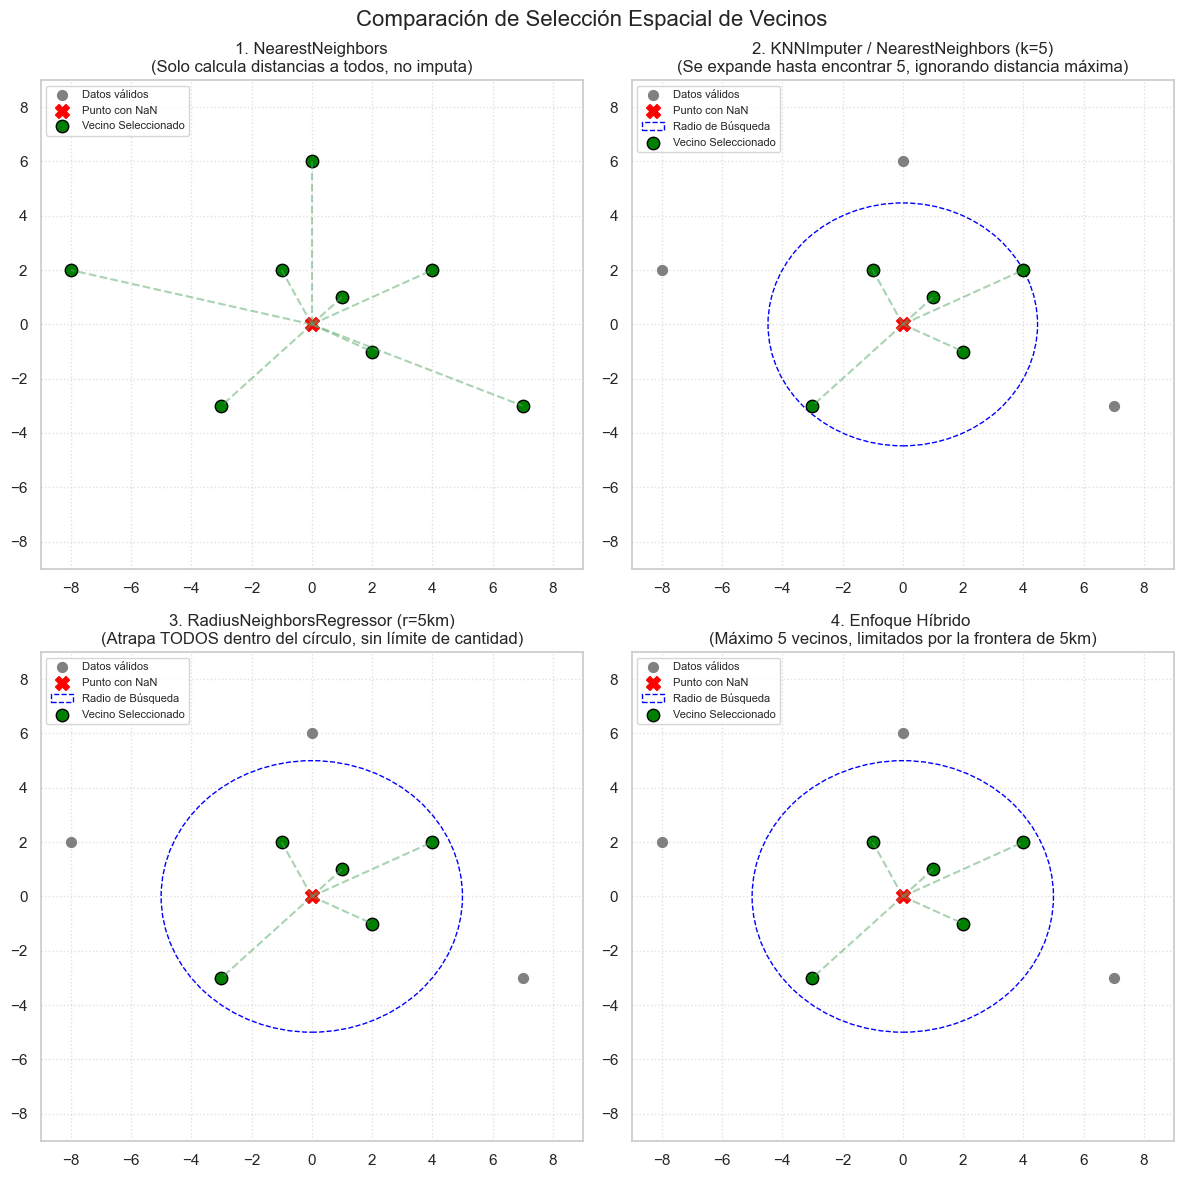

In [59]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Simulamos un escenario geográfico
# Punto central (el que tiene el NaN que queremos imputar)
punto_objetivo = np.array([[0, 0]])

# Vecinos reales con datos (coordenadas x, y en miles de metros)
vecinos = np.array([
    [1, 1], [-1, 2], [2, -1],  # 3 vecinos muy cerca (< 3 km)
    [-3, -3], [4, 2],          # 2 vecinos a media distancia (~4.5 km)
    [0, 6], [7, -3], [-8, 2]   # 3 vecinos muy lejos (> 6 km)
])

# 2. Configuración del gráfico
fig, axs = plt.subplots(2, 2, figsize=(12, 12))
fig.suptitle('Comparación de Selección Espacial de Vecinos', fontsize=16)

# Función auxiliar para dibujar
def plot_scenario(ax, title, circle_radius=None, selected_indices=[]):
    ax.scatter(vecinos[:, 0], vecinos[:, 1], c='gray', label='Datos válidos', s=50)
    ax.scatter(punto_objetivo[:, 0], punto_objetivo[:, 1], c='red', marker='X', s=100, label='Punto con NaN')
    
    if circle_radius:
        circle = plt.Circle((0, 0), circle_radius, color='blue', fill=False, linestyle='--', label=f'Radio de Búsqueda')
        ax.add_patch(circle)
        
    for idx in selected_indices:
        ax.scatter(vecinos[idx, 0], vecinos[idx, 1], c='green', s=80, edgecolors='black', label='Vecino Seleccionado' if idx==selected_indices[0] else "")
        ax.plot([0, vecinos[idx, 0]], [0, vecinos[idx, 1]], 'g--', alpha=0.5)
        
    ax.set_xlim(-9, 9)
    ax.set_ylim(-9, 9)
    ax.set_title(title)
    ax.grid(True, linestyle=':', alpha=0.6)
    # Evitar duplicar leyendas
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper left', fontsize=8)

# --- PANEL 1: NearestNeighbors (Solo mide) ---
# Calcula distancias a TODOS, pero no imputa nada. Es la "cinta métrica".
plot_scenario(axs[0, 0], '1. NearestNeighbors\n(Solo calcula distancias a todos, no imputa)', selected_indices=range(8))

# --- PANEL 2: KNNImputer / KNeighborsRegressor (k=5) ---
# Se expande ciegamente hasta atrapar exactamente 5 puntos.
distancias = np.linalg.norm(vecinos, axis=1)
indices_knn = np.argsort(distancias)[:5]
radio_knn = distancias[indices_knn[-1]] # El radio del vecino más lejano de los 5
plot_scenario(axs[0, 1], '2. KNNImputer / NearestNeighbors (k=5)\n(Se expande hasta encontrar 5, ignorando distancia máxima)', circle_radius=radio_knn, selected_indices=indices_knn)

# --- PANEL 3: RadiusNeighborsRegressor (Radio = 5km) ---
# Toma absolutamente TODOS los puntos dentro de 5km (pueden ser 3, 5 o 20).
radio_fijo = 5.0
indices_radius = np.where(distancias <= radio_fijo)[0]
plot_scenario(axs[1, 0], '3. RadiusNeighborsRegressor (r=5km)\n(Atrapa TODOS dentro del círculo, sin límite de cantidad)', circle_radius=radio_fijo, selected_indices=indices_radius)

# --- PANEL 4: Tu Enfoque Híbrido (k=5 y max_dist=5km) ---
# Máximo 5 puntos, pero descarta los que estén fuera del radio de 5km.
indices_hibridos = [idx for idx in indices_knn if distancias[idx] <= radio_fijo]
plot_scenario(axs[1, 1], '4. Enfoque Híbrido \n(Máximo 5 vecinos, limitados por la frontera de 5km)', circle_radius=radio_fijo, selected_indices=indices_hibridos)

plt.tight_layout()
plt.show()

# QC DE VALORES IMPUTADOS

### 1. Inspeccion visual en mapa

Se procede a realizar un QC de los valores imputados de acuerdo a distancias. Esto es para inspeccionar si hay valores que fueron imputados con valores vecinos que estan muy lejos de ellos. Lo cual no tendria sentido desde el punto de vista geologico. Se considera una distancia de 5 Km como un criterio geologico de distancia afectable

In [60]:
qc_df_final.sort_values(by="distancia_promedio_al_vecino_m", ascending=False).head(15)

,id_bd_sinkhole,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,overburden_resistance_numeric_was_nan,depth_drift_clean_was_nan,working_thickness_numeric_was_nan,distancia_promedio_al_vecino_m
370,FR-SIN-371,2.000000,85.000000,2.250000,False,False,True,50385.938345
372,FR-SIN-373,2.000000,157.000000,2.250000,False,False,True,50294.534036
371,FR-SIN-372,2.000000,138.520083,2.250000,False,True,True,50232.434892
369,FR-SIN-370,2.000000,95.000000,2.250000,False,False,True,50018.058527
123,FR-SIN-124,1.000000,25.000000,2.299972,False,False,True,23968.977308
514,DEU-SIN-03,2.000000,162.000000,1.940920,False,False,True,13370.802589
513,DEU-SIN-02,2.000000,125.000000,1.957569,False,False,True,8827.905261
320,FR-SIN-321,1.000000,50.000000,2.250000,False,False,True,7992.133942
319,FR-SIN-320,1.000000,50.000000,2.250000,False,False,True,7856.601561
321,FR-SIN-322,1.000000,50.000000,2.250000,False,True,True,7676.842461


Valores por arriba de 5000 metros seran eliminados para la imputacion? 
O a su vez, se podria decirle al k-means que cuando tengamos valores mas lejanos de 5km no los tome en cuenta? Tiene sentido esto?

### 2. Matriz de correlacion

#### 2.1. Antes de la imputacion

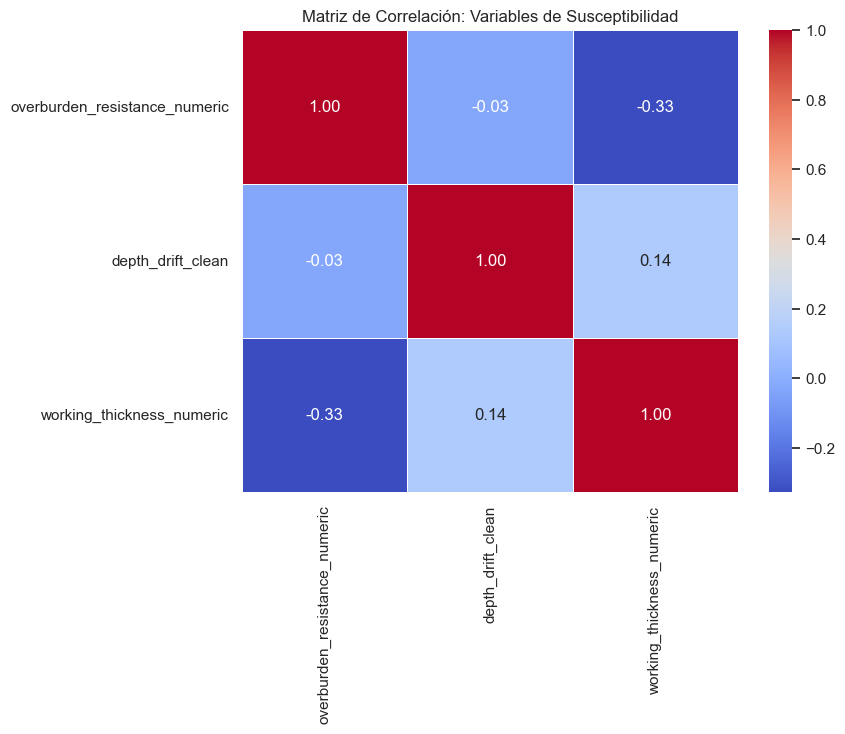

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

# Definimos las variables del modelo
columnas_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# Calculamos la matriz de correlación
matriz_corr = df_susceptibilidad[columnas_modelo].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlación: Variables de Susceptibilidad')
plt.show()

### 2.2. Despues de la imputacion

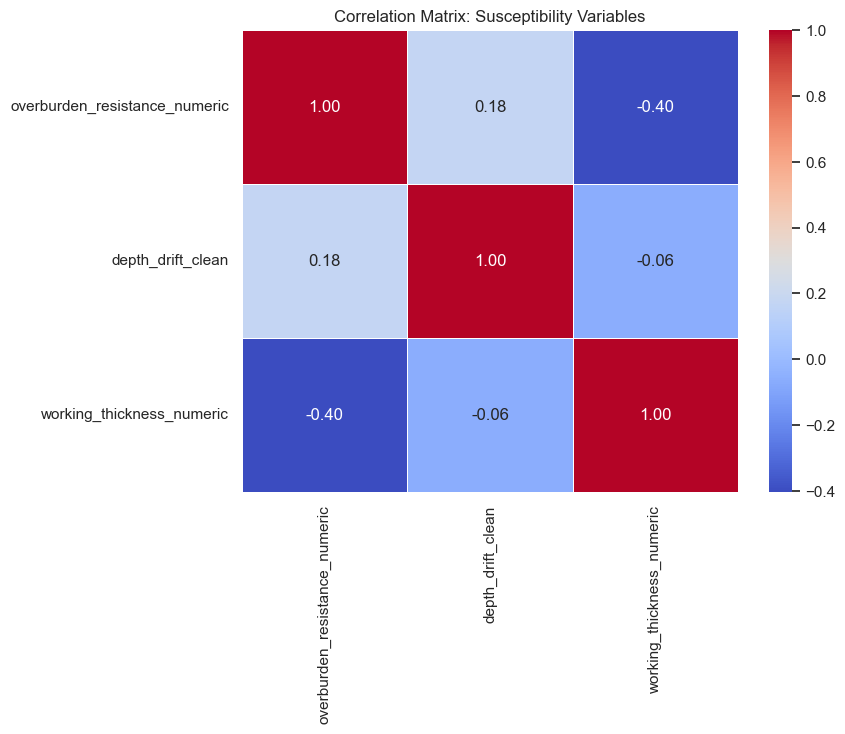

In [62]:
# Definimos las variables del modelo
columnas_modelo = [
    'overburden_resistance_numeric', 
    'depth_drift_clean', 
    'working_thickness_numeric'
]

# Calculamos la matriz de correlación
matriz_corr = df_final_imputed[columnas_modelo].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix: Susceptibility Variables')
plt.show()

### 3. ANALISIS DE COLINEALIDAD

### 3.1 Antes de la imputacion

In [63]:
# ANALISIS DE COLINEALIDAD
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Calculo del VIF (Variance Inflation Factor)

"""
- VIF = 1: No correlation.
- 1 < VIF < 5: Moderate correlation. Generally acceptable and does not requiere variable elimination.
- VIF > 5: Critical multicollinearity. The model coefficients may be unreliable.
- VIF > 10: You must eliminate one of the variables involved because they are redundant.
"""

# 1. Filtramos solo las variables de interés y eliminamos filas con nulos para el test
df_vif = df_susceptibilidad[['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']].dropna()

# 2. Es obligatorio añadir una columna constante para el cálculo matemático
X = add_constant(df_vif)

# 3. Calculamos el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# Mostramos resultados (quitando la fila de la constante)
print("--- RESULTADOS DEL ANÁLISIS VIF ---")
print(vif_data[vif_data["Variable"] != "const"].sort_values(by="VIF", ascending=False))

--- RESULTADOS DEL ANÁLISIS VIF ---
                        Variable       VIF
3      working_thickness_numeric  1.140006
1  overburden_resistance_numeric  1.124817
2              depth_drift_clean  1.020537


### 3.2. Despues de la imputacion

In [64]:
# 1. Filtramos solo las variables de interés y eliminamos filas con nulos para el test
df_vif_imputed = df_final_imputed[['overburden_resistance_numeric', 'depth_drift_clean', 'working_thickness_numeric']].dropna()

# 2. Es obligatorio añadir una columna constante para el cálculo matemático
X = add_constant(df_vif_imputed)

# 3. Calculamos el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(len(X.columns))]

# Mostramos resultados (quitando la fila de la constante)
print("---------------- VIF RESULTS-----------------")
print(vif_data[vif_data["Variable"] != "const"].sort_values(by="VIF", ascending=False))

---------------- VIF RESULTS-----------------
                        Variable       VIF
1  overburden_resistance_numeric  1.227942
3      working_thickness_numeric  1.194572
2              depth_drift_clean  1.031832


### 4. CORRECCION DE OVERBURDEN RESISTANCE NUMERIC

In [65]:
df_final_imputed.overburden_resistance_numeric.unique()

array([1.        , 2.        , 3.        , 2.00578871, 2.01104111,
       2.00883719, 2.00941099, 2.00885643, 2.00859195, 2.01202019,
       2.01173265, 2.0111063 , 2.01112932, 2.01112745, 2.01112244,
       2.01125235, 2.0115987 , 2.01160619, 2.01100186, 2.0110078 ,
       2.0114563 , 2.01150161, 2.01127817, 2.01130892, 2.01105069,
       2.01105072, 2.01138351, 2.01106917, 2.01229295])

In [66]:
#  CORRECION DE LA VARIABLE CATEGORICA
# 1. Redondeamos los valores al entero más cercano y forzamos el tipo a 'int'
df_final_imputed['overburden_resistance_numeric'] = df_final_imputed['overburden_resistance_numeric'].round().astype(int)

# 2. Verificamos que ahora solo existan las categorías 1, 2 y 3
valores_unicos = df_final_imputed['overburden_resistance_numeric'].unique()
print(f"Valores únicos tras la corrección: {valores_unicos}")

# 3. Vemos cuántos registros quedaron en cada categoría
print("\nDistribución de la variable:")
print(df_final_imputed['overburden_resistance_numeric'].value_counts().sort_index())

Valores únicos tras la corrección: [1 2 3]

Distribución de la variable:
overburden_resistance_numeric
1    1174
2     192
3      81
Name: count, dtype: int64


In [67]:
df_final_imputed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 7 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   x_laea                          1447 non-null   float64
 1   y_laea                          1447 non-null   float64
 2   overburden_resistance_numeric   1447 non-null   int64  
 3   depth_drift_clean               1447 non-null   float64
 4   working_thickness_numeric       1447 non-null   float64
 5   id_bd_sinkhole                  1447 non-null   object 
 6   distancia_promedio_al_vecino_m  1447 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 122.7+ KB


In [68]:
df_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 6 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1814 non-null   object 
 1   x_wgs84                        1814 non-null   float64
 2   y_wgs84                        1814 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1285 non-null   float64
 5   working_thickness_numeric      1051 non-null   float64
dtypes: float64(5), object(1)
memory usage: 85.2+ KB


In [69]:
df_susceptibilidad_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1447 non-null   object 
 1   x_wgs84                        1447 non-null   float64
 2   y_wgs84                        1447 non-null   float64
 3   overburden_resistance_numeric  1421 non-null   float64
 4   depth_drift_clean              1285 non-null   float64
 5   working_thickness_numeric      1051 non-null   float64
 6   x_laea                         1447 non-null   float64
 7   y_laea                         1447 non-null   float64
dtypes: float64(7), object(1)
memory usage: 134.0+ KB


### 5. CORRELACION ENTRE VARIABLES

### RELACION ENTRE VARIABLES DEL MODELO

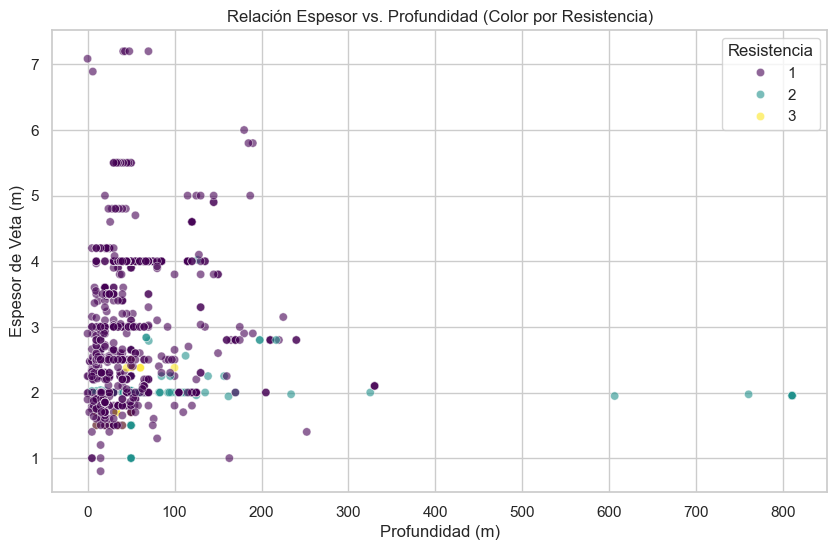

In [70]:
# 2. RELACION ESPESOR DE CAPA VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_final_imputed, 
    x='depth_drift_clean', 
    y='working_thickness_numeric', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Relación Espesor vs. Profundidad (Color por Resistencia)')
plt.xlabel('Profundidad (m)')
plt.ylabel('Espesor de Veta (m)')
plt.legend(title='Resistencia')
plt.show()


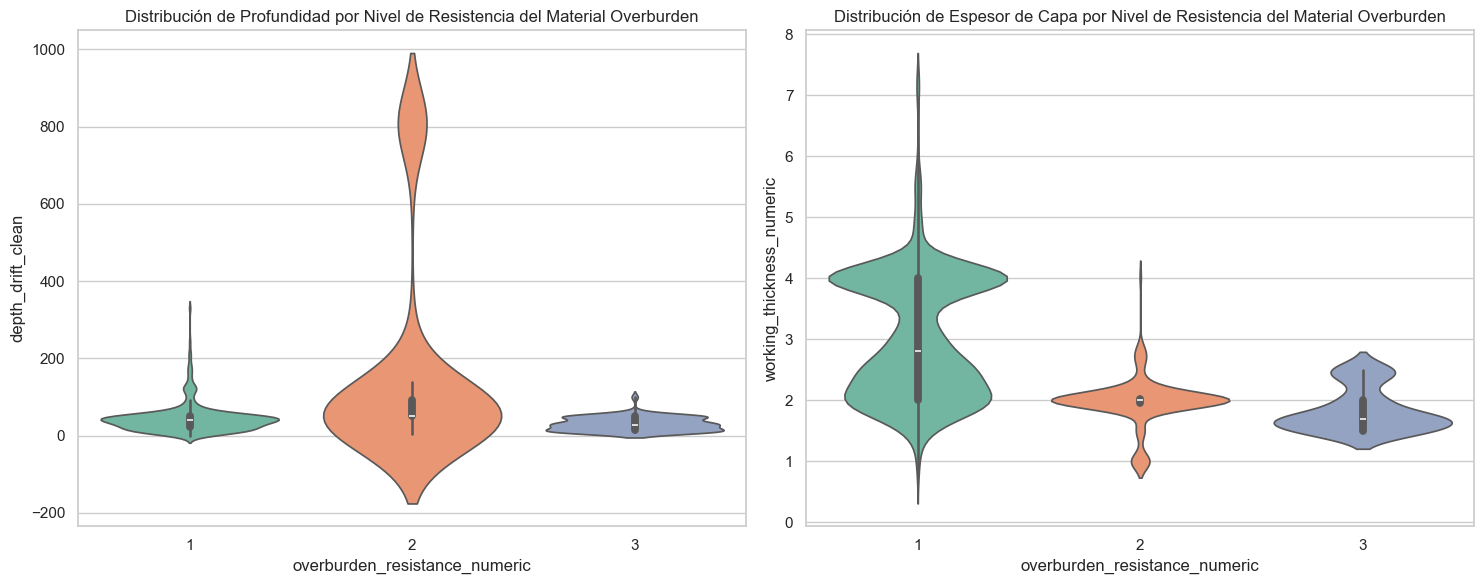

In [71]:
# 3. DISTRIBUCION DE DENSIDADES

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Distribución de Profundidad por Resistencia
sns.violinplot(
    x='overburden_resistance_numeric', 
    y='depth_drift_clean', 
    data=df_final_imputed, 
    ax=ax1, palette='Set2', 
    hue='overburden_resistance_numeric', 
    legend=False  )

ax1.set_title('Distribución de Profundidad por Nivel de Resistencia del Material Overburden')

# Distribución de Espesor por Resistencia
sns.violinplot(
    x='overburden_resistance_numeric', 
    y='working_thickness_numeric', 
    data=df_final_imputed, 
    ax=ax2, palette='Set2', 
    hue='overburden_resistance_numeric', 
    legend=False  )

ax2.set_title('Distribución de Espesor de Capa por Nivel de Resistencia del Material Overburden')

plt.tight_layout()
plt.show()

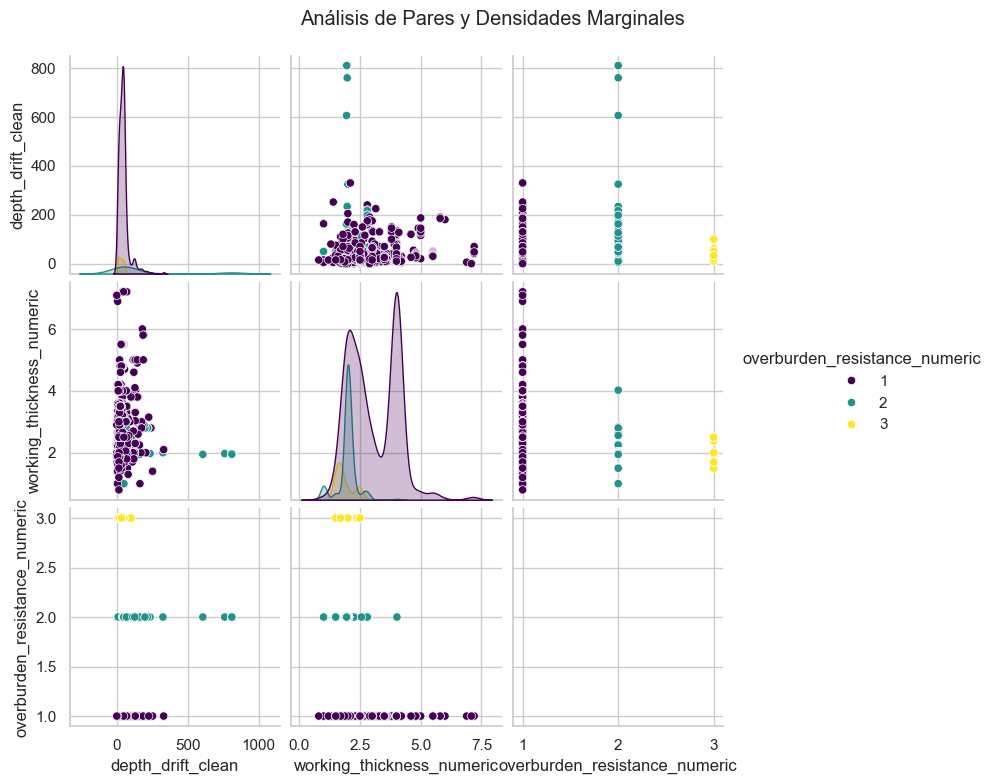

In [72]:
# PAIRPLOT DE TENDENCIAS

sns.pairplot(df_final_imputed, 
             vars=['depth_drift_clean', 'working_thickness_numeric', 'overburden_resistance_numeric'], 
             hue='overburden_resistance_numeric', 
             palette='viridis', 
             diag_kind='kde'
             )

plt.suptitle('Análisis de Pares y Densidades Marginales', y=1.04)
plt.show()

# MODELO DE SUSCEPTIBILIDAD

In [73]:
df_final_imputed.overburden_resistance_numeric.unique()

array([1, 2, 3])

In [74]:
modelo_granular_susceptibilidad = df_final_imputed.copy()
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m
0,3.741432e+06,2.529762e+06,1,12.5,2.5,FR-SIN-01,53.395869
1,3.741325e+06,2.530005e+06,1,37.5,2.5,FR-SIN-02,125.707557
2,3.741777e+06,2.529926e+06,1,37.5,2.5,FR-SIN-03,110.569185
3,3.741867e+06,2.529898e+06,1,12.5,2.5,FR-SIN-04,97.623191
4,3.741082e+06,2.528882e+06,1,37.5,2.5,FR-SIN-05,132.858724


## 1. Normalizacion de variable depth_drift_clean

In [75]:
import numpy as np

# 1. Transformación logarítmica para reducir el sesgo
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'])

# 2. Normalización Min-Max Inversa sobre el logaritmo
log_min, log_max = log_depth.min(), log_depth.max()
modelo_granular_susceptibilidad['depth_drift_norm'] = (log_max - log_depth) / (log_max - log_min)

# 3. Visualizar resultados
modelo_granular_susceptibilidad[["depth_drift_clean", "depth_drift_norm"]]

,depth_drift_clean,depth_drift_norm
0,12.5,0.611438
1,37.5,0.454985
2,37.5,0.454985
3,12.5,0.611438
4,37.5,0.454985
...,...,...
1809,41.0,0.441995
1810,43.0,0.435050
1811,48.0,0.418981
1812,6.0,0.709491


## 2. Normalizacion de variable working_thickness_numeric

En este caso a diferencia de depth_drift_clean, esta variable no tiene valores atípicos extremos (el máximo está cerca del grueso de los datos) y el rango es pequeño. La normalización lineal preservará perfectamente la estructura bimodal, lo cual es útil si esos dos picos representan dos tipos diferentes de vetas o métodos de minería.

In [76]:
# 1. Definimos los límites basados en tus datos
thickness_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thickness_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# 2. Realizamos una normalización directa (Mayor espesor = Mayor Susceptibilidad)
modelo_granular_susceptibilidad['working_thickness_norm'] = (
    (modelo_granular_susceptibilidad['working_thickness_numeric'] - thickness_min) / 
    (thickness_max - thickness_min)
)

# 3. Visualizamos resultados
modelo_granular_susceptibilidad[["working_thickness_numeric", "working_thickness_norm"]]

,working_thickness_numeric,working_thickness_norm
0,2.500000,0.265625
1,2.500000,0.265625
2,2.500000,0.265625
3,2.500000,0.265625
4,2.500000,0.265625
...,...,...
1809,7.200000,1.000000
1810,7.200000,1.000000
1811,7.200000,1.000000
1812,6.890551,0.951649


## 3. Normalizacion de variable overburden_resistance_numeric

In [77]:
# 1. Funcion de normalizacion por frecuencia
def get_weights(df, column_name):
    # Calculamos la frecuencia normalizada
    freq = df[column_name].value_counts(normalize=True)
    # Creamos el score normalizado (Max = 1.0)
    score = (freq / freq.max()).to_dict()
    return score

# 2. aplicamos la funcion
weights_res = get_weights(modelo_granular_susceptibilidad, 'overburden_resistance_numeric')

# 3. Mapeo la funcion en cada sinkhole
modelo_granular_susceptibilidad['overburden_resistance_norm'] = modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(weights_res).astype(float)

In [78]:
modelo_granular_susceptibilidad.overburden_resistance_norm.unique()

array([1.        , 0.16354344, 0.06899489])

In [79]:
# Normalizacion por criterio experto
# 1 (Weak) -> 1.0 (Max Susceptibilidad)
# 2 (Medium) -> 0.35
# 3 (Resistant) -> 0.10 (Min Susceptibilidad)

# Si se asigna de acuerdo a la frecuencia normalizada, la distribucion seria (1, 0.14, 0.069)

# En este caso se decide asignar valores mas equilibrados para que el peso de los valores con susecptibilidad 1 no sea tan determinante en la asignacion del "riesgo" 
mapeo_riesgo = {1: 1.0, 2: 0.35, 3: 0.10}

modelo_granular_susceptibilidad['overburden_resistance_norm_expert'] = (
    modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(mapeo_riesgo)
)

In [80]:
modelo_granular_susceptibilidad.overburden_resistance_norm_expert.unique()

array([1.  , 0.35, 0.1 ])

In [81]:
modelo_granular_susceptibilidad.head(10)

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert
0,3.741432e+06,2.529762e+06,1,12.5,2.5,FR-SIN-01,53.395869,0.611438,0.265625,1.0,1.0
1,3.741325e+06,2.530005e+06,1,37.5,2.5,FR-SIN-02,125.707557,0.454985,0.265625,1.0,1.0
2,3.741777e+06,2.529926e+06,1,37.5,2.5,FR-SIN-03,110.569185,0.454985,0.265625,1.0,1.0
3,3.741867e+06,2.529898e+06,1,12.5,2.5,FR-SIN-04,97.623191,0.611438,0.265625,1.0,1.0
4,3.741082e+06,2.528882e+06,1,37.5,2.5,FR-SIN-05,132.858724,0.454985,0.265625,1.0,1.0
5,3.741190e+06,2.529857e+06,1,37.5,2.5,FR-SIN-06,138.945420,0.454985,0.265625,1.0,1.0
6,3.741311e+06,2.529984e+06,1,37.5,2.5,FR-SIN-07,118.948945,0.454985,0.265625,1.0,1.0
7,3.740790e+06,2.528731e+06,1,40.0,2.5,FR-SIN-08,181.930780,0.445592,0.265625,1.0,1.0
8,3.740805e+06,2.528830e+06,1,40.0,2.5,FR-SIN-09,154.678877,0.445592,0.265625,1.0,1.0
9,3.741064e+06,2.528811e+06,1,50.0,2.5,FR-SIN-10,162.220316,0.413009,0.265625,1.0,1.0


### **ASIGNACION DE PESOS - METODO HEURÍSTICO**

In [82]:
import pandas as pd

# --- 1. DEFINICIÓN DE RANGOS (BINS) ---
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)
# Para resistancia de material se utilizar 

# --- 3. CÁLCULO DEL SCORE FINAL (S) ---
# Definimos los coeficientes de importancia - Criterio experto
profundidad = 0.4
espesor = 0.3
resistencia = 0.3

modelo_granular_susceptibilidad['Susceptibility_Score_Expert'] = (
    (modelo_granular_susceptibilidad['depth_drift_norm'] * profundidad) +
    (modelo_granular_susceptibilidad['working_thickness_norm'] * espesor) +
    (modelo_granular_susceptibilidad['overburden_resistance_norm_expert'] * resistencia)
)

In [83]:
modelo_granular_susceptibilidad

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert
0,3.741432e+06,2.529762e+06,1,12.5,2.500000,FR-SIN-01,53.395869,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263
1,3.741325e+06,2.530005e+06,1,37.5,2.500000,FR-SIN-02,125.707557,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681
2,3.741777e+06,2.529926e+06,1,37.5,2.500000,FR-SIN-03,110.569185,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681
3,3.741867e+06,2.529898e+06,1,12.5,2.500000,FR-SIN-04,97.623191,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263
4,3.741082e+06,2.528882e+06,1,37.5,2.500000,FR-SIN-05,132.858724,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1809,4.979717e+06,3.060871e+06,1,41.0,7.200000,POL-SIN- 901,114.920492,0.441995,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.776798
1810,4.979732e+06,3.060872e+06,1,43.0,7.200000,POL-SIN- 902,114.522724,0.435050,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.774020
1811,4.979757e+06,3.060851e+06,1,48.0,7.200000,POL-SIN- 903,119.353352,0.418981,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.767592
1812,4.979110e+06,3.062105e+06,1,6.0,6.890551,POL-SIN- 904,1114.946311,0.709491,0.951649,1.0,1.0,Muy Somero (0-15m),Masivo (>5m),0.869291


### **ASIGNACION DE PESOS - METODO PROBABILISTICO**

In [84]:
import pandas as pd

# --- 1. DEFINICIÓN DE RANGOS (BINS) ---
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

# --- 3. GENERACIÓN DINÁMICA DE TABLAS DE PESOS PROBABILISTICOS ---
def get_weights(df, column_name):
    """
    Asigna pesos dependiendo de su frecuencia de ocurrencia. Es decir, asigna un peso basándose en qué tan frecuente es cada valor en comparación con el valor más común 
    Por eso se crearon rangos para profundidad y para espesor de capa (range_depth y range_thick)
    """
    # Calculamos la frecuencia normalizada
    freq = df[column_name].value_counts(normalize=True)
    # Creamos el score normalizado (Max = 1.0)
    score = (freq / freq.max()).to_dict()
    return score

weights_depth = get_weights(modelo_granular_susceptibilidad, 'depth_drift_clean')
weights_thick = get_weights(modelo_granular_susceptibilidad, 'working_thickness_numeric')
weights_res = get_weights(modelo_granular_susceptibilidad, 'overburden_resistance_numeric')

# --- 4. MAPEO DE PESOS A LAS FILAS ---
modelo_granular_susceptibilidad['F_depth'] = modelo_granular_susceptibilidad['depth_drift_clean'].map(weights_depth).astype(float)
modelo_granular_susceptibilidad['F_thickness'] = modelo_granular_susceptibilidad['working_thickness_numeric'].map(weights_thick).astype(float)
modelo_granular_susceptibilidad['F_resistance'] = modelo_granular_susceptibilidad['overburden_resistance_numeric'].map(weights_res).astype(float)

# --- 5. CÁLCULO DEL SCORE FINAL (S) ---
# Definimos los coeficientes de importancia - Criterio experto 
# (SE DECIDE USAR CRITERIO EXPERTO EN LUGAR DE LOS PESOS PROBABILISTICOS DEBIDO A LA INCOMPLETITUD DEL CATALGO DE SINKHOLES)
profundidad = 0.4
espesor = 0.3
resistencia = 0.3

# Asignar pesos 
modelo_granular_susceptibilidad['Susceptibility_Score_Probabilistico'] = (
    (modelo_granular_susceptibilidad['F_depth'] * profundidad) +
    (modelo_granular_susceptibilidad['F_thickness'] * espesor) +
    (modelo_granular_susceptibilidad['F_resistance'] * resistencia)
)

In [85]:
modelo_granular_susceptibilidad

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico
0,3.741432e+06,2.529762e+06,1,12.5,2.500000,FR-SIN-01,53.395869,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583
1,3.741325e+06,2.530005e+06,1,37.5,2.500000,FR-SIN-02,125.707557,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593
2,3.741777e+06,2.529926e+06,1,37.5,2.500000,FR-SIN-03,110.569185,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593
3,3.741867e+06,2.529898e+06,1,12.5,2.500000,FR-SIN-04,97.623191,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583
4,3.741082e+06,2.528882e+06,1,37.5,2.500000,FR-SIN-05,132.858724,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1809,4.979717e+06,3.060871e+06,1,41.0,7.200000,POL-SIN- 901,114.920492,0.441995,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.776798,0.015464,0.010899,1.0,0.309455
1810,4.979732e+06,3.060872e+06,1,43.0,7.200000,POL-SIN- 902,114.522724,0.435050,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.774020,0.010309,0.010899,1.0,0.307393
1811,4.979757e+06,3.060851e+06,1,48.0,7.200000,POL-SIN- 903,119.353352,0.418981,1.000000,1.0,1.0,Medio (30-60m),Masivo (>5m),0.767592,0.005155,0.010899,1.0,0.305332
1812,4.979110e+06,3.062105e+06,1,6.0,6.890551,POL-SIN- 904,1114.946311,0.709491,0.951649,1.0,1.0,Muy Somero (0-15m),Masivo (>5m),0.869291,0.030928,0.002725,1.0,0.313189


## VISUALIZACION DE RESULTADOS

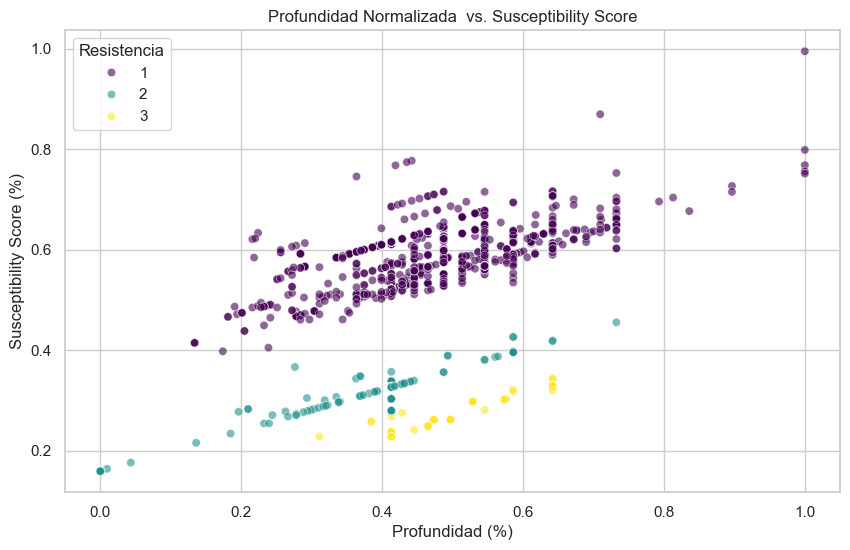

In [86]:
# 2. GRAFICO
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='depth_drift_norm', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Profundidad Normalizada  vs. Susceptibility Score')
plt.xlabel('Profundidad (%)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistencia')
plt.show()

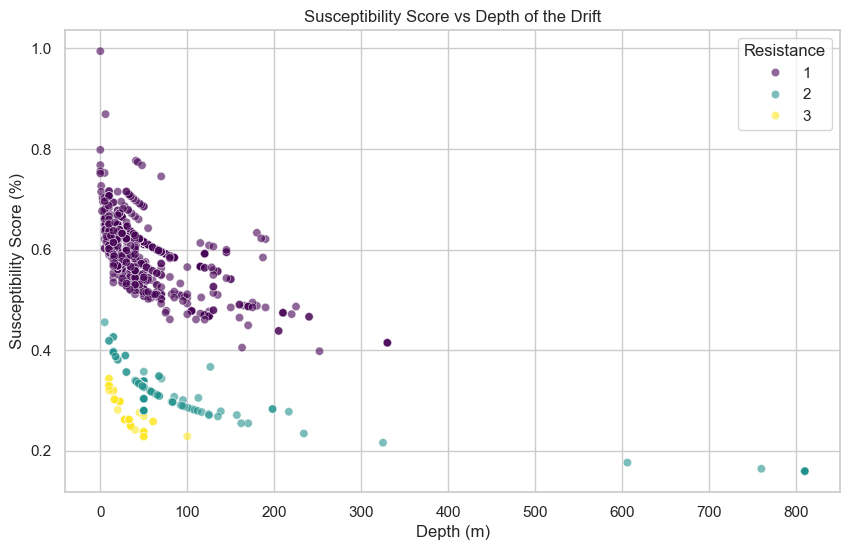

In [87]:
# 2. RELACION SUCEPTIBILIDAD VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='depth_drift_clean', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Susceptibility Score vs Depth of the Drift')
plt.xlabel('Depth (m)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistance')
plt.show()

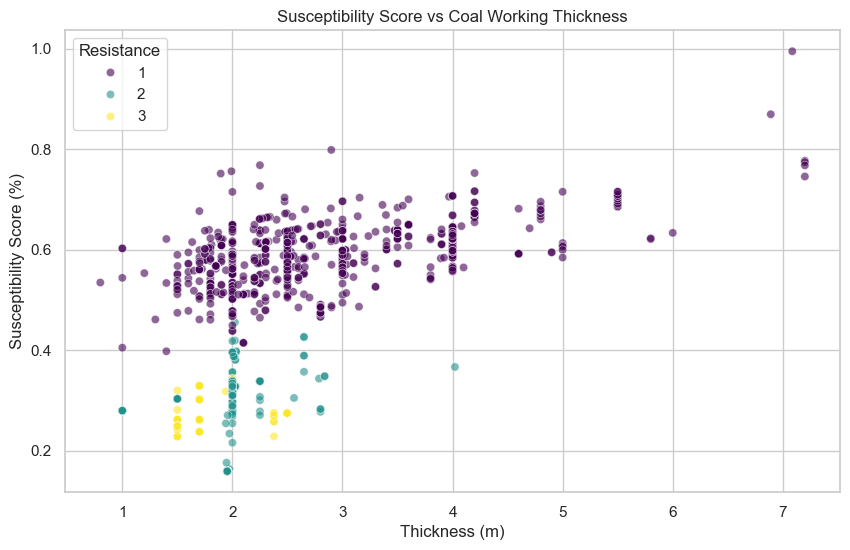

In [88]:
# 2. RELACION SUCEPTIBILIDAD VS PROFUNDIDAD

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=modelo_granular_susceptibilidad, 
    x='working_thickness_numeric', 
    y='Susceptibility_Score_Expert', 
    hue='overburden_resistance_numeric', 
    palette='viridis',
    alpha=0.6
)

plt.title('Susceptibility Score vs Coal Working Thickness')
plt.xlabel('Thickness (m)')
plt.ylabel('Susceptibility Score (%)')
plt.legend(title='Resistance')
plt.show()

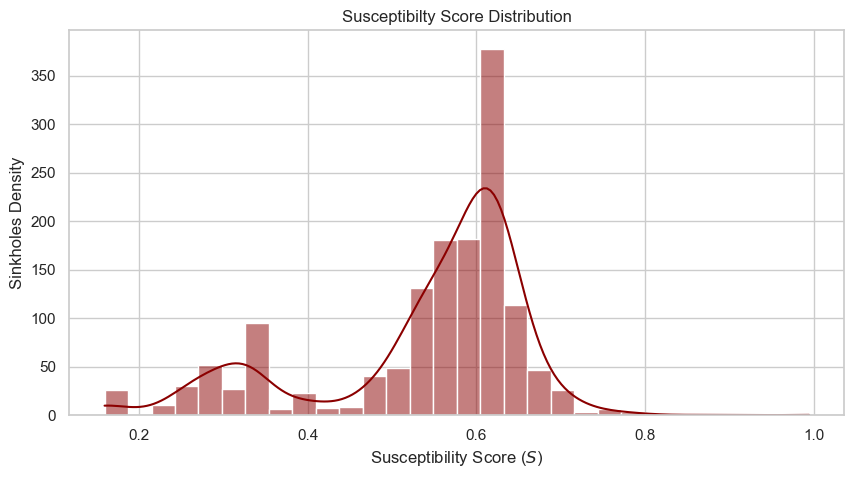

In [89]:
# Visualización de la distribución del Score Resultante
plt.figure(figsize=(10, 5))
#sns.histplot(modelo_granular_susceptibilidad[modelo_granular_susceptibilidad["overburden_resistance_numeric"] == 1]['Susceptibility_Score'], kde=True, color='darkred')
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=30, kde=True, color='darkred')
plt.title('Susceptibilty Score Distribution')
plt.xlabel('Susceptibility Score ($S$)')
plt.ylabel('Sinkholes Density')
plt.show()

In [90]:
bins_depth = [0, 15, 30, 60, 1000]
labels_depth = ['Muy Somero (0-15m)', 'Somero (15-30m)', 'Medio (30-60m)', 'Profundo (>60m)']

bins_thick = [0, 1, 2, 3, 5, 20]
labels_thick = ['Delgado (0-1m)', 'Medio (1-2m)', 'Grueso (2-3m)', 'Muy Grueso (3-5m)', 'Masivo (>5m)']

# --- 2. ASIGNACIÓN DE CATEGORÍAS ---
modelo_granular_susceptibilidad['range_depth'] = pd.cut(modelo_granular_susceptibilidad['depth_drift_clean'], bins=bins_depth, labels=labels_depth)
modelo_granular_susceptibilidad['range_thick'] = pd.cut(modelo_granular_susceptibilidad['working_thickness_numeric'], bins=bins_thick, labels=labels_thick)

In [91]:
modelo_granular_susceptibilidad.range_depth.unique()

['Muy Somero (0-15m)', 'Medio (30-60m)', 'Somero (15-30m)', 'Profundo (>60m)', NaN]
Categories (4, object): ['Muy Somero (0-15m)' < 'Somero (15-30m)' < 'Medio (30-60m)' < 'Profundo (>60m)']

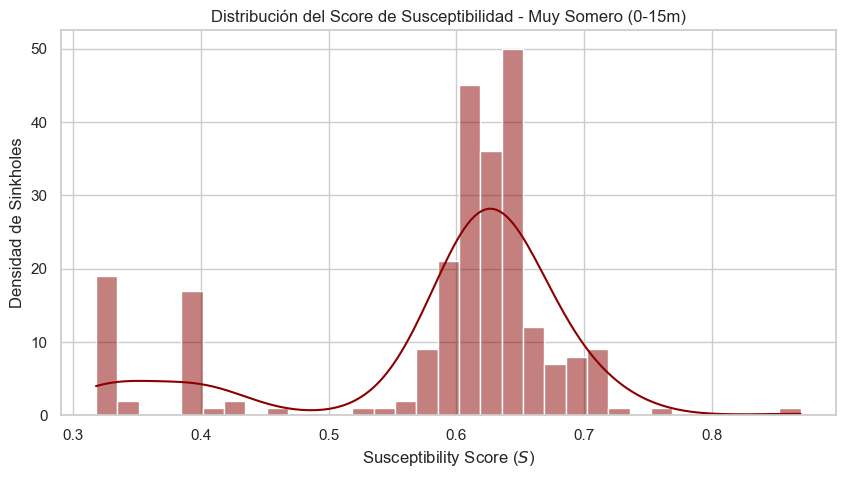

In [92]:
# Visualización de la distribución del Score Resultante
plt.figure(figsize=(10, 5))
profundidad = "Muy Somero (0-15m)"
sns.histplot(modelo_granular_susceptibilidad[modelo_granular_susceptibilidad["range_depth"] == profundidad]['Susceptibility_Score_Expert'], kde=True, color='darkred')
#sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score'], kde=True, color='darkred')
plt.title(f'Distribución del Score de Susceptibilidad - {profundidad}')
plt.xlabel('Susceptibility Score ($S$)')
plt.ylabel('Densidad de Sinkholes')
plt.show()

In [93]:
# Comparar el Score Final (que ya calculamos con los 3 factores) 
# contra los rangos de profundidad para ver la tendencia
analisis_final = modelo_granular_susceptibilidad.groupby('range_depth', observed=False)['Susceptibility_Score_Expert'].mean()

print("Promedio del Score de Susceptibilidad Final por Rango de Profundidad:")
print(analisis_final)

Promedio del Score de Susceptibilidad Final por Rango de Profundidad:
range_depth
Muy Somero (0-15m)    0.587081
Somero (15-30m)       0.566076
Medio (30-60m)        0.534754
Profundo (>60m)       0.449015
Name: Susceptibility_Score_Expert, dtype: float64


In [94]:
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico
0,3.741432e+06,2.529762e+06,1,12.5,2.5,FR-SIN-01,53.395869,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583
1,3.741325e+06,2.530005e+06,1,37.5,2.5,FR-SIN-02,125.707557,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593
2,3.741777e+06,2.529926e+06,1,37.5,2.5,FR-SIN-03,110.569185,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593
3,3.741867e+06,2.529898e+06,1,12.5,2.5,FR-SIN-04,97.623191,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583
4,3.741082e+06,2.528882e+06,1,37.5,2.5,FR-SIN-05,132.858724,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593


# DISCRETIZACION DE SUSCEPTBILIDAD

### 1. DISCRETIZACION POR AREAS IGUALES DEL CDF

In [95]:
import numpy as np
from scipy import stats

# --- 1. CÁLCULO DE UMBRALES POR ÁREAS (33.3%) ---
# Asegúrate de que df_susceptibilidad es el DataFrame que contiene tu score calculado
datos = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna()

# 1.1. Estimación de la Densidad de Kernel (KDE) para obtener la curva suave
kde = stats.gaussian_kde(datos)

# Creamos un rango denso de 1000 puntos entre el mínimo y el máximo para integrar el área
x_range = np.linspace(datos.min(), datos.max(), 1000)
y_density = kde(x_range)

# 1.2. Determinamos la Cumulative Distribution Function
cdf = np.cumsum(y_density)
cdf /= cdf[-1]  # Normalización del área a 1.0

# 1.3. Encontrar los puntos de corte para el 33.3% y 66.6% del área
# Buscamos en qué valor de X se alcanza cada tercio del área total
limite_bajo_medio = x_range[np.searchsorted(cdf, 0.3333)]
limite_medio_alto = x_range[np.searchsorted(cdf, 0.6666)]

# --- 2. APLICAR LA CLASIFICACIÓN AL DATAFRAME ---
def clasificar_por_area(score):
    if score <= limite_bajo_medio:
        return 'Low'
    elif score <= limite_medio_alto:
        return 'Medium'
    else:
        return 'High'

modelo_granular_susceptibilidad['Discretization_Equal_Prob'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_por_area)

# --- 4. VERIFICACIÓN DE BALANCE ---
conteo = modelo_granular_susceptibilidad['Discretization_Equal_Prob'].value_counts().reindex(['Low', 'Medium', 'High'])
print("\n--- Conteo de Sinkholes por Clase (Áreas Equitativas) ---")
print(conteo)


--- Conteo de Sinkholes por Clase (Áreas Equitativas) ---
Discretization_Equal_Prob
Low       474
Medium    481
High      492
Name: count, dtype: int64


--- Cortes CDF (Equiprobabilidad) ---
Corte 33% (Baja -> Media): 0.5418
Corte 66% (Media -> Alta): 0.6125


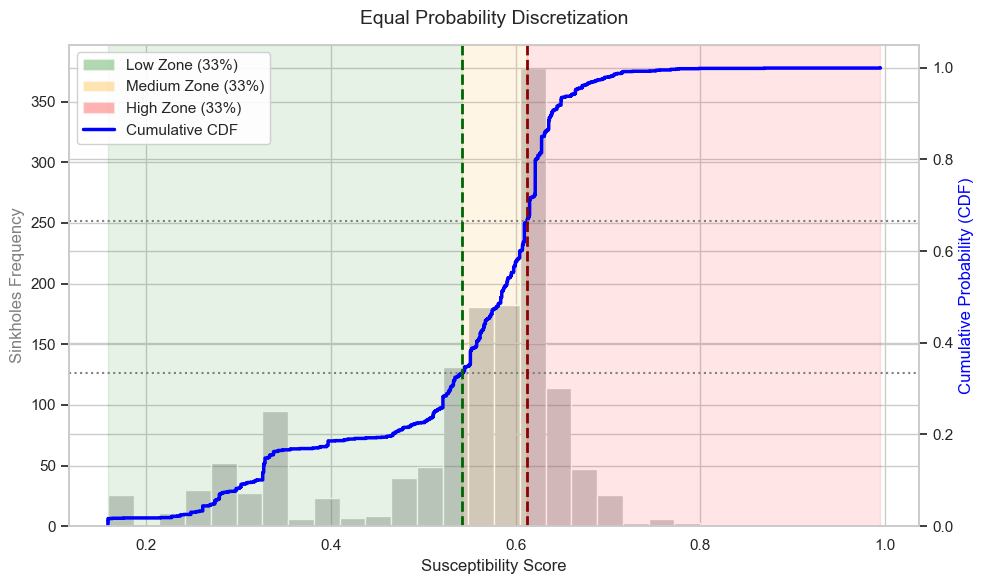

In [96]:
# GRAFICO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. CÁLCULO DE UMBRALES (PERCENTILES EXACTOS) ---
# En un enfoque de CDF, dividir el área en 3 partes iguales es equivalente
# a buscar los percentiles 33.33% y 66.66% directamente en los datos.
datos = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna()

# Calculamos los puntos de corte exactos
limite_bajo_medio = np.percentile(datos, 33.33)
limite_medio_alto = np.percentile(datos, 66.66)

print(f"--- Cortes CDF (Equiprobabilidad) ---")
print(f"Corte 33% (Baja -> Media): {limite_bajo_medio:.4f}")
print(f"Corte 66% (Media -> Alta): {limite_medio_alto:.4f}")

# --- 2. CONFIGURACIÓN DEL GRÁFICO ---
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# --- 3. HISTOGRAMA DE BARRAS (Eje Y Izquierdo: Frecuencia) ---
# Usamos stat='count' para ver el número de registros
ax1 = sns.histplot(data=datos, bins=30, kde=False, color='gray', alpha=0.4, label='Frecuencia (Barras)')
plt.ylabel('Sinkholes Frequency', fontsize=12, color='gray')

# --- 4. CURVA CDF (Eje Y Derecho: Probabilidad) ---
# Creamos un segundo eje Y que comparte el mismo eje X
ax2 = plt.twinx()
sns.ecdfplot(data=datos, color='blue', linewidth=2.5, label='Cumulative CDF', ax=ax2)
ax2.set_ylabel('Cumulative Probability (CDF)', fontsize=12, color='blue')
ax2.set_ylim(0, 1.05) # Aseguramos que el eje Y derecho vaya de 0 a 1

# --- 5. DIBUJAR LAS LÍNEAS DE CORTE Y ZONAS ---
# Líneas Horizontales de Referencia en el eje derecho (CDF)
ax2.axhline(y=0.3333, color='gray', linestyle=':', linewidth=1.5)
ax2.axhline(y=0.6666, color='gray', linestyle=':', linewidth=1.5)

# Líneas Verticales (Cortes en el Score)
plt.axvline(x=limite_bajo_medio, color='darkgreen', linestyle='--', linewidth=2)
plt.axvline(x=limite_medio_alto, color='darkred', linestyle='--', linewidth=2)

# Colorear las Zonas de Riesgo
plt.axvspan(datos.min(), limite_bajo_medio, alpha=0.1, color='green', label='Low Zone (0-33%)')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange', label='Medium Zone (33-66%)')
plt.axvspan(limite_medio_alto, datos.max(), alpha=0.1, color='red', label='High Zone (66-100%)')

# --- 6. DETALLES FINALES ---
plt.title('Equal Probability Discretization', fontsize=14, pad=15)
ax1.set_xlabel('Susceptibility Score', fontsize=12)

# Combinar leyendas de ambos ejes
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
# Añadimos manualmente las zonas de color a la leyenda
from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='green', alpha=0.3, label='Low Zone (33%)'),
    Patch(facecolor='orange', alpha=0.3, label='Medium Zone (33%)'),
    Patch(facecolor='red', alpha=0.3, label='High Zone (33%)'),
    lines_2[0] # La línea azul de la CDF
]
ax2.legend(handles=legend_elements, loc='upper left', frameon=True, facecolor='white', framealpha=0.9)

plt.tight_layout()
plt.show()

In [97]:
modelo_granular_susceptibilidad.head()

,x_laea,y_laea,overburden_resistance_numeric,depth_drift_clean,working_thickness_numeric,id_bd_sinkhole,distancia_promedio_al_vecino_m,depth_drift_norm,working_thickness_norm,overburden_resistance_norm,overburden_resistance_norm_expert,range_depth,range_thick,Susceptibility_Score_Expert,F_depth,F_thickness,F_resistance,Susceptibility_Score_Probabilistico,Discretization_Equal_Prob
0,3.741432e+06,2.529762e+06,1,12.5,2.5,FR-SIN-01,53.395869,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583,High
1,3.741325e+06,2.530005e+06,1,37.5,2.5,FR-SIN-02,125.707557,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593,Medium
2,3.741777e+06,2.529926e+06,1,37.5,2.5,FR-SIN-03,110.569185,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593,Medium
3,3.741867e+06,2.529898e+06,1,12.5,2.5,FR-SIN-04,97.623191,0.611438,0.265625,1.0,1.0,Muy Somero (0-15m),Grueso (2-3m),0.624263,0.154639,0.332425,1.0,0.461583,High
4,3.741082e+06,2.528882e+06,1,37.5,2.5,FR-SIN-05,132.858724,0.454985,0.265625,1.0,1.0,Medio (30-60m),Grueso (2-3m),0.561681,0.072165,0.332425,1.0,0.428593,Medium


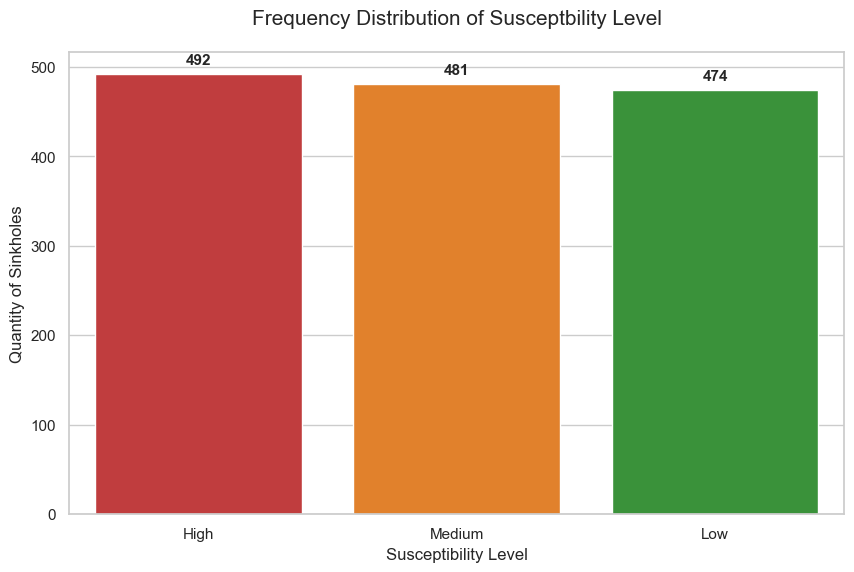

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Equal_Prob', 
    order=orden_niveles, 
    hue='Discretization_Equal_Prob', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')


### 2. DISCRETIZACION MANUAL EN BASE A JUICIO

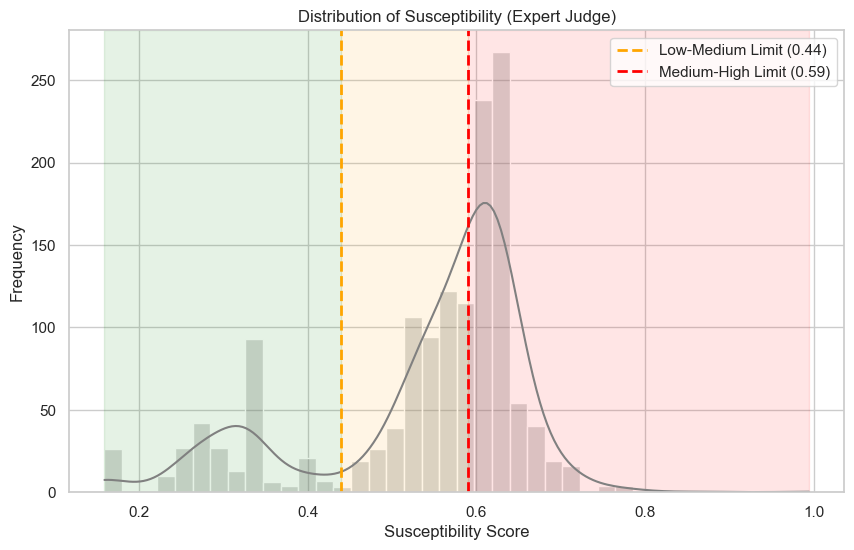


--- Conteo de Sinkholes por Clase ---
Discretization_Expert
High      686
Medium    482
Low       279
Name: count, dtype: int64


In [99]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. OBTENER MÍNIMO Y MÁXIMO DEL SCORE
min_score = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].min()
max_score = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].max()

# 2. DEFINIR LOS LÍMITES MANUALES
# Limite inferior
limite_bajo_medio = 0.44
# Limite superior
limite_medio_alto = 0.59

# 3. APLICAR LA CLASIFICACIÓN
def clasificar_intervalos(score):
    if score <= limite_bajo_medio:
        return 'Low'
    elif score <= limite_medio_alto:
        return 'Medium'
    else:
        return 'High'

modelo_granular_susceptibilidad['Discretization_Expert'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_intervalos)

# 4. VISUALIZACIÓN DE LA DISTRIBUCIÓN CON LOS CORTES
plt.figure(figsize=(10, 6))

# Histograma de fondo
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=40, kde=True, color='gray', alpha=0.3)

# Dibujar las líneas de corte
plt.axvline(limite_bajo_medio, color='orange', linestyle='--', linewidth=2, label=f'Low-Medium Limit ({limite_bajo_medio:.2f})')
plt.axvline(limite_medio_alto, color='red', linestyle='--', linewidth=2, label=f'Medium-High Limit ({limite_medio_alto:.2f})')

# Colorear las áreas (opcional para dar efecto visual)
plt.axvspan(min_score, limite_bajo_medio, alpha=0.1, color='green')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange')
plt.axvspan(limite_medio_alto, max_score, alpha=0.1, color='red')

plt.title('Distribution of Susceptibility (Expert Judge)')
plt.xlabel('Susceptibility Score')
plt.ylabel('Frequency')
plt.legend()
plt.show()

# 6. VERIFICAR CUÁNTOS CAEN EN CADA GRUPO
conteo = modelo_granular_susceptibilidad['Discretization_Expert'].value_counts()
print("\n--- Conteo de Sinkholes por Clase ---")
print(conteo)

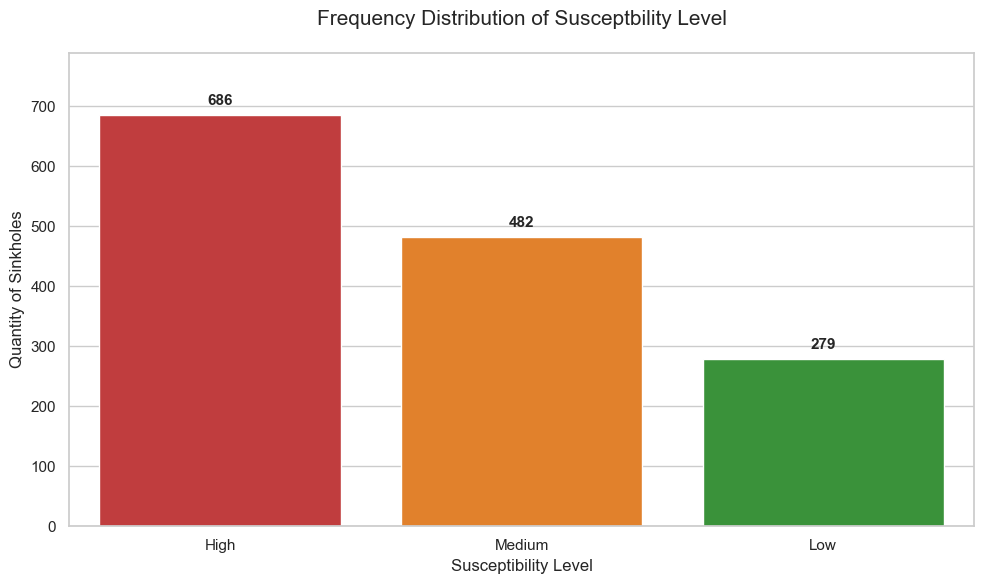

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
# Usamos hue=x para cumplir con las nuevas reglas de Seaborn y evitar advertencias
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Expert', 
    order=orden_niveles, 
    hue='Discretization_Expert', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')

# 6. Ajustar visualización
# Damos un poco más de aire en la parte superior para que quepan las etiquetas
plt.ylim(0, modelo_granular_susceptibilidad['Discretization_Expert'].value_counts().max() * 1.15)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

### 3. DISCRETIZACION CON ALGORITMO DE JENKS (NATURAL BREAKS)

--- Límites Sugeridos por Jenks ---
Low  -> Medium: 0.4145
Medium -> High:  0.5794


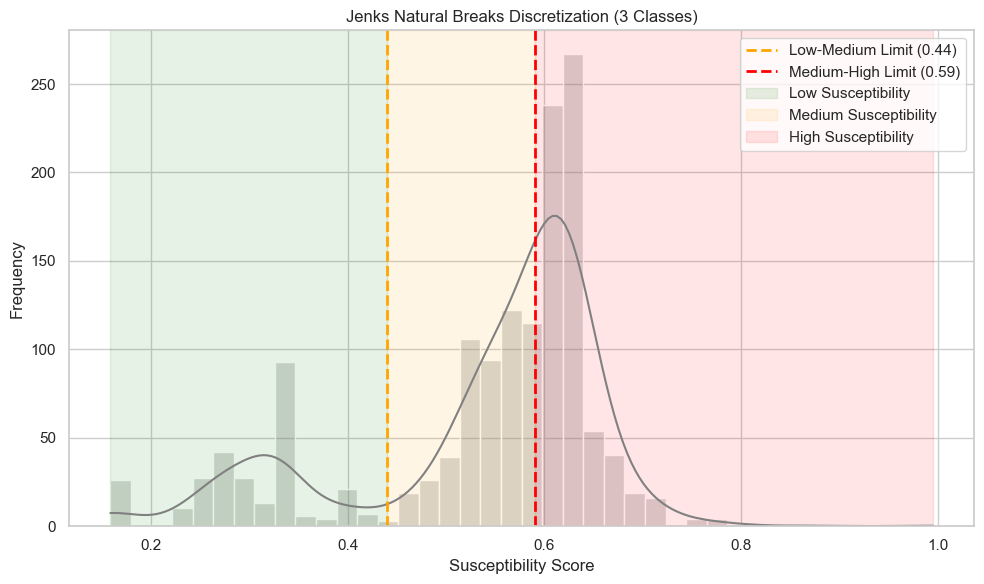


--- Conteo de Sinkholes por Clase (Optimizado) ---
Discretization_Jenks
Low       273
Medium    420
High      754
Name: count, dtype: int64


In [101]:
import jenkspy
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CALCULAR CORTES USANDO JENKS
# Buscamos 3 clases (Baja, Media, Alta)
scores = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
breaks = jenkspy.jenks_breaks(scores, n_classes=3)

# Los breaks devuelven: [min, limite1, limite2, max]
limite_jenks_1 = breaks[1]
limite_jenks_2 = breaks[2]

print(f"--- Límites Sugeridos por Jenks ---")
print(f"Low  -> Medium: {limite_jenks_1:.4f}")
print(f"Medium -> High:  {limite_jenks_2:.4f}")

# 2. APLICAR CLASIFICACIÓN
def clasificar_jenks(val):
    if val <= limite_jenks_1: return 'Low'
    if val <= limite_jenks_2: return 'Medium'
    return 'High'

modelo_granular_susceptibilidad['Discretization_Jenks'] = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].apply(clasificar_jenks)

# 5. VISUALIZACIÓN DE LA DISTRIBUCIÓN CON LOS CORTES
plt.figure(figsize=(10, 6))

# Histograma de fondo
sns.histplot(modelo_granular_susceptibilidad['Susceptibility_Score_Expert'], bins=40, kde=True, color='gray', alpha=0.3)

# Dibujar las líneas de corte calculadas por el algoritmo
plt.axvline(limite_bajo_medio, color='orange', linestyle='--', linewidth=2, label=f'Low-Medium Limit ({limite_bajo_medio:.2f})')
plt.axvline(limite_medio_alto, color='red', linestyle='--', linewidth=2, label=f'Medium-High Limit ({limite_medio_alto:.2f})')

# Colorear las áreas para visualización de riesgo
plt.axvspan(min_score, limite_bajo_medio, alpha=0.1, color='green', label='Low Susceptibility')
plt.axvspan(limite_bajo_medio, limite_medio_alto, alpha=0.1, color='orange', label='Medium Susceptibility')
plt.axvspan(limite_medio_alto, max_score, alpha=0.1, color='red', label='High Susceptibility')

plt.title('Jenks Natural Breaks Discretization (3 Classes)')
plt.xlabel('Susceptibility Score')
plt.ylabel('Frequency')
plt.legend()
plt.tight_layout()
plt.show()

# 6. VERIFICAR CUÁNTOS CAEN EN CADA GRUPO
# Ordenamos las categorías para que el conteo sea lógico
conteo = modelo_granular_susceptibilidad['Discretization_Jenks'].value_counts().reindex(['Low', 'Medium', 'High'])
print("\n--- Conteo de Sinkholes por Clase (Optimizado) ---")
print(conteo)

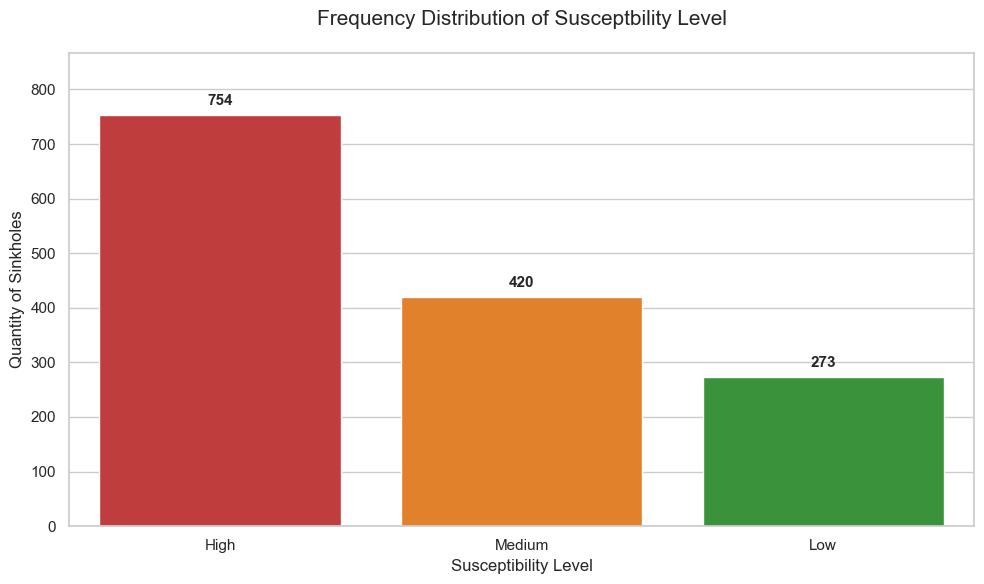

In [102]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Configuración de parámetros
# Asegúrate de que estos nombres coincidan con los que creamos en el paso anterior
orden_niveles = ['High', 'Medium', 'Low']
colores_niveles = {'Low': '#2ca02c', 'Medium': '#ff7f0e', 'High': '#d62728'}

# 2. Crear la figura
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# 3. Generar el gráfico de barras
# Usamos hue=x para cumplir con las nuevas reglas de Seaborn y evitar advertencias
ax = sns.countplot(
    data=modelo_granular_susceptibilidad, 
    x='Discretization_Jenks', 
    order=orden_niveles, 
    hue='Discretization_Jenks', 
    palette=colores_niveles,
    legend=False
)

# 4. Personalizar títulos y etiquetas (sin usar formatos complejos)
plt.title('Frequency Distribution of Susceptbility Level', fontsize=15, pad=20)
plt.xlabel('Susceptibility Level', fontsize=12)
plt.ylabel('Quantity of Sinkholes', fontsize=12)

# 5. Añadir las etiquetas de conteo sobre cada barra
for p in ax.patches:
    altura = p.get_height()
    if altura > 0:
        ax.annotate(f'{int(altura)}', 
                    (p.get_x() + p.get_width() / 2., altura), 
                    ha='center', va='center', 
                    xytext=(0, 10), 
                    textcoords='offset points', 
                    fontsize=11, fontweight='bold')

# 6. Ajustar visualización
# Damos un poco más de aire en la parte superior para que quepan las etiquetas
plt.ylim(0, modelo_granular_susceptibilidad['Discretization_Jenks'].value_counts().max() * 1.15)
plt.tight_layout()

# Mostrar el gráfico
plt.show()

# **VALIDACION DE MODELO**

In [103]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1447 non-null   float64 
 1   y_laea                               1447 non-null   float64 
 2   overburden_resistance_numeric        1447 non-null   int64   
 3   depth_drift_clean                    1447 non-null   float64 
 4   working_thickness_numeric            1447 non-null   float64 
 5   id_bd_sinkhole                       1447 non-null   object  
 6   distancia_promedio_al_vecino_m       1447 non-null   float64 
 7   depth_drift_norm                     1447 non-null   float64 
 8   working_thickness_norm               1447 non-null   float64 
 9   overburden_resistance_norm           1447 non-null   float64 
 10  overburden_resistance_norm_expert    1447 non-null   float64 
 11  range_depth           

## 1. ESTABILIDAD DEL MODELO

Ejecutando 100 simulaciones con Test Size=0.3...

--- STATISTICAL DESCRIPTION OF THRESHOLDS ---
        L1_Low_Medium  L2_Medium_High
mean         0.413654        0.579474
std          0.004837        0.001207
median       0.414453        0.579429
min          0.397228        0.575749
max          0.419110        0.582048


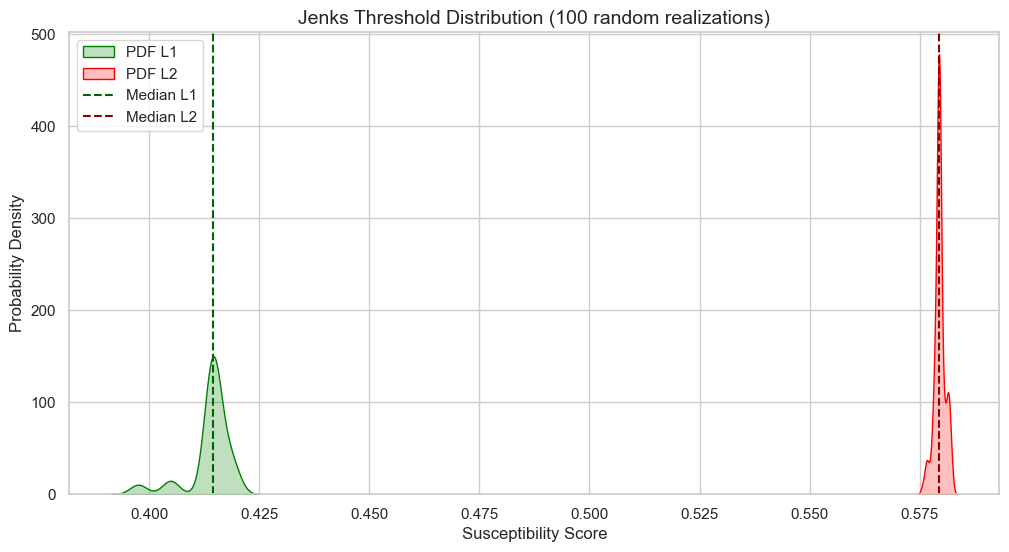

In [104]:
import pandas as pd
import jenkspy
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

# 1. PARÁMETROS DE LA SIMULACIÓN
n_iteraciones = 100
porcentaje_test = 0.30  # Fijo al 30% para estabilidad
lista_l1 = []
lista_l2 = []

print(f"Ejecutando {n_iteraciones} simulaciones con Test Size={porcentaje_test}...")

for i in range(n_iteraciones):
    # Dividimos los datos usando una semilla (random_state) diferente en cada iteración
    train_sub, _ = train_test_split(
        modelo_granular_susceptibilidad, 
        test_size=porcentaje_test, 
        random_state=i 
    )
    
    # Extraemos los scores del set de entrenamiento
    scores_train = train_sub['Susceptibility_Score_Expert'].dropna().values
    
    # Calculamos las rupturas naturales de Jenks para 3 clases (Low, Medium, High)
    breaks = jenkspy.jenks_breaks(scores_train, n_classes=3)
    
    # Guardamos L1 (Low-Medium) y L2 (Medium-High)
    lista_l1.append(breaks[1])
    lista_l2.append(breaks[2])

# 2. CONSOLIDACIÓN DE RESULTADOS
df_estabilidad = pd.DataFrame({
    'L1_Low_Medium': lista_l1,
    'L2_Medium_High': lista_l2
})

# Calculamos estadísticas descriptivas
stats = df_estabilidad.describe().loc[['mean', 'std', '50%', 'min', 'max']]
stats.rename(index={'50%': 'median'}, inplace=True)

print("\n--- STATISTICAL DESCRIPTION OF THRESHOLDS ---")
print(stats)

# 3. VISUALIZACIÓN DE LA SENSIBILIDAD
plt.figure(figsize=(12, 6))
sns.kdeplot(df_estabilidad['L1_Low_Medium'], fill=True, color='green', label='PDF L1')
sns.kdeplot(df_estabilidad['L2_Medium_High'], fill=True, color='red', label='PDF L2')

plt.axvline(stats.loc['median', 'L1_Low_Medium'], color='darkgreen', linestyle='--', label='Median L1')
plt.axvline(stats.loc['median', 'L2_Medium_High'], color='darkred', linestyle='--', label='Median L2')

plt.title('Jenks Threshold Distribution (100 random realizations)', fontsize=14)
plt.xlabel('Susceptibility Score')
plt.ylabel('Probability Density')
plt.legend()
plt.show()

## 2. EMPAQUETAMIENTO DEL MODELO (.pkl)

In [105]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1447 non-null   float64 
 1   y_laea                               1447 non-null   float64 
 2   overburden_resistance_numeric        1447 non-null   int64   
 3   depth_drift_clean                    1447 non-null   float64 
 4   working_thickness_numeric            1447 non-null   float64 
 5   id_bd_sinkhole                       1447 non-null   object  
 6   distancia_promedio_al_vecino_m       1447 non-null   float64 
 7   depth_drift_norm                     1447 non-null   float64 
 8   working_thickness_norm               1447 non-null   float64 
 9   overburden_resistance_norm           1447 non-null   float64 
 10  overburden_resistance_norm_expert    1447 non-null   float64 
 11  range_depth           

In [106]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1421 non-null   object 
 1   geology_of_the_overburden      1421 non-null   object 
 2   material_overbuden_resistance  437 non-null    object 
 3   resistance_numeric             433 non-null    float64
 4   text_for_ml                    1421 non-null   object 
 5   target_res                     433 non-null    float64
 6   cluster                        1421 non-null   int32  
 7   overburden_resistance_numeric  1421 non-null   float64
 8   resistencia_imputada           1421 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 94.5+ KB


### Exportacion de resultados para empaquetamiento

In [107]:
import os

# 1. Definimos la ruta relativa (subir un nivel, entrar a data/processed)
ruta_procesados = '../data/processed/'

# 2. Asegurar que la carpeta exista
os.makedirs(ruta_procesados, exist_ok=True)

# 3. Exportar ambos DataFrames a formato Parquet
df_ml.to_parquet(ruta_procesados + 'df_ml.parquet', index=False)
modelo_granular_susceptibilidad.to_parquet(ruta_procesados + 'modelo_granular.parquet', index=False)

print(f"✅ Archivos exportados exitosamente en: {ruta_procesados}")

✅ Archivos exportados exitosamente en: ../data/processed/


# PRUEBAS DE EMPAQUETAMIENTO

Esto es para probar que el flujo funciona

### VERSION 1. MODELO NO SUPERVISADO PARA RESISTENCIA CON K-MEANS

In [108]:
import numpy as np
import jenkspy
import pickle

print("Empaquetando Resultados Susceptibility Model V 1.0 (Incluye NLP)...")

# 1. PARÁMETROS DE NORMALIZACIÓN (Profundidad y Espesor)
# 1.1. Para profundidad (Log-Inverse Min-Max)
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'].dropna())
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()

# 1.2. Para espesor (Normalizacion linear Min-Max)
thick_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thick_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# 2. UMBRALES MAESTROS JENKS (usando TODOS los datos de la base de datos o catalogo)
scores_finales = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
master_breaks = jenkspy.jenks_breaks(scores_finales, n_classes=3)

# 3. DICCIONARIO MAESTRO (AQUI SE INCLUYEN TODOS LOS RESULTADOS DEL ANALISIS DE SUSCEPTIBILIDAD)
pipeline_susceptibilidad_completo = {
    'version': '1.0_NLP_EndToEnd',
    
    # --- MÓDULO GEOLÓGICO (NLP + Clustering) ---
    # AQUI COLOCAMOS LAS VARIABLES QUE TIENEN TODA LA INFORMACION DEL ANALISIS:
    'nlp_vectorizer': vectorizer,
    'nlp_kmeans': kmeans,
    # Mapa que traduce el clúster (0, 1, 2, 3, 4) a resistencia (1, 2, 3)
    'mapa_cluster_resistencia': reglas_imputacion, 
    
    # --- MÓDULO DE SUSCEPTIBILIDAD ---
    # Pesos holisticos (Conocimiento Experto)
    'pesos': {'alpha': 0.4, # Profundidad
              'beta': 0.3, # Espesor de capa
              'gamma': 0.3 # Resistencia del overburden material
              },

    # Limites para la variable resistencia de material
    'mapeo_res_a_peso': {1: 0.7,
                         2: 0.35,
                         3: 0.10},
    
    # Parametros para profundidad y espesor de capa
    'parametros_normalizacion': {
        'depth_log_min': log_min_depth,
        'depth_log_max': log_max_depth,
        'thick_min': thick_min, 
        'thick_max': thick_max
    },
    
    # Umbrales definidos por Jenks Break
    'umbrales_jenks': {'L1': master_breaks[1], 'L2': master_breaks[2]}
}

# 4. EXPORTACIÓN EN DISCO (empaquetado)
nombre_archivo = 'pipeline_susceptibilidad_NLP_kmeans.pkl'
with open(nombre_archivo, 'wb') as f:
    pickle.dump(pipeline_susceptibilidad_completo, f)

print(f"✅ Pipeline exportado exitosamente en: {nombre_archivo}")

Empaquetando Resultados Susceptibility Model V 1.0 (Incluye NLP)...
✅ Pipeline exportado exitosamente en: pipeline_susceptibilidad_NLP_kmeans.pkl


#### OPCION 2. MODELO VERSION SUPERVISADA PARA RESISTENCIA CON RANDOM FOREST

In [109]:
modelo_granular_susceptibilidad.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1447 entries, 0 to 1813
Data columns (total 21 columns):
 #   Column                               Non-Null Count  Dtype   
---  ------                               --------------  -----   
 0   x_laea                               1447 non-null   float64 
 1   y_laea                               1447 non-null   float64 
 2   overburden_resistance_numeric        1447 non-null   int64   
 3   depth_drift_clean                    1447 non-null   float64 
 4   working_thickness_numeric            1447 non-null   float64 
 5   id_bd_sinkhole                       1447 non-null   object  
 6   distancia_promedio_al_vecino_m       1447 non-null   float64 
 7   depth_drift_norm                     1447 non-null   float64 
 8   working_thickness_norm               1447 non-null   float64 
 9   overburden_resistance_norm           1447 non-null   float64 
 10  overburden_resistance_norm_expert    1447 non-null   float64 
 11  range_depth           

In [110]:
df_ml.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1421 entries, 0 to 1420
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   id_bd_sinkhole                 1421 non-null   object 
 1   geology_of_the_overburden      1421 non-null   object 
 2   material_overbuden_resistance  437 non-null    object 
 3   resistance_numeric             433 non-null    float64
 4   text_for_ml                    1421 non-null   object 
 5   target_res                     433 non-null    float64
 6   cluster                        1421 non-null   int32  
 7   overburden_resistance_numeric  1421 non-null   float64
 8   resistencia_imputada           1421 non-null   object 
dtypes: float64(3), int32(1), object(5)
memory usage: 94.5+ KB


In [111]:
import numpy as np
import jenkspy
import pickle
from sklearn.ensemble import RandomForestClassifier

print("Empaquetando Modelo Supervisado (V 2.0 - Random Forest)...")

# 1. PARÁMETROS DE NORMALIZACIÓN (Profundidad y Espesor)
# Usando la variable actualizada 'depth_drift_clean'
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'].dropna())
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()

# Para espesor (Normalizacion linear Min-Max)
thick_min = modelo_granular_susceptibilidad['working_thickness_numeric'].min()
thick_max = modelo_granular_susceptibilidad['working_thickness_numeric'].max()

# Umbrales Jenks
scores_finales = modelo_granular_susceptibilidad['Susceptibility_Score_Expert'].dropna().values
master_breaks = jenkspy.jenks_breaks(scores_finales, n_classes=3)

# ==============================================================================
# 2. ENTRENAMIENTO DEL CLASIFICADOR SUPERVISADO
# ==============================================================================
# Usamos 'X_text' que ya está vectorizada y tiene el mismo número de filas que 'df_ml'
# Como variable objetivo, usamos la columna FINAL post-imputación K-Means
y_train_res = df_ml['overburden_resistance_numeric'].astype(int)

# Entrenamos con class_weight='balanced' para obligar al modelo a detectar la Resistencia 3
rf_classifier = RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)
rf_classifier.fit(X_text, y_train_res)

# ==============================================================================
# 3. DICCIONARIO MAESTRO V2
# ==============================================================================
pipeline_supervisado = {
    'version': '2.0_NLP_Supervised',
    
    # --- MÓDULO GEOLÓGICO SUPERVISADO ---
    'nlp_vectorizer': vectorizer,
    'nlp_classifier': rf_classifier,
    
    # --- MÓDULO DE SUSCEPTIBILIDAD ---
    # Pesos holisticos (Conocimiento Experto)
    'pesos': {'alpha': 0.4,   # Profundidad
              'beta': 0.3,    # Espesor de capa
              'gamma': 0.3},  # Resistencia del material
              
    # Limites para la variable resistencia de material
    'mapeo_res_a_peso': {1: 0.70, 
                         2: 0.35, 
                         3: 0.10},
    
    # Parametros para profundidad y espesor
    'parametros_normalizacion': {
        'depth_log_min': log_min_depth,
        'depth_log_max': log_max_depth,
        'thick_min': thick_min, 
        'thick_max': thick_max
    },
    
    # Umbrales definidos por Jenks Break
    'umbrales_jenks': {'L1': master_breaks[1], 'L2': master_breaks[2]}
}

# ==============================================================================
# 4. EXPORTACIÓN EN DISCO
# ==============================================================================
nombre_archivo_v2 = 'pipeline_susceptibilidad_NLP_randomforest.pkl'

with open(nombre_archivo_v2, 'wb') as f:
    pickle.dump(pipeline_supervisado, f)

print(f"✅ Pipeline V2 exportado exitosamente en: {nombre_archivo_v2}")

Empaquetando Modelo Supervisado (V 2.0 - Random Forest)...
✅ Pipeline V2 exportado exitosamente en: pipeline_susceptibilidad_NLP_randomforest.pkl


In [112]:
log_depth = np.log1p(modelo_granular_susceptibilidad['depth_drift_clean'])
log_min_depth, log_max_depth = log_depth.min(), log_depth.max()
log_max_depth


np.float64(6.698268054115413)

# MODELO DE MAGNITUD

In [113]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   name                                          1414 non-null   object 
 2   id_sinkhole                                   1395 non-null   object 
 3   coordinate
x                                  1814 non-null   float64
 4   coordinate
y                                  1814 non-null   float64
 5   x_wgs84                                       1814 non-null   float64
 6   y_wgs84                                       1814 non-null   float64
 7   name_of_the_mine                              1814 non-null   object 
 8   country                                       1814 non-null   object 
 9   municipality                                  1812 non-null   o

In [114]:
df_risk[["id_bd_sinkhole", "length_diameter_m", "depth_of_the_sinkhole_m", "origin_of_collapse", "number_of_sinkholes"]]

,id_bd_sinkhole,length_diameter_m,depth_of_the_sinkhole_m,origin_of_collapse,number_of_sinkholes
0,FR-SIN-01,8,Unknown,Unknow,1
1,FR-SIN-02,2.5,1,Unknow,1
2,FR-SIN-03,Unknown,Unknown,Unknow,1
3,FR-SIN-04,15,2.5,Unknow,1
4,FR-SIN-05,0.5,0.5,Unknow,1
...,...,...,...,...,...
1809,POL-SIN- 901,12,4,Faillure of the roof room or roof gallery,3
1810,POL-SIN- 902,2,2,Faillure of the roof room or roof gallery,3
1811,POL-SIN- 903,12,7,Faillure of the roof room or roof gallery,3
1812,POL-SIN- 904,1.5,15,Collapse of the shaft filling material,1


In [115]:
from pyproj import Transformer

# Creamos el transformador de WGS84 (4326) a ETRS89-LAEA (3035)
# Nota: pyproj usa (lat, lon) o (y, x) según el estándar
transformer = Transformer.from_crs("epsg:4326", "epsg:3035", always_xy=True)

# 2. Convertimos las coordenadas a metros europeos
# x_wgs84 es longitud, y_wgs84 es latitud
df_risk['x_laea'], df_risk['y_laea'] = transformer.transform(
    df_risk['x_wgs84'].values, 
    df_risk['y_wgs84'].values
)

# Limpieza de variables

Se realiza la limpieza de las 4 variables:

- origin_of_colapse: Que todas las descripciones esten en minuscula + quitar palabras que representan valores nulos por NaN
- Limpieza numerica: dejar todos los valores en su unidad respectiva (todo en metros) y quitar simbolos >, -, etc

In [116]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

print("Iniciando EDA para el Modelo de Magnitud...\n")

# 1. FUNCIONES DE LIMPIEZA (Para extraer números de textos como "1.5-2.0")
def limpiar_numerica(val):
    val_str = str(val).lower().strip()
    
    # 1. Filtro de nulos/texto vacío
    if val_str in ['unknown', 'unknow', 'non disponible', 'several', 'sevral', 'nan', 'none', '']:
        return np.nan
    
    # 2. Estandarizar decimales y limpiar símbolos matemáticos
    val_str = val_str.replace(',', '.')
    val_str = val_str.replace('>', '').replace('<', '').replace('~', '')
    
    # 3. Identificar unidades para la conversión (Todo se pasa a metros)
    multiplier = 1.0
    if 'cm' in val_str:
        multiplier = 0.01
    elif 'mm' in val_str:
        multiplier = 0.001
    
    # 4. Estandarizar separadores de rango (convertimos "à" y "to" en un guion "-")
    val_str = re.sub(r'\s*à\s*', '-', val_str)
    val_str = re.sub(r'\s*to\s*', '-', val_str)
    
    # 5. Extraer Rangos (ej. 2 - 5)
    rangos = re.findall(r'(\d+\.?\d*)\s*-\s*(\d+\.?\d*)', val_str)
    if rangos:
        promedio = (float(rangos[0][0]) + float(rangos[0][1])) / 2.0
        return promedio * multiplier
        
    # 6. Extraer Número Único (ej. 10)
    numeros = re.findall(r'(\d+\.?\d*)', val_str)
    if numeros:
        return float(numeros[0]) * multiplier
        
    return np.nan

def limpiar_categorica(val):
    val_str = str(val).lower().strip()
    # Lista de palabras que equivalen a un dato faltante
    if val_str in ['unknown', 'unknow', 'Unknow', 'Unknown', 'non disponible', 'several', 'sevral', 'nan', '', 'none']:
        return np.nan
    return val_str

# 2. LIMPIEZA DE VARIABLES DE MAGNITUD
# Asumiendo que tu dataframe original filtrado se llama 'df_risk'
df_mag = df_risk[["id_bd_sinkhole", "x_laea", "y_laea", "length_diameter_m", "depth_of_the_sinkhole_m", "origin_of_collapse", "number_of_sinkholes"]].copy()

df_mag['number_sinkholes_clean'] = df_mag['number_of_sinkholes'].apply(limpiar_numerica)
df_mag['diameter_sinkhole_clean'] = df_mag['length_diameter_m'].apply(limpiar_numerica)
df_mag['depth_sinkhole_clean'] = df_mag['depth_of_the_sinkhole_m'].apply(limpiar_numerica)
df_mag['origin_collapse_clean'] = df_mag['origin_of_collapse'].apply(limpiar_categorica)

# 3. REPORTE DE DATOS ÚTILES (Completitud)
total_registros = len(df_mag)
print(f"Total de registros históricos: {total_registros}")
print(f"Diámetros reportados: {df_mag['diameter_sinkhole_clean'].notna().sum()} ({(df_mag['diameter_sinkhole_clean'].notna().sum()/total_registros)*100:.1f}%)")
print(f"Profundidades de cráter: {df_mag['depth_sinkhole_clean'].notna().sum()} ({(df_mag['depth_sinkhole_clean'].notna().sum()/total_registros)*100:.1f}%)")

Iniciando EDA para el Modelo de Magnitud...

Total de registros históricos: 1814
Diámetros reportados: 1210 (66.7%)
Profundidades de cráter: 1493 (82.3%)


In [117]:
df_mag[df_mag["id_bd_sinkhole"] == "FR-SIN-124"]

,id_bd_sinkhole,x_laea,y_laea,length_diameter_m,depth_of_the_sinkhole_m,origin_of_collapse,number_of_sinkholes,number_sinkholes_clean,diameter_sinkhole_clean,depth_sinkhole_clean,origin_collapse_clean
123,FR-SIN-124,3.745295e+06,2.576107e+06,1,>2,Faillure of the roof gallery,1,1.0,1.0,2.0,faillure of the roof gallery


# Depth of the Sinkhole

In [118]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: PROFUNDIDAD DEL SINKHOLE ---")

# 1. Estadísticas Descriptivas Básicas
stats_depth = df_mag['depth_sinkhole_clean'].describe()
nulos_depth = df_mag['depth_sinkhole_clean'].isna().sum()
total_depth = len(df_mag)
porcentaje_util = (stats_depth['count'] / total_depth) * 100

print(f"Total de registros en BD: {total_depth}")
print(f"Datos válidos: {int(stats_depth['count'])} ({porcentaje_util:.1f}%)")
print(f"Datos nulos: {nulos_depth}\n")
print("Estadísticas:")
print(stats_depth.round(2))

--- EDA: PROFUNDIDAD DEL SINKHOLE ---
Total de registros en BD: 1814
Datos válidos: 1493 (82.3%)
Datos nulos: 321

Estadísticas:
count    1493.00
mean        2.03
std         2.72
min         0.00
25%         0.50
50%         1.50
75%         2.50
max        40.00
Name: depth_sinkhole_clean, dtype: float64


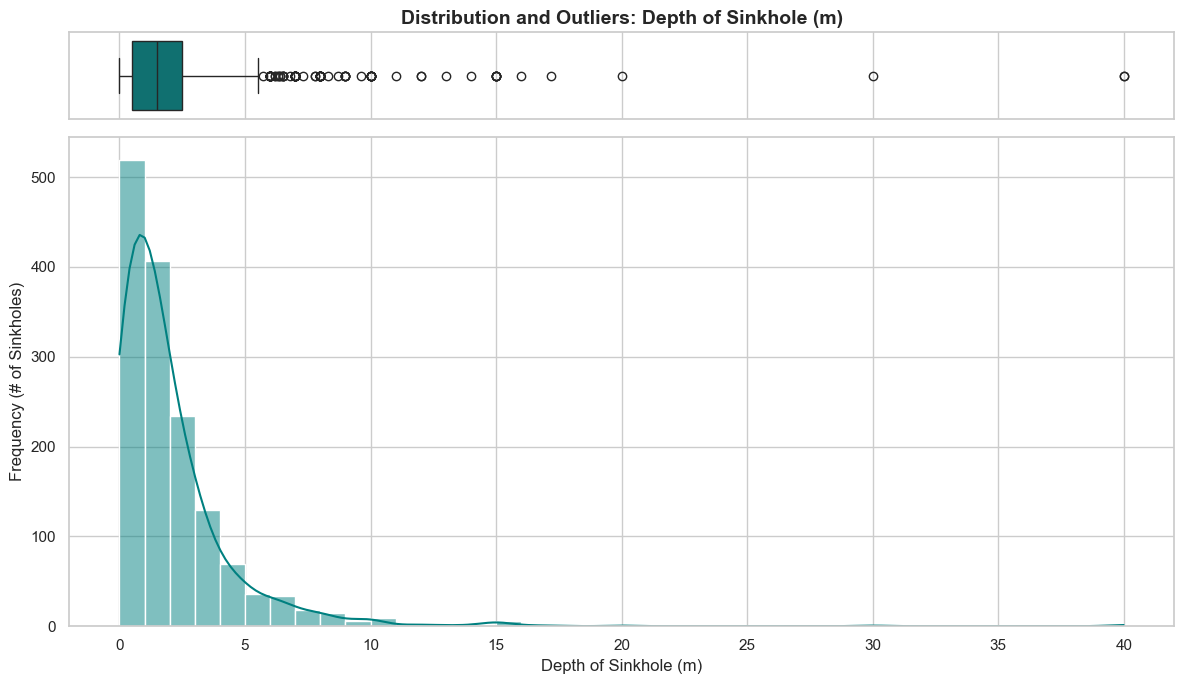

In [119]:
# 2. Configuración del Gráfico (Boxplot arriba, Histograma abajo)
sns.set_theme(style="whitegrid")
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# A. Boxplot (Para detectar Outliers)
sns.boxplot(x=df_mag['depth_sinkhole_clean'], ax=ax_box, color='teal')
ax_box.set(xlabel='')
ax_box.set_title('Distribution and Outliers: Depth of Sinkhole (m)', fontsize=14, fontweight='bold')

# B. Histograma + Curva KDE (Para ver la forma de la distribución)
sns.histplot(df_mag['depth_sinkhole_clean'].dropna(), bins=40, kde=True, color='teal', ax=ax_hist)
ax_hist.set_xlabel('Depth of Sinkhole (m)', fontsize=12)
ax_hist.set_ylabel('Frequency (# of Sinkholes)', fontsize=12)

plt.tight_layout()
plt.show()

# Diameter of Sinkhole

In [120]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: DIÁMETRO DEL SINKHOLE ---")

# 1. Estadísticas Descriptivas Básicas
stats_diam = df_mag['diameter_sinkhole_clean'].describe()
nulos_diam = df_mag['diameter_sinkhole_clean'].isna().sum()
total_diam = len(df_mag)
porcentaje_util_diam = (stats_diam['count'] / total_diam) * 100

print(f"Total de registros en BD: {total_diam}")
print(f"Datos válidos: {int(stats_diam['count'])} ({porcentaje_util_diam:.1f}%)")
print(f"Datos nulos: {nulos_diam}\n")
print("Estadísticas:")
print(stats_diam.round(2))

--- EDA: DIÁMETRO DEL SINKHOLE ---
Total de registros en BD: 1814
Datos válidos: 1210 (66.7%)
Datos nulos: 604

Estadísticas:
count    1210.00
mean        6.41
std         9.74
min         0.10
25%         2.00
50%         4.00
75%         8.00
max       180.00
Name: diameter_sinkhole_clean, dtype: float64


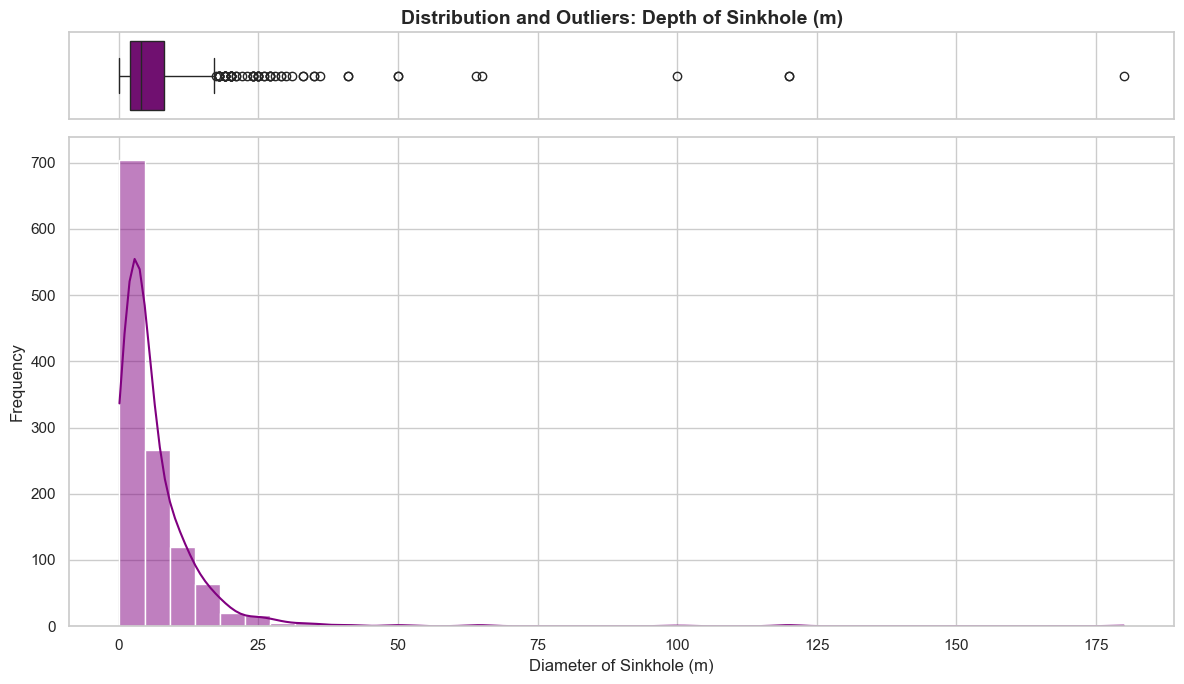

In [121]:
# 2. Configuración del Gráfico (Boxplot arriba, Histograma abajo)
sns.set_theme(style="whitegrid")
fig, (ax_box, ax_hist) = plt.subplots(2, sharex=True, 
                                      gridspec_kw={"height_ratios": (.15, .85)}, 
                                      figsize=(12, 7))

# A. Boxplot (Para detectar Outliers)
sns.boxplot(x=df_mag['diameter_sinkhole_clean'], ax=ax_box, color='purple')
ax_box.set(xlabel='')
ax_box.set_title('Distribution and Outliers: Depth of Sinkhole (m)', fontsize=14, fontweight='bold')

# B. Histograma + Curva KDE (Para ver la forma de la distribución)
sns.histplot(df_mag['diameter_sinkhole_clean'].dropna(), bins=40, kde=True, color='purple', ax=ax_hist)
ax_hist.set_xlabel('Diameter of Sinkhole (m)', fontsize=12)
ax_hist.set_ylabel('Frequency', fontsize=12)

plt.tight_layout()
plt.show()



# Origin of Collapse

In [122]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("--- EDA: ORIGIN OF COLLAPSE ---")

# 1. Frecuencias y Completitud
total_origin = len(df_mag)
nulos_origin = df_mag['origin_collapse_clean'].isna().sum()
validos_origin = total_origin - nulos_origin
porcentaje_util_origin = (validos_origin / total_origin) * 100

print(f"Total de registros en BD: {total_origin}")
print(f"Datos válidos: {validos_origin} ({porcentaje_util_origin:.1f}%)")
print(f"Datos nulos: {nulos_origin}\n")

# 2. Tabla de Frecuencias Absolutas y Relativas
frecuencias = df_mag['origin_collapse_clean'].value_counts()
porcentajes = df_mag['origin_collapse_clean'].value_counts(normalize=True) * 100

df_frecuencias = pd.DataFrame({
    'Cantidad': frecuencias,
    'Porcentaje (%)': porcentajes.round(1)
})

print("--- Distribución de los Tipos de Origen ---")
print(df_frecuencias.head(10)) # Mostramos los 10 más comunes

--- EDA: ORIGIN OF COLLAPSE ---
Total de registros en BD: 1814
Datos válidos: 1293 (71.3%)
Datos nulos: 521

--- Distribución de los Tipos de Origen ---
                                           Cantidad  Porcentaje (%)
origin_collapse_clean                                              
faillure of the roof room or roof gallery       817            63.2
faillure of the roof gallery                    292            22.6
collapse of the shaft filling material          115             8.9
faillure of the roof room                        43             3.3
failure of the shaft head                        15             1.2
pillar failure                                    6             0.5
karst                                             3             0.2
collapse of the surface                           1             0.1
suffosion                                         1             0.1


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_20288\3744991644.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


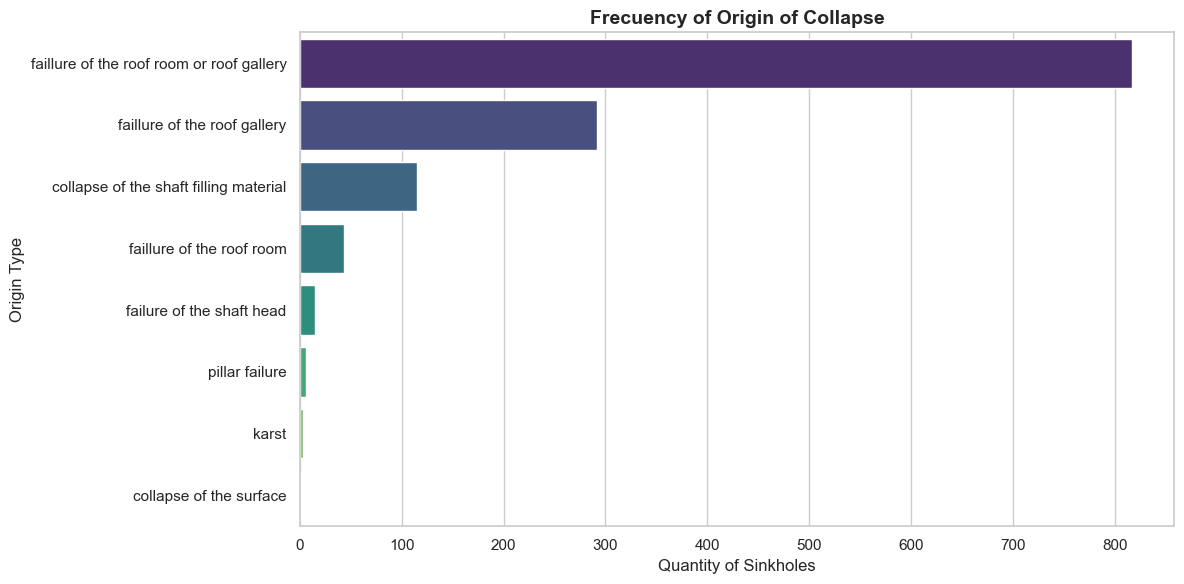

In [123]:
# 3. Visualización (Gráfico de Barras Horizontal)
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos los top 8 orígenes para que el gráfico no se sature de categorías raras
top_n = frecuencias.head(8).index
df_plot_origin = df_mag[df_mag['origin_collapse_clean'].isin(top_n)]

sns.countplot(
    data=df_plot_origin,
    y='origin_collapse_clean',
    order=top_n,
    palette='viridis'
)
plt.title('Frecuency of Origin of Collapse', fontsize=14, fontweight='bold')
plt.xlabel('Quantity of Sinkholes', fontsize=12)
plt.ylabel('Origin Type', fontsize=12)
plt.tight_layout()
plt.show()

In [124]:
# 4. Cruce de Variables: Origen vs. Magnitud Física
print("\n--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---")
# Calculamos la mediana del diámetro y profundidad para cada tipo de origen
impacto_origen = df_mag.groupby('origin_collapse_clean')[['diameter_sinkhole_clean', 'depth_sinkhole_clean']].median()

# Añadimos el conteo para dar contexto (no es lo mismo una mediana de 1 dato que de 100)
impacto_origen['Conteo'] = df_mag.groupby('origin_collapse_clean').size()

# Ordenamos por el diámetro de mayor a menor para ver cuáles son los más destructivos
impacto_origen = impacto_origen.sort_values(by='diameter_sinkhole_clean', ascending=False)
impacto_origen[impacto_origen['Conteo'] >= 5].head(10) # Filtramos los que tienen al menos 5 casos


--- Impacto del Origen en la Magnitud FÍSICA (Medianas) ---


,diameter_sinkhole_clean,depth_sinkhole_clean,Conteo
origin_collapse_clean,,,
faillure of the roof room or roof gallery,5.00,1.9,817
failure of the shaft head,4.50,3.0,15
faillure of the roof room,3.00,2.0,43
faillure of the roof gallery,3.00,1.5,292
collapse of the shaft filling material,3.00,1.5,115
pillar failure,1.75,2.0,6


# Number of Sinkholes

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_20288\3445552651.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


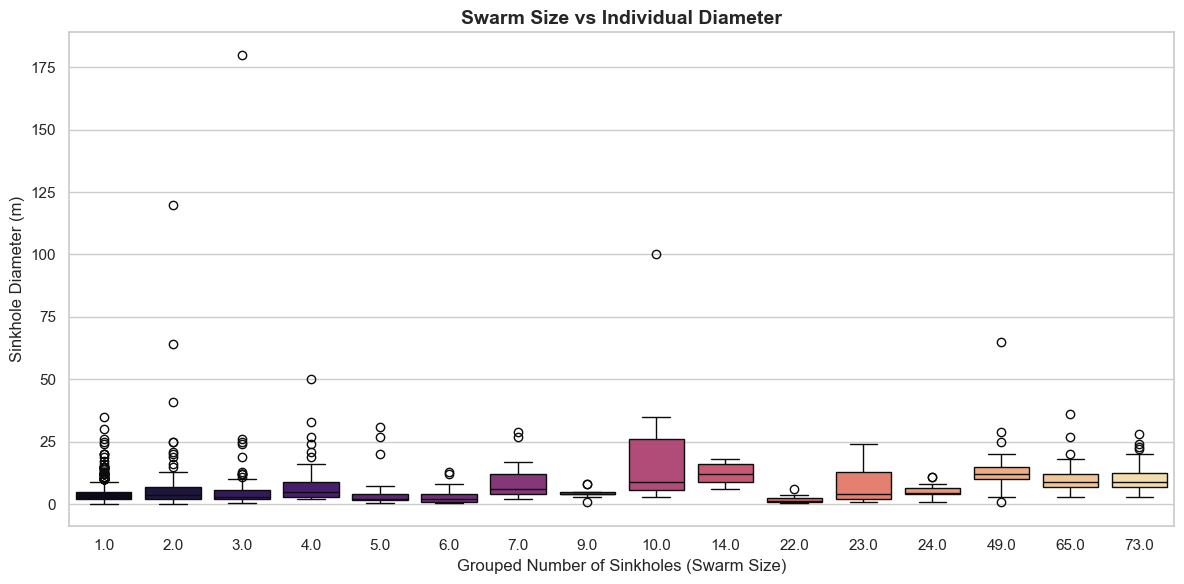


--- Relación: Enjambres y Origen del Colapso ---
                                           median       mean   max
origin_collapse_clean                                             
faillure of the roof room or roof gallery     5.0  19.360294  73.0
collapse of the shaft filling material        1.0   2.114035  23.0
faillure of the roof gallery                  1.0   1.586806  23.0
faillure of the roof room                     1.0   1.139535   5.0
pillar failure                                3.0   2.333333   3.0
collapse of the surface                       1.0   1.000000   1.0
failure of the shaft head                     1.0   1.000000   1.0
karst                                         1.0   1.000000   1.0


In [125]:
# 1. Limpieza rápida (asegurarnos de descartar nulos en esta variable)
df_swarm = df_mag.dropna(subset=['number_sinkholes_clean']).copy()

# 2. VISUALIZACIÓN: ¿El enjambre afecta el diámetro físico?
# Aquí sí usamos los datos sin agrupar, porque queremos saber el diámetro de CADA hueco individual
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos hasta enjambres de 10 para que el gráfico sea legible (puedes ajustar este filtro)
df_plot_swarm = df_swarm[df_swarm['number_sinkholes_clean'] <= 200]

sns.boxplot(
    data=df_plot_swarm, 
    x='number_sinkholes_clean', 
    y='diameter_sinkhole_clean', 
    palette='magma'
)

plt.title('Swarm Size vs Individual Diameter', fontsize=14, fontweight='bold')
plt.xlabel('Grouped Number of Sinkholes (Swarm Size)', fontsize=12)
plt.ylabel('Sinkhole Diameter (m)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. CRUCE DE VARIABLES (Enjambres vs Origen)
print("\n--- Relación: Enjambres y Origen del Colapso ---")
# ¿Los enjambres suelen ocurrir en galerías o en pozos?
relacion_origen = df_swarm.groupby('origin_collapse_clean')['number_sinkholes_clean'].agg(['median', 'mean', 'max'])
print(relacion_origen.sort_values(by='max', ascending=False).head(8))

In [126]:
df_mag.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1814 non-null   object 
 1   x_laea                   1814 non-null   float64
 2   y_laea                   1814 non-null   float64
 3   length_diameter_m        1672 non-null   object 
 4   depth_of_the_sinkhole_m  1590 non-null   object 
 5   origin_of_collapse       1792 non-null   object 
 6   number_of_sinkholes      1807 non-null   object 
 7   number_sinkholes_clean   1801 non-null   float64
 8   diameter_sinkhole_clean  1210 non-null   float64
 9   depth_sinkhole_clean     1493 non-null   float64
 10  origin_collapse_clean    1293 non-null   object 
dtypes: float64(5), object(6)
memory usage: 156.0+ KB


C:\Users\gbenavides\AppData\Local\Temp\ipykernel_20288\1892428106.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


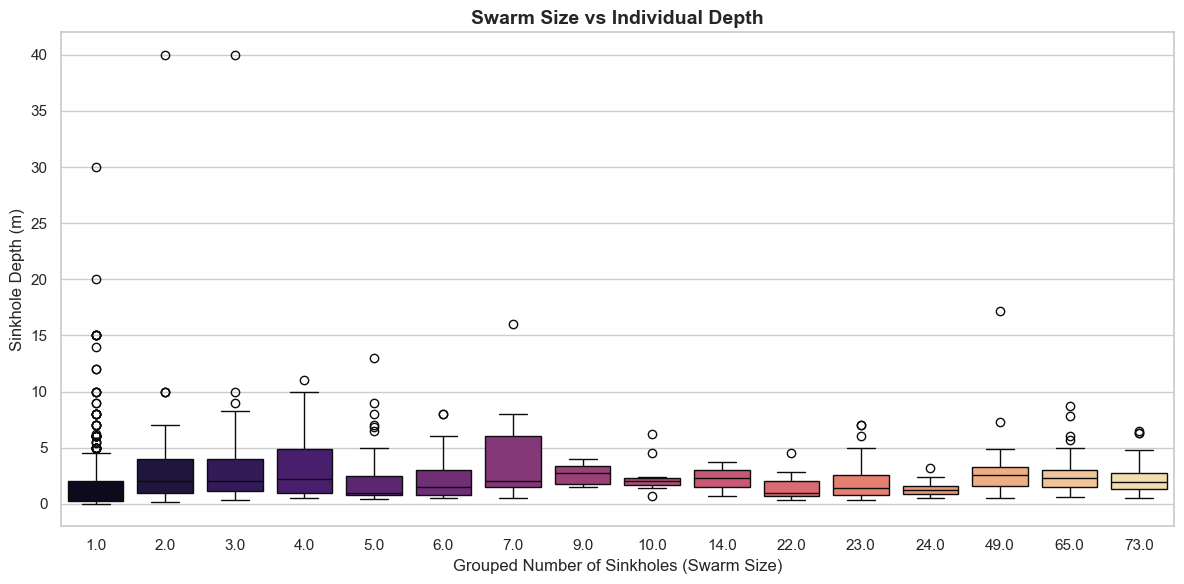


--- Relación: Enjambres y Origen del Colapso ---
                                           median       mean   max
origin_collapse_clean                                             
faillure of the roof room or roof gallery     5.0  19.360294  73.0
collapse of the shaft filling material        1.0   2.114035  23.0
faillure of the roof gallery                  1.0   1.586806  23.0
faillure of the roof room                     1.0   1.139535   5.0
pillar failure                                3.0   2.333333   3.0
collapse of the surface                       1.0   1.000000   1.0
failure of the shaft head                     1.0   1.000000   1.0
karst                                         1.0   1.000000   1.0


In [127]:
# 1. Limpieza rápida (asegurarnos de descartar nulos en esta variable)
df_swarm = df_mag.dropna(subset=['number_sinkholes_clean']).copy()

# 2. VISUALIZACIÓN: ¿El enjambre afecta el diámetro físico?
# Aquí sí usamos los datos sin agrupar, porque queremos saber el diámetro de CADA hueco individual
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Filtramos hasta enjambres de 10 para que el gráfico sea legible (puedes ajustar este filtro)
df_plot_swarm = df_swarm[df_swarm['number_sinkholes_clean'] <= 200]

sns.boxplot(
    data=df_plot_swarm, 
    x='number_sinkholes_clean', 
    y='depth_sinkhole_clean', 
    palette='magma'
)

plt.title('Swarm Size vs Individual Depth', fontsize=14, fontweight='bold')
plt.xlabel('Grouped Number of Sinkholes (Swarm Size)', fontsize=12)
plt.ylabel('Sinkhole Depth (m)', fontsize=12)
plt.tight_layout()
plt.show()

# 4. CRUCE DE VARIABLES (Enjambres vs Origen)
print("\n--- Relación: Enjambres y Origen del Colapso ---")
# ¿Los enjambres suelen ocurrir en galerías o en pozos?
relacion_origen = df_swarm.groupby('origin_collapse_clean')['number_sinkholes_clean'].agg(['median', 'mean', 'max'])
print(relacion_origen.sort_values(by='max', ascending=False).head(8))

In [128]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1814 entries, 0 to 1813
Data columns (total 31 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id_bd_sinkhole                                1814 non-null   object 
 1   name                                          1414 non-null   object 
 2   id_sinkhole                                   1395 non-null   object 
 3   coordinate
x                                  1814 non-null   float64
 4   coordinate
y                                  1814 non-null   float64
 5   x_wgs84                                       1814 non-null   float64
 6   y_wgs84                                       1814 non-null   float64
 7   name_of_the_mine                              1814 non-null   object 
 8   country                                       1814 non-null   object 
 9   municipality                                  1812 non-null   o

In [129]:
print("--- AUDITORÍA ESPACIAL DE ENJAMBRES (VERSIÓN ESTRICTA) ---")

# 1. Preparar DataFrame (aseguramos que no haya nulos en las variables clave)
df_spatial = df_mag.dropna(subset=['x_laea', 'y_laea', 'number_sinkholes_clean']).copy()
df_spatial.info()


--- AUDITORÍA ESPACIAL DE ENJAMBRES (VERSIÓN ESTRICTA) ---
<class 'pandas.core.frame.DataFrame'>
Index: 1801 entries, 0 to 1813
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1801 non-null   object 
 1   x_laea                   1801 non-null   float64
 2   y_laea                   1801 non-null   float64
 3   length_diameter_m        1662 non-null   object 
 4   depth_of_the_sinkhole_m  1580 non-null   object 
 5   origin_of_collapse       1779 non-null   object 
 6   number_of_sinkholes      1801 non-null   object 
 7   number_sinkholes_clean   1801 non-null   float64
 8   diameter_sinkhole_clean  1201 non-null   float64
 9   depth_sinkhole_clean     1484 non-null   float64
 10  origin_collapse_clean    1287 non-null   object 
dtypes: float64(5), object(6)
memory usage: 168.8+ KB


--- EJECUTANDO ALGORITMO KNN PARA AUDITORÍA DE ENJAMBRES ---

--- TOP 15: ENJAMBRES CON MAYOR EXTENSIÓN FÍSICA ---
 ID_Evento_Real  number_sinkholes_clean  Distancia_Max_Cluster_km
           1193                       5                  1349.259
           1183                       4                  1340.816
           1214                      10                  1312.385
           1153                       3                  1293.178
           1087                       2                  1253.999
           1220                      49                   259.386
           1086                       2                    61.544
           1191                       4                    19.474
           1199                       5                    19.179
           1165                       3                    19.145
           1182                       3                     8.747
           1190                       4                     6.220
           1198            

C:\Users\gbenavides\AppData\Local\Temp\ipykernel_20288\1341062908.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=event_counts, x='Tamanio_Enjambre', y='Cantidad_Eventos', palette='magma')


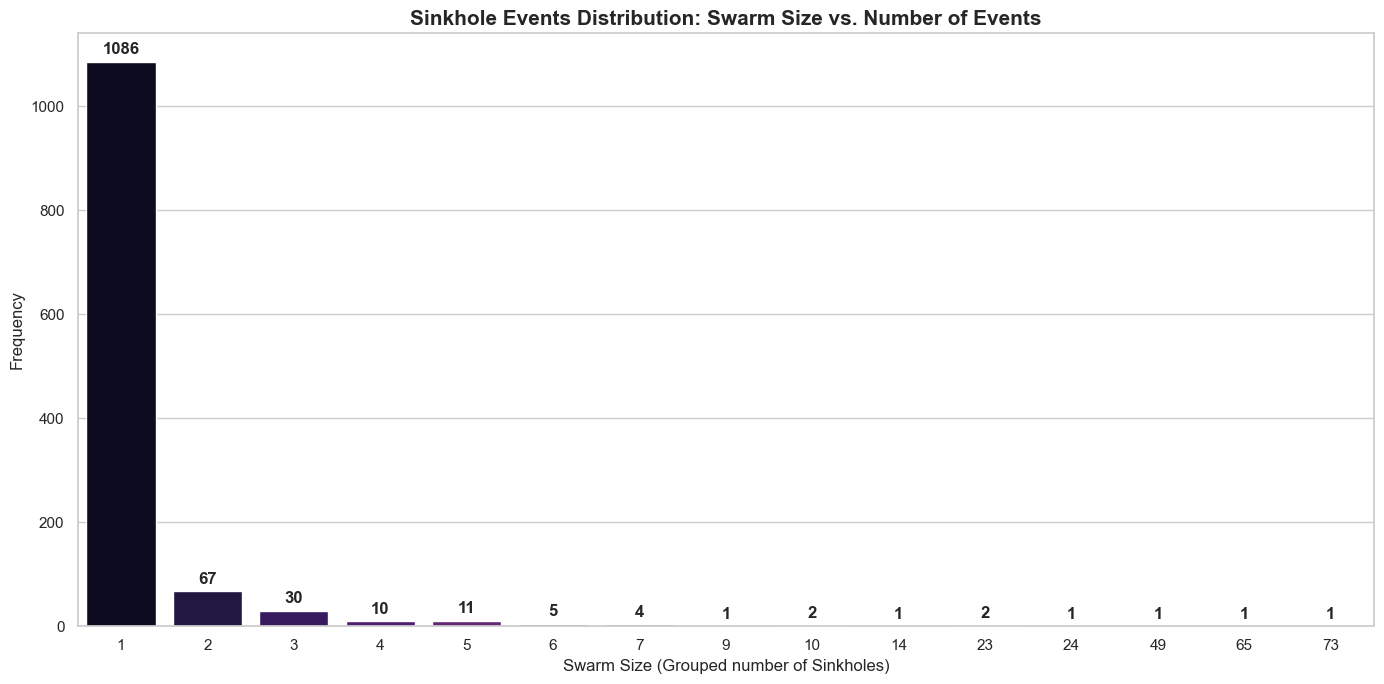

In [130]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import cdist

print("--- EJECUTANDO ALGORITMO KNN PARA AUDITORÍA DE ENJAMBRES ---")

# 1. Preparación de datos (Excluir nulos)
df_spatial = df_mag.dropna(subset=['x_laea', 'y_laea', 'number_sinkholes_clean']).copy()

# Variables para el tracking
df_spatial['ID_Evento_Real'] = -1
df_spatial['Distancia_Max_Cluster_m'] = 0.0
current_event_id = 0

# =================================================================================
# PASO A: Eventos aislados (Tamaño == 1)
# =================================================================================
mask_single = df_spatial['number_sinkholes_clean'] == 1
n_singles = mask_single.sum()
df_spatial.loc[mask_single, 'ID_Evento_Real'] = range(current_event_id, current_event_id + n_singles)
current_event_id += n_singles

# =================================================================================
# PASO B: Agrupamiento KNN para los Enjambres (> 1)
# =================================================================================
enjambres_df = df_spatial[df_spatial['number_sinkholes_clean'] > 1]
huerfanos_totales = 0

for n_sinkholes, group in enjambres_df.groupby('number_sinkholes_clean'):
    K = int(n_sinkholes)
    unassigned_idx = group.index.tolist()
    
    while len(unassigned_idx) > 0:
        # Si no alcanzan los puntos para formar el grupo de tamaño K, quedan huérfanos
        if len(unassigned_idx) < K:
            df_spatial.loc[unassigned_idx, 'ID_Evento_Real'] = -2 
            huerfanos_totales += len(unassigned_idx)
            break
            
        # Tomar "semilla" y buscar sus vecinos más cercanos
        seed_idx = unassigned_idx[0]
        seed_coords = df_spatial.loc[seed_idx, ['x_laea', 'y_laea']].values.astype(float).reshape(1, 2)
        candidate_coords = df_spatial.loc[unassigned_idx, ['x_laea', 'y_laea']].values.astype(float)
        
        distancias = cdist(seed_coords, candidate_coords)[0]
        closest_k_relative = np.argsort(distancias)[:K]
        closest_k_absolute = [unassigned_idx[i] for i in closest_k_relative]
        
        # Calcular extensión física (en metros) de este nuevo grupo
        cluster_coords = df_spatial.loc[closest_k_absolute, ['x_laea', 'y_laea']].values.astype(float)
        max_dist_in_cluster = np.max(cdist(cluster_coords, cluster_coords))
        
        # Registrar resultados
        df_spatial.loc[closest_k_absolute, 'ID_Evento_Real'] = current_event_id
        df_spatial.loc[closest_k_absolute, 'Distancia_Max_Cluster_m'] = max_dist_in_cluster
        
        current_event_id += 1
        
        # Remover los puntos agrupados de la lista de pendientes
        for idx in closest_k_absolute:
            unassigned_idx.remove(idx)

# =================================================================================
# PASO C: Generar Tabla de Extensión de Enjambres (En Kilómetros)
# =================================================================================
df_enjambres_formados = df_spatial[df_spatial['ID_Evento_Real'] >= n_singles].drop_duplicates('ID_Evento_Real').copy()
df_enjambres_formados['Distancia_Max_Cluster_km'] = df_enjambres_formados['Distancia_Max_Cluster_m'] / 1000

tabla_extension = df_enjambres_formados[['ID_Evento_Real', 'number_sinkholes_clean', 'Distancia_Max_Cluster_km']].sort_values('Distancia_Max_Cluster_km', ascending=False)
tabla_extension['number_sinkholes_clean'] = tabla_extension['number_sinkholes_clean'].astype(int)
tabla_extension['Distancia_Max_Cluster_km'] = tabla_extension['Distancia_Max_Cluster_km'].round(3)

print("\n--- TOP 15: ENJAMBRES CON MAYOR EXTENSIÓN FÍSICA ---")
print(tabla_extension.head(15).to_string(index=False))
print(f"\nResumen: {len(df_enjambres_formados)} enjambres agrupados | {huerfanos_totales} puntos huérfanos.")

# =================================================================================
# PASO D: Gráfico de Barras (Tamaño vs Cantidad Real de Eventos)
# =================================================================================
# Agrupamos todos los eventos (aislados + enjambres válidos)
df_all_events = df_spatial[df_spatial['ID_Evento_Real'] >= 0].drop_duplicates('ID_Evento_Real')
event_counts = df_all_events['number_sinkholes_clean'].value_counts().reset_index()
event_counts.columns = ['Tamanio_Enjambre', 'Cantidad_Eventos']
event_counts['Tamanio_Enjambre'] = event_counts['Tamanio_Enjambre'].astype(int)
event_counts = event_counts.sort_values('Tamanio_Enjambre')

plt.figure(figsize=(14, 7))
sns.set_theme(style="whitegrid")

# Crear el gráfico de barras
ax = sns.barplot(data=event_counts, x='Tamanio_Enjambre', y='Cantidad_Eventos', palette='magma')

plt.title('Sinkhole Events Distribution: Swarm Size vs. Number of Events', fontsize=15, fontweight='bold')
plt.xlabel('Swarm Size (Grouped number of Sinkholes)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)

# Añadir las etiquetas numéricas exactas sobre cada barra
for container in ax.containers:
    ax.bar_label(container, fmt='%d', padding=3, fontweight='bold')

plt.tight_layout()
plt.show()

In [131]:
df_spatial.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1801 entries, 0 to 1813
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id_bd_sinkhole           1801 non-null   object 
 1   x_laea                   1801 non-null   float64
 2   y_laea                   1801 non-null   float64
 3   length_diameter_m        1662 non-null   object 
 4   depth_of_the_sinkhole_m  1580 non-null   object 
 5   origin_of_collapse       1779 non-null   object 
 6   number_of_sinkholes      1801 non-null   object 
 7   number_sinkholes_clean   1801 non-null   float64
 8   diameter_sinkhole_clean  1201 non-null   float64
 9   depth_sinkhole_clean     1484 non-null   float64
 10  origin_collapse_clean    1287 non-null   object 
 11  ID_Evento_Real           1801 non-null   int64  
 12  Distancia_Max_Cluster_m  1801 non-null   float64
dtypes: float64(6), int64(1), object(6)
memory usage: 261.5+ KB


In [132]:
df_spatial[df_spatial["ID_Evento_Real"] == 1151]

,id_bd_sinkhole,x_laea,y_laea,length_diameter_m,depth_of_the_sinkhole_m,origin_of_collapse,number_of_sinkholes,number_sinkholes_clean,diameter_sinkhole_clean,depth_sinkhole_clean,origin_collapse_clean,ID_Evento_Real,Distancia_Max_Cluster_m
1735,POL-SIN- 827,4.977113e+06,3.054095e+06,0.2,NaN,Faillure of the roof room or roof gallery,2,2.0,0.2,NaN,faillure of the roof room or roof gallery,1151,24.092744
1779,POL-SIN- 871,4.977090e+06,3.054091e+06,2,4,Collapse of the shaft filling material,2,2.0,2.0,4.0,collapse of the shaft filling material,1151,24.092744
